In [1]:
import pandas as pd 
pd.options.mode.chained_assignment = None  # default='warn'
import numpy as np 
import matplotlib.pyplot as plt 
import matplotlib.patches as mpatches
import matplotlib.colors as mcolors
from matplotlib.markers import MarkerStyle
import seaborn as sns 
import pickle 
from sklearn import metrics 
import sys 
import scipy.stats
import glob
import copy
import time 
import json
from sklearn.metrics import auc, roc_curve, roc_auc_score
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.decomposition import PCA

from config import (llm_review_path, home_path, supp_table_path, figure_path_2)

sys.path.insert(1, home_path)
from common_functions import sort_dict_by_value,format_p, mean_confidence_interval, entropy, sort_dict_by_key, my_colors

data_path =  "../../../revisions/data/orphanage/orphanage_extractions/"

data_output_path = llm_review_path + "source_data_csvs/"



In [4]:

def p_val_to_stars(p):
    if p <= 0.001:
        return "***"
    if p <= 0.01:
        return "**"
    if p <= 0.05:
        return "*"
    return "ns"

In [5]:
model_to_mean_pool_res = {}

wanted_pool_method = "mean_pooled"


wanted_model_list = ["carp_640M", "carp_38M", "carp_76M", "prott5_xl", "esm_1b", "esm_1_43M", "esm_1_85M","esm_1_UR50",  "esm_1_UR50D"]

for wanted_model in wanted_model_list:

    with open(data_path + wanted_model  + "/all_romote_homologs_seqeunces.pkl", "rb") as f1:
        data = pickle.load(f1)
    f1.close()


    dfa = pd.read_csv(supp_table_path + "top_bottom_homologs_pairs_scope_distances.csv")
    # can choose any model, just need the annotations
    bottom_100_pairs = dfa.loc[(dfa["model"] == "ESM-2 (8M)") & (dfa["group_annotation"] == "bottom_100")]
    top_100_pairs = dfa.loc[(dfa["model"] == "ESM-2 (8M)") & (dfa["group_annotation"] == "top_100")]
    
    top_100_list = []
    for index, row in top_100_pairs.iterrows():
        p1 = row["protein_1"]
        p2 = row["protein_2"]

        emb_1 = data[p1][wanted_pool_method]
        emb_2 = data[p2][wanted_pool_method]

        cos_sim = cosine_similarity([emb_1], [emb_2])[0][0]

        top_100_list.append(cos_sim)


    bottom_100_list = []
    for index, row in bottom_100_pairs.iterrows():
        p1 = row["protein_1"]
        p2 = row["protein_2"]

        emb_1 = data[p1][wanted_pool_method]
        emb_2 = data[p2][wanted_pool_method]

        cos_sim = cosine_similarity([emb_1], [emb_2])[0][0]

        bottom_100_list.append(cos_sim)

    model_to_mean_pool_res[wanted_model] = {"top" : top_100_list, "bottom" : bottom_100_list}
    
    
dfa = pd.read_csv(supp_table_path + "top_bottom_homologs_pairs_scope_distances.csv")

for m, sub_df in dfa.groupby("model"):
    top_selections = sub_df.loc[sub_df["group_annotation"] == "top_100"]
    bottom_selections = sub_df.loc[sub_df["group_annotation"] == "bottom_100"]
    
    model_to_mean_pool_res[m] = {
        "top" : top_selections["cos_sim_mean_pool"].values, 
        "bottom" : bottom_selections["cos_sim_mean_pool"].values
    }


In [6]:
data = []

for m, v in model_to_mean_pool_res.items():
    print(m, np.mean(v["top"]), np.mean(v["bottom"]), scipy.stats.mannwhitneyu(v["top"], v["bottom"], alternative = "less"))

carp_640M 0.9744758651855889 0.9906669789548127 MannwhitneyuResult(statistic=620.0, pvalue=5.043985484756737e-27)
carp_38M 0.9511984961475213 0.9906528533506951 MannwhitneyuResult(statistic=68.0, pvalue=9.74794526550478e-34)
carp_76M 0.9527368448943015 0.9899439183437216 MannwhitneyuResult(statistic=225.0, pvalue=9.512222393271616e-32)
prott5_xl 0.25195256 0.3166484 MannwhitneyuResult(statistic=3722.0, pvalue=0.0008998772757918378)
esm_1b 0.9403852 0.9680378 MannwhitneyuResult(statistic=1298.0, pvalue=7.537979113143838e-20)
esm_1_43M 0.7487573 0.96067834 MannwhitneyuResult(statistic=126.0, pvalue=5.385579462377092e-33)
esm_1_85M 0.7594618 0.9607152 MannwhitneyuResult(statistic=176.0, pvalue=2.3131814370256692e-32)
esm_1_UR50 0.8117992 0.9602166 MannwhitneyuResult(statistic=236.0, pvalue=1.3040232366917122e-31)
esm_1_UR50D 0.81920767 0.9601702 MannwhitneyuResult(statistic=210.0, pvalue=6.179555373816558e-32)
ESM-2 (150M) 0.851450824 0.9302720579 MannwhitneyuResult(statistic=1011.0, pval

In [8]:

model_to_cls_pool_res = {}

wanted_pool_method = "cls_pooled"


wanted_model_list = ["esm_1b", "esm_1_43M", "esm_1_85M","esm_1_UR50",  "esm_1_UR50D"]

for wanted_model in wanted_model_list:

    with open(data_path + wanted_model  + "/all_romote_homologs_seqeunces.pkl", "rb") as f1:
        data = pickle.load(f1)
    f1.close()


    dfa = pd.read_csv(supp_table_path + "top_bottom_homologs_pairs_scope_distances.csv")
    # can choose any model, just need the annotations
    bottom_100_pairs = dfa.loc[(dfa["model"] == "ESM-2 (8M)") & (dfa["group_annotation"] == "bottom_100")]
    top_100_pairs = dfa.loc[(dfa["model"] == "ESM-2 (8M)") & (dfa["group_annotation"] == "top_100")]


    top_100_list = []
    for index, row in top_100_pairs.iterrows():
        p1 = row["protein_1"]
        p2 = row["protein_2"]

        emb_1 = data[p1][wanted_pool_method]
        emb_2 = data[p2][wanted_pool_method]

        cos_sim = cosine_similarity([emb_1], [emb_2])[0][0]

        top_100_list.append(cos_sim)


    bottom_100_list = []
    for index, row in bottom_100_pairs.iterrows():
        p1 = row["protein_1"]
        p2 = row["protein_2"]

        emb_1 = data[p1][wanted_pool_method]
        emb_2 = data[p2][wanted_pool_method]

        cos_sim = cosine_similarity([emb_1], [emb_2])[0][0]

        bottom_100_list.append(cos_sim)

    model_to_cls_pool_res[wanted_model] = {"top" : top_100_list, "bottom" : bottom_100_list}
    
    
dfa = pd.read_csv(supp_table_path + "top_bottom_homologs_pairs_scope_distances.csv")

for m, sub_df in dfa.groupby("model"):
    top_selections = sub_df.loc[sub_df["group_annotation"] == "top_100"]
    bottom_selections = sub_df.loc[sub_df["group_annotation"] == "bottom_100"]
    
    model_to_cls_pool_res[m] = {
        "top" : top_selections["cos_sim_cls"].values, 
        "bottom" : bottom_selections["cos_sim_cls"].values
    }



In [9]:
data = []

for m, v in model_to_cls_pool_res.items():
    print(m, np.mean(v["top"]), np.mean(v["bottom"]), scipy.stats.mannwhitneyu(v["top"], v["bottom"], alternative = "less"))

esm_1b 0.98339516 0.9902746 MannwhitneyuResult(statistic=1686.0, pvalue=2.835848992605382e-16)
esm_1_43M 0.9881483 0.9945305 MannwhitneyuResult(statistic=1065.0, pvalue=3.5057345043736545e-22)
esm_1_85M 0.951051 0.98663735 MannwhitneyuResult(statistic=499.0, pvalue=1.9868876968506594e-28)
esm_1_UR50 0.9044492 0.9547765 MannwhitneyuResult(statistic=1115.0, pvalue=1.1403706207314743e-21)
esm_1_UR50D 0.91683877 0.9583639 MannwhitneyuResult(statistic=1271.0, pvalue=4.112442005207329e-20)
ESM-2 (150M) 0.9447549568999999 0.9623361765000001 MannwhitneyuResult(statistic=2246.0, pvalue=8.60815446841717e-12)
ESM-2 (15B) 0.8781116315000002 0.9076831514999999 MannwhitneyuResult(statistic=2819.0, pvalue=4.9702159006459875e-08)
ESM-2 (35M) 0.9273313360000001 0.9523423116 MannwhitneyuResult(statistic=1926.0, pvalue=2.961889267278365e-14)
ESM-2 (3B) 0.9854326671000001 0.9897003384999998 MannwhitneyuResult(statistic=2506.0, pvalue=5.554910685524252e-10)
ESM-2 (650M) 0.9685936287999998 0.9784313863 Mann

In [11]:


column_wise_results = {}

wanted_model_list = [
    "carp_640M", 
    "carp_38M", 
    "carp_76M", 
    "prott5_xl", 
    "esm_1b", 
    "esm_1_43M", 
    "esm_1_85M",
    "esm_1_UR50",  
    "esm_1_UR50D"
]

for wanted_model in wanted_model_list:

    with open(data_path + wanted_model  + "/selected_full_seqs_all_groups.pkl", "rb") as f1:
        data = pickle.load(f1)
    f1.close()


    dfa = pd.read_csv(supp_table_path + "top_bottom_homologs_pairs_scope_distances.csv")
    # can choose any model, just need the annotations
    bottom_100_pairs = dfa.loc[(dfa["model"] == "ESM-2 (8M)") & (dfa["group_annotation"] == "bottom_100")]
    top_100_pairs = dfa.loc[(dfa["model"] == "ESM-2 (8M)") & (dfa["group_annotation"] == "top_100")]


    top_100_list = []
    for index, row in top_100_pairs.iterrows():
        p1 = row["protein_1"]
        p2 = row["protein_2"]

        emb_1 = data["top_100_scope"][p1]
        emb_2 = data["top_100_scope"][p2]
        
        min_length = min(np.shape(emb_1)[0], np.shape(emb_2)[0])
        
        for i in range(min_length):
            x1 = emb_1[i]
            x2 = emb_2[i]
            cos_sim = cosine_similarity([x1], [x2])[0][0]
            top_100_list.append(cos_sim)
    
    
    bottom_100_list = []
    for index, row in bottom_100_pairs.iterrows():
        p1 = row["protein_1"]
        p2 = row["protein_2"]

        emb_1 = data["bottom_100_scope"][p1]
        emb_2 = data["bottom_100_scope"][p2]
        
        min_length = min(np.shape(emb_1)[0], np.shape(emb_2)[0])
        
        for i in range(min_length):
            x1 = emb_1[i]
            x2 = emb_2[i]
            cos_sim = cosine_similarity([x1], [x2])[0][0]
            bottom_100_list.append(cos_sim)


    column_wise_results[wanted_model] = {"top" : top_100_list, "bottom" : bottom_100_list}
     

dfa = pd.read_csv(supp_table_path + "top_bottom_homologs_pairs_scope_distances.csv")

for m, sub_df in dfa.groupby("model"):
    top_selections = sub_df.loc[sub_df["group_annotation"] == "top_100"]
    bottom_selections = sub_df.loc[sub_df["group_annotation"] == "bottom_100"]
    
    
    col_dists_top = []
    
    for v in top_selections["cos_sim_column_wise"].values:
        v = list(map(lambda x : float(x), v.split("|")))
        for value in v:
            col_dists_top.append(value)
            
    col_dists_bottom = []
    
    for v in bottom_selections["cos_sim_column_wise"].values:
        v = list(map(lambda x : float(x), v.split("|")))
        for value in v:
            col_dists_bottom.append(value)
            
    column_wise_results[m] = {
        "top" : col_dists_top, 
        "bottom" : col_dists_bottom
    }   
    


In [12]:
np.shape(emb_2), min_length

((47, 1280), 47)

In [13]:
data = []

for m, v in column_wise_results.items():
    print(m, np.mean(v["top"]), np.mean(v["bottom"]), scipy.stats.mannwhitneyu(v["top"], v["bottom"], alternative = "less"))

carp_640M 0.858956 0.9561726 MannwhitneyuResult(statistic=8118629.5, pvalue=0.0)
carp_38M 0.8135521 0.9615879 MannwhitneyuResult(statistic=3268207.5, pvalue=0.0)
carp_76M 0.80847424 0.9489252 MannwhitneyuResult(statistic=4452409.0, pvalue=0.0)
prott5_xl 0.034026712 0.04145573 MannwhitneyuResult(statistic=59981112.5, pvalue=3.897473886421386e-10)
esm_1b 0.7840091 0.88245404 MannwhitneyuResult(statistic=8086638.5, pvalue=0.0)
esm_1_43M 0.47713417 0.8053632 MannwhitneyuResult(statistic=5396353.0, pvalue=0.0)
esm_1_85M 0.4568466 0.85835385 MannwhitneyuResult(statistic=4556067.5, pvalue=0.0)
esm_1_UR50 0.44537768 0.81526506 MannwhitneyuResult(statistic=6729697.0, pvalue=0.0)
esm_1_UR50D 0.4452348 0.80228233 MannwhitneyuResult(statistic=7016842.0, pvalue=0.0)
ESM-2 (150M) 0.4698001822672686 0.7122646699608428 MannwhitneyuResult(statistic=11304438.0, pvalue=0.0)
ESM-2 (15B) 0.09809478323822501 0.17744045217229162 MannwhitneyuResult(statistic=25780009.0, pvalue=0.0)
ESM-2 (35M) 0.3894294208329

In [15]:
for m, v in column_wise_results.items():
    print("\"" +  m +"\""  )

"carp_640M"
"carp_38M"
"carp_76M"
"prott5_xl"
"esm_1b"
"esm_1_43M"
"esm_1_85M"
"esm_1_UR50"
"esm_1_UR50D"
"ESM-2 (150M)"
"ESM-2 (15B)"
"ESM-2 (35M)"
"ESM-2 (3B)"
"ESM-2 (650M)"
"ESM-2 (8M)"


In [16]:
model_to_display_a = {
    "carp_640M" : "CARP\n640M",
    "carp_38M": "CARP\n38M",
    "carp_76M": "CARP\n76M",
    "prott5_xl" : "ProtT5\n3B",
    "esm_1b": "ESM-1b\n650M",
    "esm_1_43M": "ESM-1\n43M",
    "esm_1_85M": "ESM-1\n85M",
    "esm_1_UR50": "ESM-1(S)\n670M",
    "esm_1_UR50D": "ESM-1(D)\n670M",
    "ESM-2 (150M)": "ESM-2\n150M",
    "ESM-2 (15B)": "ESM-2\n15B",
    "ESM-2 (35M)": "ESM-2\n35M",
    "ESM-2 (3B)": "ESM-2\n3B",
    "ESM-2 (650M)": "ESM-2\n650M",
    "ESM-2 (8M)": "ESM-2\n8M",
}

carp_640M 5.04 x 10^{-27}
carp_38M 9.75 x 10^{-34}
carp_76M 9.51 x 10^{-32}
esm_1_43M 5.39 x 10^{-33}
esm_1_85M 2.31 x 10^{-32}
esm_1_UR50 1.3 x 10^{-31}
esm_1_UR50D 6.18 x 10^{-32}
esm_1b 7.54 x 10^{-20}
ESM-2 (8M) 4.24 x 10^{-19}
ESM-2 (35M) 8.32 x 10^{-27}
ESM-2 (150M) 9.65 x 10^{-23}
ESM-2 (650M) 4.65 x 10^{-25}
ESM-2 (3B) 3.93 x 10^{-20}
ESM-2 (15B) 2.14 x 10^{-05}
prott5_xl 0.0009


/tmp/ipykernel_1803507/2184241559.py:60: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_1803507/2184241559.py:76: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(ax.get_yticklabels(), fontweight = "bold")


Text(0.5, 1.04, 'SCOPe Proteins From Different Folds\nTop 100 vs. bottom 100 homolog representation')

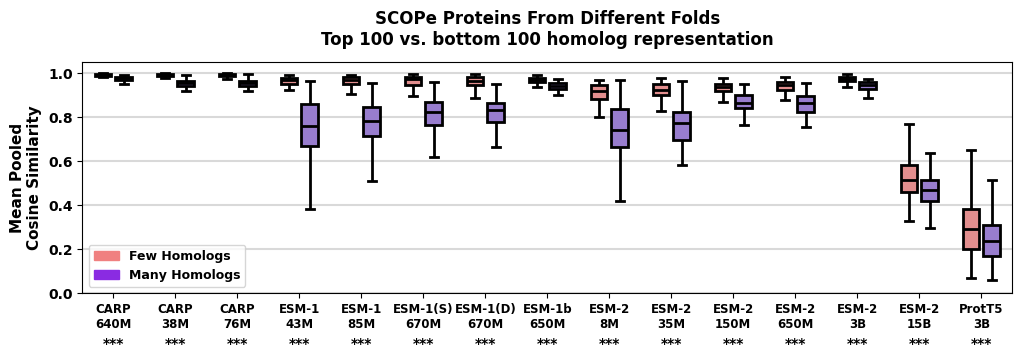

In [17]:
data = []
x = []
my_pal = []
x_ticklabels = []
p_strings = []
stars = []

models_in_question = [
    "carp_640M",
    "carp_38M",
    "carp_76M",
    "esm_1_43M",
    "esm_1_85M",
    "esm_1_UR50",
    "esm_1_UR50D",
    "esm_1b",
    "ESM-2 (8M)",
    "ESM-2 (35M)",
    "ESM-2 (150M)",
    "ESM-2 (650M)",
    "ESM-2 (3B)",
    "ESM-2 (15B)",
    "prott5_xl",
]

fig, ax = plt.subplots(figsize = (len(models_in_question)*0.8,3))

data_export_list = []

for i, m in enumerate(models_in_question):
    x = x + [i*3, (i*3) + 1, (i*3) + 2]
    
    x1 = model_to_mean_pool_res[m]["bottom"]
    x2 = model_to_mean_pool_res[m]["top"]
    
    data.append(x1)
    data.append(x2)
    data.append([])
    my_pal.append("lightcoral")
    my_pal.append("mediumpurple")
    my_pal.append("white")
    x_ticklabels.append(model_to_display_a[m])
    
    _, p = scipy.stats.mannwhitneyu(
         x1,
         x2,
         alternative = "greater"
    )
    print(m, format_p(p))
    p_strings.append(r"$p = " + format_p(p) + "$")
    stars.append(p_val_to_stars(p))
    
    data_export_list.append([
        model_to_display_a[m].replace("\n", " "), 
        "|".join(list(map(lambda x: str(x), x1))),
        "|".join(list(map(lambda x: str(x), x2))),
         p
    ])
    
sns.boxplot(
    data, 
    color = "white", 
    boxprops=dict(linewidth=2, edgecolor='black', zorder = 100),
    medianprops=dict(linewidth=2, color='black', zorder = 100),
    whiskerprops=dict(linewidth=2, color='black', zorder = 100),
    capprops = dict(linewidth=2, color='black', zorder = 100),
    showfliers = False,
    palette = my_pal
)


x_ticks = np.arange(0.5, (len(models_in_question)*3) + 0.001, 3)
ax.set_xticks(x_ticks)
ax.set_xticklabels(x_ticklabels, fontsize = 8.5, fontweight = "bold")
ax.set_ylim(top=1.05, bottom = 0)
ax.set_yticklabels(ax.get_yticklabels(), fontweight = "bold")

for y_val in ax.get_yticks():
    ax.axhline(y = y_val, color = "black", alpha = 0.15)

## use this for the stars
for xpos, text in zip(x_ticks, stars):
    ax.text(xpos, -0.25, text, horizontalalignment = "center", fontsize = 10, fontweight = "bold")

ax.set_xlim(left = -1, right = len(data) - 1)

ax.set_ylabel("Mean Pooled\nCosine Similarity", fontsize = 11, fontweight = "bold")

coral_patch = mpatches.Patch(color="lightcoral", label='Few Homologs')
purple_patch = mpatches.Patch(color="blueviolet", label='Many Homologs')

ax.legend(handles=[coral_patch,purple_patch], loc = "lower left", prop = {"weight" : "bold", "size" : 9},)
ax.set_title(f"SCOPe Proteins From Different Folds\nTop 100 vs. bottom 100 homolog representation", y =1.04, fontweight = "bold")



In [18]:
# fig E8a
data_df_out = pd.DataFrame(data_export_list, columns = ["model", "low_homog_group", "high_homolog_group", "one_sided_mwu_p"])
data_df_out.to_csv(data_output_path + "fig_E8/data_E8a.csv", index = False)
data_df_out

,model,low_homog_group,high_homolog_group,one_sided_mwu_p
0,CARP 640M,0.9972737388939291|0.9948739901278237|0.996134...,0.9872959478601574|0.9457402764541905|0.974534...,5.043985e-27
1,CARP 38M,0.996316695959866|0.9892120299585361|0.9944313...,0.9607778179600549|0.9721779251927367|0.990882...,9.747945e-34
2,CARP 76M,0.9970721558335789|0.9859845376980065|0.994952...,0.9590695266411964|0.9201963813433607|0.993303...,9.512222e-32
3,ESM-1 43M,0.9833623|0.9682084|0.97319305|0.95979637|0.98...,0.81074405|0.80134493|0.90367466|0.4477736|0.7...,5.385579e-33
4,ESM-1 85M,0.99207664|0.97339153|0.9705163|0.967716|0.987...,0.87037414|0.34436542|0.95649874|0.67469025|0....,2.313181e-32
5,ESM-1(S) 670M,0.9939335|0.98442173|0.9873264|0.98080724|0.99...,0.8829173|0.75329304|0.78300864|0.8587783|0.69...,1.304023e-31
6,ESM-1(D) 670M,0.9941372|0.98472583|0.97054434|0.9842783|0.97...,0.89565134|0.7520434|0.80406684|0.81888896|0.7...,6.179555e-32
7,ESM-1b 650M,0.99091244|0.97519517|0.98361415|0.9783531|0.9...,0.97305036|0.9014891|0.9498704|0.9510886|0.903...,7.537979e-20
8,ESM-2 8M,0.9547068|0.8938077|0.90982974|0.8712782|0.948...,0.74527645|0.7405325|0.91294634|0.91022277|0.7...,4.236289e-19
9,ESM-2 35M,0.9709722|0.9217094|0.93906194|0.87725806|0.96...,0.8417451|0.8284095|0.92620426|0.7974504|0.787...,8.315928e-27


carp_640M < 10^{-256}
carp_38M < 10^{-256}
carp_76M < 10^{-256}
esm_1_43M < 10^{-256}
esm_1_85M < 10^{-256}
esm_1_UR50 < 10^{-256}
esm_1_UR50D < 10^{-256}
esm_1b < 10^{-256}
ESM-2 (8M) < 10^{-256}
ESM-2 (35M) < 10^{-256}
ESM-2 (150M) < 10^{-256}
ESM-2 (650M) < 10^{-256}
ESM-2 (3B) < 10^{-256}
ESM-2 (15B) < 10^{-256}
prott5_xl 3.9 x 10^{-10}


/tmp/ipykernel_1803507/3794721205.py:63: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_1803507/3794721205.py:79: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(ax.get_yticklabels(), fontweight = "bold")


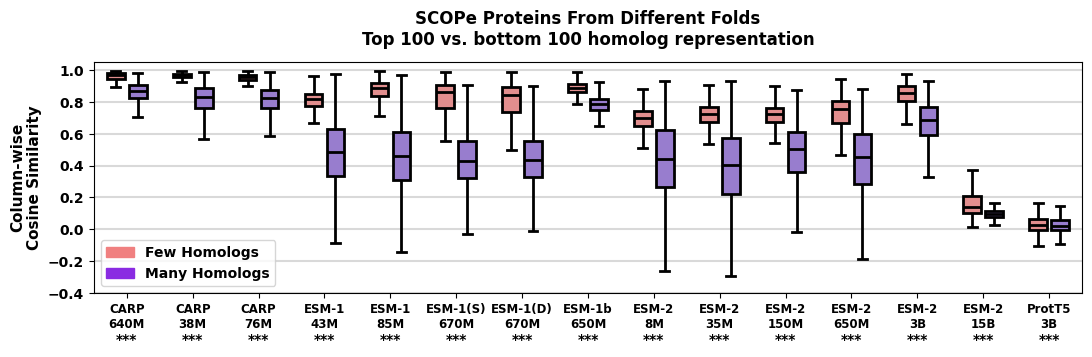

In [19]:
data = []
x = []
my_pal = []
x_ticklabels = []
p_strings = []
stars = []

models_in_question = [
    "carp_640M",
    "carp_38M",
    "carp_76M",
    "esm_1_43M",
    "esm_1_85M",
    "esm_1_UR50",
    "esm_1_UR50D",
    "esm_1b",
    "ESM-2 (8M)",
    "ESM-2 (35M)",
    "ESM-2 (150M)",
    "ESM-2 (650M)",
    "ESM-2 (3B)",
    "ESM-2 (15B)",
    "prott5_xl",
]

data_export_list = []

fig, ax = plt.subplots(figsize = (len(models_in_question)*0.85,3))




for i, m in enumerate(models_in_question):
    x = x + [i*3, (i*3) + 1, (i*3) + 2]
    
    x1 = column_wise_results[m]["bottom"]
    x2 = column_wise_results[m]["top"]
    
    data.append(x1)
    data.append(x2)
    data.append([])
    my_pal.append("lightcoral")
    my_pal.append("mediumpurple")
    my_pal.append("white")
    x_ticklabels.append(model_to_display_a[m])
    
    _, p = scipy.stats.mannwhitneyu(
         x1,
         x2,
         alternative = "greater"
    )
    print(m, format_p(p))
    p_strings.append(r"$p = " + format_p(p) + "$")
    stars.append(p_val_to_stars(p))
    
    data_export_list.append([
        model_to_display_a[m].replace("\n", " "), 
        "|".join(list(map(lambda x: str(x), x1))),
        "|".join(list(map(lambda x: str(x), x2))),
         p
    ])
    
sns.boxplot(
    data, 
    color = "white", 
    boxprops=dict(linewidth=2, edgecolor='black', zorder = 100),
    medianprops=dict(linewidth=2, color='black', zorder = 100),
    whiskerprops=dict(linewidth=2, color='black', zorder = 100),
    capprops = dict(linewidth=2, color='black', zorder = 100),
    showfliers = False,
    palette = my_pal
)


x_ticks = np.arange(0.5, (len(models_in_question)*3) + 0.001, 3)
ax.set_xticks(x_ticks)
ax.set_xticklabels(x_ticklabels, fontsize = 8.5, fontweight = "bold")
ax.set_ylim(top=1.05, bottom = -0.4)
ax.set_yticklabels(ax.get_yticklabels(), fontweight = "bold")

ax.set_xlim(left = -1, right = len(data) - 1)

for y_val in ax.get_yticks():
    ax.axhline(y = y_val, color = "black", alpha = 0.15)

ax.set_ylabel("Column-wise\nCosine Similarity", fontsize = 11, fontweight = "bold")

coral_patch = mpatches.Patch(color="lightcoral", label='Few Homologs')
purple_patch = mpatches.Patch(color="blueviolet", label='Many Homologs')

ax.legend(handles=[coral_patch,purple_patch], loc = "lower left", prop = {"weight" : "bold", "size" : 10},)
ax.set_title(f"SCOPe Proteins From Different Folds\nTop 100 vs. bottom 100 homolog representation", y =1.04, fontweight = "bold")

## use this for the stars
for xpos, text in zip(x_ticks, stars):
    ax.text(xpos, -0.72, text, horizontalalignment = "center", fontsize = 10, fontweight = "bold")


In [20]:
# fig E8c
data_df_out = pd.DataFrame(data_export_list, columns = ["model", "low_homog_group", "high_homolog_group", "one_sided_mwu_p"])
data_df_out.to_csv(data_output_path + "fig_E8/data_E8c.csv", index = False)
data_df_out

,model,low_homog_group,high_homolog_group,one_sided_mwu_p
0,CARP 640M,0.9863033|0.98399675|0.98353523|0.98659796|0.9...,0.9356359|0.9325144|0.9405335|0.92295176|0.917...,0.000000e+00
1,CARP 38M,0.99292886|0.9803884|0.98428226|0.9872646|0.98...,0.9467893|0.9220184|0.9351102|0.92715293|0.918...,0.000000e+00
2,CARP 76M,0.99191236|0.9748271|0.97458535|0.9813224|0.96...,0.9364873|0.90477103|0.9226289|0.9021528|0.903...,0.000000e+00
3,ESM-1 43M,0.9819004|0.9119929|0.91162926|0.8680202|0.883...,0.90654635|0.515299|0.5691658|0.43298993|0.529...,0.000000e+00
4,ESM-1 85M,0.9853078|0.96086097|0.9528506|0.939806|0.9534...,0.8639017|0.70844424|0.6857196|0.6553371|0.655...,0.000000e+00
5,ESM-1(S) 670M,0.9823169|0.96659863|0.9507034|0.93686026|0.94...,0.836968|0.76595414|0.6687854|0.59149045|0.551...,0.000000e+00
6,ESM-1(D) 670M,0.9846793|0.9743915|0.9391111|0.9342953|0.9177...,0.8889452|0.81402135|0.6972599|0.5942241|0.591...,0.000000e+00
7,ESM-1b 650M,0.98508966|0.94910496|0.93706095|0.94093585|0....,0.90880805|0.8649242|0.87244374|0.83257145|0.8...,0.000000e+00
8,ESM-2 8M,0.90674|0.74557|0.78409|0.80236|0.76416|0.8274...,0.50678|0.40021|0.42129|0.39234|0.38815|0.3874...,0.000000e+00
9,ESM-2 35M,0.93194|0.79537|0.777|0.80312|0.77235|0.83735|...,0.73074|0.72052|0.66807|0.67903|0.72793|0.7423...,0.000000e+00


esm_1_43M 3.51 x 10^{-22}
esm_1_85M 1.99 x 10^{-28}
esm_1_UR50 1.14 x 10^{-21}
esm_1_UR50D 4.11 x 10^{-20}
esm_1b 2.84 x 10^{-16}
ESM-2 (8M) 1.42 x 10^{-14}
ESM-2 (35M) 2.96 x 10^{-14}
ESM-2 (150M) 8.61 x 10^{-12}
ESM-2 (650M) 2.38 x 10^{-09}
ESM-2 (3B) 5.55 x 10^{-10}
ESM-2 (15B) 4.97 x 10^{-08}


/tmp/ipykernel_1803507/1113472286.py:63: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_1803507/1113472286.py:79: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(ax.get_yticklabels(), fontweight = "bold")


Text(0.5, 1.04, 'SCOPe Proteins From Different Folds\nTop 100 vs. bottom 100 homolog representation')

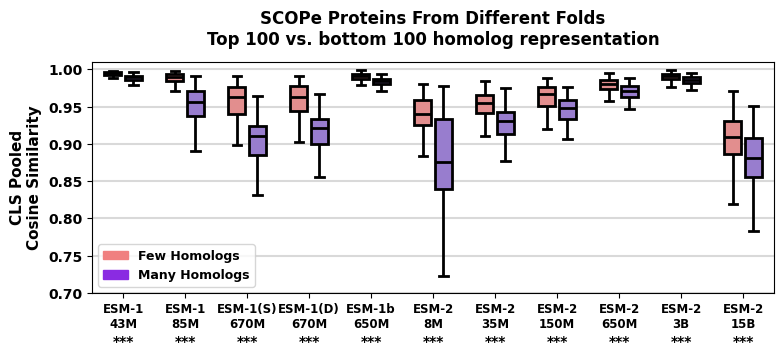

In [21]:
data = []
x = []
my_pal = []
x_ticklabels = []
p_strings = []
stars = []

models_in_question = [

    "esm_1_43M",
    "esm_1_85M",
    "esm_1_UR50",
    "esm_1_UR50D",
    "esm_1b",
    "ESM-2 (8M)",
    "ESM-2 (35M)",
    "ESM-2 (150M)",
    "ESM-2 (650M)",
    "ESM-2 (3B)",
    "ESM-2 (15B)",
]

data_export_list = []

fig, ax = plt.subplots(figsize = (len(models_in_question)*0.8,3))




for i, m in enumerate(models_in_question):
    x = x + [i*3, (i*3) + 1, (i*3) + 2]
    
    x1 = model_to_cls_pool_res[m]["bottom"]
    x2 = model_to_cls_pool_res[m]["top"]
    
    data.append(x1)
    data.append(x2)
    data.append([])
    my_pal.append("lightcoral")
    my_pal.append("mediumpurple")
    my_pal.append("white")
    x_ticklabels.append(model_to_display_a[m])
    
    _, p = scipy.stats.mannwhitneyu(
         x1,
         x2,
         alternative = "greater"
    )
    print(m, format_p(p))
    p_strings.append(r"$p = " + format_p(p) + "$")
    stars.append(p_val_to_stars(p))
    
    data_export_list.append([
        model_to_display_a[m].replace("\n", " "), 
        "|".join(list(map(lambda x: str(x), x1))),
        "|".join(list(map(lambda x: str(x), x2))),
         p
    ])
    
sns.boxplot(
    data, 
    color = "white", 
    boxprops=dict(linewidth=2, edgecolor='black', zorder = 100),
    medianprops=dict(linewidth=2, color='black', zorder = 100),
    whiskerprops=dict(linewidth=2, color='black', zorder = 100),
    capprops = dict(linewidth=2, color='black', zorder = 100),
    showfliers = False,
    palette = my_pal
)


x_ticks = np.arange(0.5, (len(models_in_question)*3) + 0.001, 3)
ax.set_xticks(x_ticks)
ax.set_xticklabels(x_ticklabels, fontsize = 8.5, fontweight = "bold")
ax.set_ylim(top=1.01, bottom = 0.7)
ax.set_yticklabels(ax.get_yticklabels(), fontweight = "bold")

for y_val in ax.get_yticks():
    ax.axhline(y = y_val, color = "black", alpha = 0.15)

## use this for the stars
for xpos, text in zip(x_ticks, stars):
    ax.text(xpos, 0.63, text, horizontalalignment = "center", fontsize = 10, fontweight = "bold")

ax.set_xlim(left = -1, right = len(data) - 1)

ax.set_ylabel("CLS Pooled\nCosine Similarity", fontsize = 11, fontweight = "bold")

coral_patch = mpatches.Patch(color="lightcoral", label='Few Homologs')
purple_patch = mpatches.Patch(color="blueviolet", label='Many Homologs')

ax.legend(handles=[coral_patch,purple_patch], loc = "lower left", prop = {"weight" : "bold", "size" : 9},)
ax.set_title(f"SCOPe Proteins From Different Folds\nTop 100 vs. bottom 100 homolog representation", y =1.04, fontweight = "bold")



In [22]:
data_df_out = pd.DataFrame(data_export_list, columns = ["model", "low_homog_group", "high_homolog_group", "one_sided_mwu_p"])
data_df_out.to_csv(data_output_path + "fig_E8/data_E8b.csv", index = False)
data_df_out

,model,low_homog_group,high_homolog_group,one_sided_mwu_p
0,ESM-1 43M,0.99818784|0.9920654|0.9959101|0.9925116|0.995...,0.9901927|0.9882319|0.98884964|0.98549455|0.99...,3.505735e-22
1,ESM-1 85M,0.99600494|0.9812545|0.98737395|0.98849005|0.9...,0.95543003|0.9498295|0.97891515|0.9417142|0.90...,1.986888e-28
2,ESM-1(S) 670M,0.99064964|0.974072|0.97280586|0.9686695|0.989...,0.9198816|0.84364426|0.92477024|0.91211253|0.8...,1.140371e-21
3,ESM-1(D) 670M,0.9895803|0.97721773|0.9676283|0.9738239|0.977...,0.92907965|0.88671654|0.9340631|0.9227688|0.87...,4.112442e-20
4,ESM-1b 650M,0.99839807|0.9928673|0.9963233|0.99485624|0.99...,0.9937534|0.98070943|0.984905|0.9879559|0.9713...,2.835849e-16
5,ESM-2 8M,0.96237487|0.9505465|0.95252967|0.88319683|0.9...,0.8210094|0.8078423|0.9473556|0.94057524|0.858...,1.423992e-14
6,ESM-2 35M,0.9812858|0.9681894|0.9649347|0.9384603|0.9814...,0.9342962|0.91585743|0.96248215|0.94298285|0.9...,2.961889e-14
7,ESM-2 150M,0.987848|0.98414886|0.97389317|0.9668349|0.972...,0.9091187|0.9224184|0.9664954|0.9565524|0.9216...,8.608154e-12
8,ESM-2 650M,0.9909625|0.989873|0.98862505|0.97967815|0.994...,0.95777565|0.9637889|0.97971827|0.9742447|0.95...,2.376720e-09
9,ESM-2 3B,0.99511886|0.9936323|0.9947353|0.99388546|0.99...,0.9823022|0.98023206|0.9849199|0.98470473|0.98...,5.554911e-10


carp_640M 5.04 x 10^{-27}
esm_1_UR50D 6.18 x 10^{-32}
esm_1b 7.54 x 10^{-20}
ESM-2 (150M) 9.65 x 10^{-23}
ESM-2 (650M) 4.65 x 10^{-25}
ESM-2 (3B) 3.93 x 10^{-20}
ESM-2 (15B) 2.14 x 10^{-05}
prott5_xl 0.0009


/tmp/ipykernel_1803507/1647643059.py:62: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_1803507/1647643059.py:78: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(ax.get_yticklabels(), fontweight = "bold")


Text(0.5, 1.04, 'SCOPe Proteins From Different Folds\nTop 100 vs. bottom 100 homolog representation')

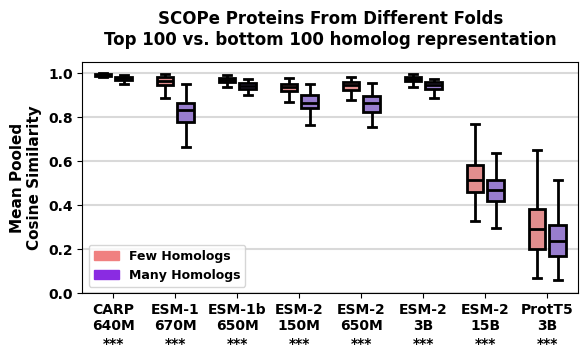

In [23]:
# condensed version fro main text without every model

data = []
x = []
my_pal = []
x_ticklabels = []
p_strings = []
stars = []

data_export_list = []

models_in_question = [
    "carp_640M",
#     "carp_38M",
#     "carp_76M",
#     "esm_1_43M",
#     "esm_1_85M",
#     "esm_1_UR50",
    "esm_1_UR50D",
    "esm_1b",
#     "ESM-2 (8M)",
#     "ESM-2 (35M)",
    "ESM-2 (150M)",
    "ESM-2 (650M)",
    "ESM-2 (3B)",
    "ESM-2 (15B)",
    "prott5_xl",
]

fig, ax = plt.subplots(figsize = (len(models_in_question)*0.8,3))



for i, m in enumerate(models_in_question):
    x = x + [i*3, (i*3) + 1, (i*3) + 2]
    
    x1 = model_to_mean_pool_res[m]["bottom"]
    x2 = model_to_mean_pool_res[m]["top"]
    
    data.append(x1)
    data.append(x2)
    data.append([])
    my_pal.append("lightcoral")
    my_pal.append("mediumpurple")
    my_pal.append("white")
    x_ticklabels.append(model_to_display_a[m].replace("(D)", "")) # distinction between S/D will be in supplemental fig 
    
    _, p = scipy.stats.mannwhitneyu(
         x1,
         x2,
         alternative = "greater"
    )
    print(m, format_p(p))
    p_strings.append(r"$p = " + format_p(p) + "$")
    stars.append(p_val_to_stars(p))
    
    data_export_list.append([
        model_to_display_a[m].replace("\n", " "), 
        "|".join(list(map(lambda x: str(x), x1))),
        "|".join(list(map(lambda x: str(x), x2))),
         p
    ])
    
sns.boxplot(
    data, 
    color = "white", 
    boxprops=dict(linewidth=2, edgecolor='black', zorder = 100),
    medianprops=dict(linewidth=2, color='black', zorder = 100),
    whiskerprops=dict(linewidth=2, color='black', zorder = 100),
    capprops = dict(linewidth=2, color='black', zorder = 100),
    showfliers = False,
    palette = my_pal
)


x_ticks = np.arange(0.5, (len(models_in_question)*3) + 0.001, 3)
ax.set_xticks(x_ticks)
ax.set_xticklabels(x_ticklabels, fontsize = 10, fontweight = "bold")
ax.set_ylim(top=1.05, bottom = 0)
ax.set_yticklabels(ax.get_yticklabels(), fontweight = "bold")

for y_val in ax.get_yticks():
    ax.axhline(y = y_val, color = "black", alpha = 0.15)

## use this for the stars
for xpos, text in zip(x_ticks, stars):
    ax.text(xpos, -0.25, text, horizontalalignment = "center", fontsize = 10, fontweight = "bold")

ax.set_xlim(left = -1, right = len(data) - 1)

ax.set_ylabel("Mean Pooled\nCosine Similarity", fontsize = 11, fontweight = "bold")

coral_patch = mpatches.Patch(color="lightcoral", label='Few Homologs')
purple_patch = mpatches.Patch(color="blueviolet", label='Many Homologs')

ax.legend(handles=[coral_patch,purple_patch], loc = "lower left", prop = {"weight" : "bold", "size" : 9},)
ax.set_title(f"SCOPe Proteins From Different Folds\nTop 100 vs. bottom 100 homolog representation", y =1.04, fontweight = "bold")



In [24]:
data_df_out = pd.DataFrame(data_export_list, columns = ["model", "low_homog_group", "high_homolog_group", "one_sided_mwu_p"])
data_df_out.to_csv(data_output_path + "fig_6/data_6d.csv", index = False)
data_df_out

,model,low_homog_group,high_homolog_group,one_sided_mwu_p
0,CARP 640M,0.9972737388939291|0.9948739901278237|0.996134...,0.9872959478601574|0.9457402764541905|0.974534...,5.043985e-27
1,ESM-1(D) 670M,0.9941372|0.98472583|0.97054434|0.9842783|0.97...,0.89565134|0.7520434|0.80406684|0.81888896|0.7...,6.179555e-32
2,ESM-1b 650M,0.99091244|0.97519517|0.98361415|0.9783531|0.9...,0.97305036|0.9014891|0.9498704|0.9510886|0.903...,7.537979e-20
3,ESM-2 150M,0.97788364|0.9299207|0.9462085|0.93054056|0.96...,0.90173197|0.8636355|0.93328565|0.9154422|0.83...,9.645486e-23
4,ESM-2 650M,0.9644717|0.95774066|0.9576868|0.9442452|0.982...,0.92767984|0.86446303|0.8427042|0.8731553|0.80...,4.651893e-25
5,ESM-2 3B,0.98967624|0.9772623|0.9790196|0.97951186|0.98...,0.9699383|0.93870395|0.94148594|0.94273436|0.9...,3.931266e-20
6,ESM-2 15B,0.85012865|0.6299663|0.7932606|0.7076495|0.876...,0.63767195|0.43298373|0.41103503|0.50840634|0....,2.143379e-05
7,ProtT5 3B,0.7279959|0.38285446|0.5796963|0.5118276|0.580...,0.66804457|0.2165099|0.13588023|0.24428824|0.2...,8.998773e-04


In [25]:
### making table

pairs_tracker_mean = {}
pairs_tracker_cls = {}
pairs_tracker_column = {}


wanted_model_list = [
    "carp_640M", 
    "carp_38M", 
    "carp_76M", 
    "prott5_xl", 
    "esm_1b", 
    "esm_1_43M", 
    "esm_1_85M",
    "esm_1_UR50",  
    "esm_1_UR50D"
]


non_cls_models = [
    "carp_640M", 
    "carp_38M", 
    "carp_76M", 
    "prott5_xl", 
]



for wanted_model in wanted_model_list:

    with open(data_path + wanted_model  + "/all_romote_homologs_seqeunces.pkl", "rb") as f1:
        data = pickle.load(f1)
    f1.close()


    dfa = pd.read_csv(supp_table_path + "top_bottom_homologs_pairs_scope_distances.csv")
    dfa = dfa.loc[dfa["model"] == "ESM-2 (8M)"]
    
    mean_dict = {}
    cls_dict = {}
    column_dict = {}
    
    
    using_cls = wanted_model not in non_cls_models
    
    for index, row in dfa.iterrows():
        p1 = row["protein_1"]
        p2 = row["protein_2"]
        
        p_str = p1 + "|" + p2
        
        emb_1 = data[p1]["mean_pooled"]
        emb_2 = data[p2]["mean_pooled"]
        mean_pool_cos_sim  = cosine_similarity([emb_1], [emb_2])[0][0]
        mean_dict[p_str] = mean_pool_cos_sim
        
        if using_cls:
            emb_1 = data[p1]["cls_pooled"]
            emb_2 = data[p2]["cls_pooled"]
            cls_pool_cos_sim  = cosine_similarity([emb_1], [emb_2])[0][0]
            cls_dict[p_str] = cls_pool_cos_sim
            
            
    pairs_tracker_mean[wanted_model] = mean_dict
    pairs_tracker_cls[wanted_model] = cls_dict
    
    
    # column wise lists 
    
    with open(data_path + wanted_model  + "/selected_full_seqs_all_groups.pkl", "rb") as f1:
        data = pickle.load(f1)
    f1.close()
    
    
    dfa = pd.read_csv(supp_table_path + "top_bottom_homologs_pairs_scope_distances.csv")
    dfa = dfa.loc[dfa["model"] == "ESM-2 (8M)"]
    
    
    
    bottom_100_pairs = dfa.loc[(dfa["model"] == "ESM-2 (8M)") & (dfa["group_annotation"] == "bottom_100")]
    top_100_pairs = dfa.loc[(dfa["model"] == "ESM-2 (8M)") & (dfa["group_annotation"] == "top_100")]


   
    for index, row in top_100_pairs.iterrows():
        p1 = row["protein_1"]
        p2 = row["protein_2"]
        
        p_str = p1 + "|" + p2
        
        emb_1 = data["top_100_scope"][p1]
        emb_2 = data["top_100_scope"][p2]
        
        min_length = min(np.shape(emb_1)[0], np.shape(emb_2)[0])
        
        lst = []
        
        for i in range(min_length):
            x1 = emb_1[i]
            x2 = emb_2[i]
            cos_sim = cosine_similarity([x1], [x2])[0][0]
            lst.append(cos_sim)
        
        column_dict[p_str] = lst
    
    for index, row in bottom_100_pairs.iterrows():
        p1 = row["protein_1"]
        p2 = row["protein_2"]
        
        p_str = p1 + "|" + p2

        emb_1 = data["bottom_100_scope"][p1]
        emb_2 = data["bottom_100_scope"][p2]
        
        min_length = min(np.shape(emb_1)[0], np.shape(emb_2)[0])
        lst = []
        for i in range(min_length):
            x1 = emb_1[i]
            x2 = emb_2[i]
            cos_sim = cosine_similarity([x1], [x2])[0][0]
            lst.append(cos_sim)

        column_dict[p_str] = lst
    
    
    pairs_tracker_column[wanted_model] = column_dict
    
        
        
model_to_display_d = {
    "carp_38M" : "CARP (38M)",
    "carp_76M":"CARP (76M)",
    "carp_640M":"CARP (640M)",
    "esm_1_43M":"ESM-1 (43M)",
    "esm_1_85M":"ESM-1 (85M)",
    "esm_1_UR50":"ESM-1 (670M) UR50S",
    "esm_1_UR50D":"ESM-1 (670M) UR50D",
    "esm_1b":"ESM-1b (650M)",
    "prott5_xl" : "ProtT5 (3B)",
}


dfa = pd.read_csv(supp_table_path + "top_bottom_homologs_pairs_scope_distances.csv")
dfa = dfa.loc[dfa["model"] == "ESM-2 (8M)"]
dfa = dfa.drop(columns =["cos_sim_mean_pool","cos_sim_cls","model","cos_sim_column_wise"])

df_spine = copy.deepcopy(dfa) # only adding the new models, ESM-2 already in there 

out_df_list = []
for wanted_model in wanted_model_list:
    dfo = copy.deepcopy(df_spine)
    mean_pooled_list = []
    cls_pooled_list = []
    column_wise_list = []
    
    using_cls = wanted_model not in non_cls_models
    print(wanted_model, using_cls)
    for index, row in dfo.iterrows():
        
        p1 = row["protein_1"]
        p2 = row["protein_2"]
        
        p_str = p1 + "|" + p2
        mean_pooled_list.append(pairs_tracker_mean[wanted_model][p_str])
        
        if using_cls:
            cls_pooled_list.append(pairs_tracker_cls[wanted_model][p_str])
            
        if not pd.isna(row["group_annotation"]):
            lst = pairs_tracker_column[wanted_model][p_str]
            lst = "|".join(list(map(lambda x : str(x), lst)))
            column_wise_list.append(lst)
            
        else:
            column_wise_list.append(None)
            
    dfo["cos_sim_mean_pool"] = mean_pooled_list
    if using_cls:
        dfo["cos_sim_cls"] = cls_pooled_list
    else:
        dfo["cos_sim_cls"] = None
        
    dfo["cos_sim_column_wise"] = column_wise_list
    dfo["model"] = model_to_display_d[wanted_model]
    
    out_df_list.append(dfo)
    
dfa = pd.read_csv(supp_table_path + "top_bottom_homologs_pairs_scope_distances.csv")
df_z = pd.concat(out_df_list)

df_out_scope = pd.concat([df_z, dfa])
df_out_scope.to_csv(supp_table_path + "revisions/scope_all_distances_pink_purple_boxplots.csv", index = False)

carp_640M False
carp_38M False
carp_76M False
prott5_xl False
esm_1b True
esm_1_43M True
esm_1_85M True
esm_1_UR50 True
esm_1_UR50D True


/tmp/ipykernel_1803507/2519027334.py:190: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df_z = pd.concat(out_df_list)


## Orphan25 v Human

In [26]:
# data_path + wanted_model

In [28]:


model_to_mean_pool_res = {}

wanted_pool_method = "mean_pooled"


wanted_model_list = ["carp_640M", "carp_38M", "carp_76M", "prott5_xl", "esm_1b", "esm_1_43M", "esm_1_85M","esm_1_UR50",  "esm_1_UR50D"]

for wanted_model in wanted_model_list:
    
    with open(data_path + wanted_model  + "/embedding_space_used_seqeunces.pkl", "rb") as f1:
        data = pickle.load(f1)
    f1.close()

    dfb = pd.read_csv(supp_table_path + "orphan_25_human_pair_distances.csv")

    # just getting pairs, can be any combination all are the same 
    orphan_comparisons = dfb.loc[
        (dfb["category"] == "Orphan25") &
        (dfb["similarity method"] == "Mean Pool") &
        (dfb["model"] == "ESM-2 (8M)")
    ]


    human_comparisons = dfb.loc[
        (dfb["category"] == "Human Selections") &
        (dfb["similarity method"] == "Mean Pool") &
        (dfb["model"] == "ESM-2 (8M)")
    ]


    orphan_25_res = []

    for index, row in orphan_comparisons.iterrows():
        p1 = row["protein1"]
        p2 = row["protein2"]

        emb_1 = data[p1][wanted_pool_method]
        emb_2 = data[p2][wanted_pool_method]

        cos_sim = cosine_similarity([emb_1], [emb_2])[0][0]

        orphan_25_res.append(cos_sim)


    human_comp_res = []

    for index, row in human_comparisons.iterrows():
        p1 = row["protein1"]
        p2 = row["protein2"]

        emb_1 = data[p1][wanted_pool_method]
        emb_2 = data[p2][wanted_pool_method]

        cos_sim = cosine_similarity([emb_1], [emb_2])[0][0]

        human_comp_res.append(cos_sim)
        
    
    model_to_mean_pool_res[wanted_model] = {"orphan25" : orphan_25_res, "human" : human_comp_res}
    
    print(wanted_model, scipy.stats.mannwhitneyu(orphan_25_res, human_comp_res, alternative = "greater").pvalue)
    
dfb = pd.read_csv(supp_table_path + "orphan_25_human_pair_distances.csv")
for model, sub_df in dfb.groupby("model"):
    
    
    orphan_comparisons = sub_df.loc[
        (sub_df["category"] == "Orphan25") &
        (sub_df["similarity method"] == "Mean Pool") 
    ]

    human_comparisons = sub_df.loc[
        (sub_df["category"] == "Human Selections") &
        (sub_df["similarity method"] == "Mean Pool") 
    ]
    
    x1 = list(map(lambda x : float(x), orphan_comparisons["distance"].values))
    x2 = list(map(lambda x : float(x), human_comparisons["distance"].values))
    
    # distance is misnomer, this is cosine similarity not distance
    model_to_mean_pool_res[model] = {"orphan25" :x1, "human" : x2}
    
   
    
    print(model, scipy.stats.mannwhitneyu(x1, x2, alternative = "greater").pvalue)
    


carp_640M 9.832436656332513e-17
carp_38M 0.0064294962784775195
carp_76M 1.8082574015110725e-07
prott5_xl 0.023883882096696604
esm_1b 7.780012416233123e-24
esm_1_43M 1.6377849175575607e-13
esm_1_85M 2.9502690413433436e-31
esm_1_UR50 8.78339725327405e-44
esm_1_UR50D 1.8518000116902056e-41
ESM-2 (150M) 1.1557211745117936e-08
ESM-2 (15B) 8.179289049099582e-10
ESM-2 (35M) 0.0003469295808957573
ESM-2 (3B) 3.3455575905539146e-43
ESM-2 (650M) 6.840963259513407e-28
ESM-2 (8M) 0.008941936706787203


In [29]:


model_to_cls_pool_res = {}

wanted_pool_method = "cls_pooled"


wanted_model_list = [
#     "carp_640M", 
#     "carp_38M", 
#     "carp_76M",
#     "prott5_xl", # these dont have CLS 
    "esm_1b", 
    "esm_1_43M", 
    "esm_1_85M",
    "esm_1_UR50",  
    "esm_1_UR50D"
]

for wanted_model in wanted_model_list:
    
    with open(data_path + wanted_model  + "/embedding_space_used_seqeunces.pkl", "rb") as f1:
        data = pickle.load(f1)
    f1.close()

    dfb = pd.read_csv(supp_table_path + "orphan_25_human_pair_distances.csv")

    # just getting pairs, can be any combination all are the same 
    orphan_comparisons = dfb.loc[
        (dfb["category"] == "Orphan25") &
        (dfb["similarity method"] == "CLS pool") &
        (dfb["model"] == "ESM-2 (8M)")
    ]


    human_comparisons = dfb.loc[
        (dfb["category"] == "Human Selections") &
        (dfb["similarity method"] == "CLS pool") &
        (dfb["model"] == "ESM-2 (8M)")
    ]


    orphan_25_res = []

    for index, row in orphan_comparisons.iterrows():
        p1 = row["protein1"]
        p2 = row["protein2"]

        emb_1 = data[p1][wanted_pool_method]
        emb_2 = data[p2][wanted_pool_method]

        cos_sim = cosine_similarity([emb_1], [emb_2])[0][0]

        orphan_25_res.append(cos_sim)


    human_comp_res = []

    for index, row in human_comparisons.iterrows():
        p1 = row["protein1"]
        p2 = row["protein2"]

        emb_1 = data[p1][wanted_pool_method]
        emb_2 = data[p2][wanted_pool_method]

        cos_sim = cosine_similarity([emb_1], [emb_2])[0][0]

        human_comp_res.append(cos_sim)
        
    
    model_to_cls_pool_res[wanted_model] = {"orphan25" : orphan_25_res, "human" : human_comp_res}
    
    print(wanted_model, scipy.stats.mannwhitneyu(orphan_25_res, human_comp_res, alternative = "greater").pvalue)
    
dfb = pd.read_csv(supp_table_path + "orphan_25_human_pair_distances.csv")
for model, sub_df in dfb.groupby("model"):
    
    
    orphan_comparisons = sub_df.loc[
        (sub_df["category"] == "Orphan25") &
        (sub_df["similarity method"] == "CLS pool") 
    ]

    human_comparisons = sub_df.loc[
        (sub_df["category"] == "Human Selections") &
        (sub_df["similarity method"] == "CLS pool") 
    ]
    
    x1 = list(map(lambda x : float(x), orphan_comparisons["distance"].values))
    x2 = list(map(lambda x : float(x), human_comparisons["distance"].values))
    
    # distance is misnomer, this is cosine similarity not distance
    model_to_cls_pool_res[model] = {"orphan25" :x1, "human" : x2}
    
   
    
    print(model, scipy.stats.mannwhitneyu(x1, x2, alternative = "greater").pvalue)
    

esm_1b 8.718085692669032e-41
esm_1_43M 0.003233067184885809
esm_1_85M 1.6224396048056772e-19
esm_1_UR50 2.9959728542221848e-52
esm_1_UR50D 2.191413191052967e-60
ESM-2 (150M) 4.053844711559817e-05
ESM-2 (15B) 1.0
ESM-2 (35M) 0.9989256851167967
ESM-2 (3B) 2.9563316074400336e-06
ESM-2 (650M) 1.5968471392400396e-15
ESM-2 (8M) 0.004840296831243611


In [31]:
column_wise_results = {}

wanted_model_list = [
    "carp_640M", 
    "carp_38M", 
    "carp_76M", 
    "prott5_xl", 
    "esm_1b", 
    "esm_1_43M", 
    "esm_1_85M",
    "esm_1_UR50",  
    "esm_1_UR50D"
]

for wanted_model in wanted_model_list:

    with open(data_path + wanted_model  + "/selected_full_seqs_all_groups.pkl", "rb") as f1:
        data = pickle.load(f1)
    f1.close()


    dfb = pd.read_csv(supp_table_path + "orphan_25_human_pair_distances.csv")

    # just getting pairs, can be any combination all are the same 
    orphan_comparisons = dfb.loc[
        (dfb["category"] == "Orphan25") &
        (dfb["similarity method"] == "Column Wise Dists") &
        (dfb["model"] == "ESM-2 (8M)")
    ]


    human_comparisons = dfb.loc[
        (dfb["category"] == "Human Selections") &
        (dfb["similarity method"] == "Column Wise Dists") &
        (dfb["model"] == "ESM-2 (8M)")
    ]


    orphan_list = []
    for index, row in orphan_comparisons.iterrows():
        p1 = row["protein1"]
        p2 = row["protein2"]

        emb_1 = data["orphan_25"][p1]
        emb_2 = data["orphan_25"][p2]
        
        min_length = min(np.shape(emb_1)[0], np.shape(emb_2)[0])
        
        for i in range(min_length):
            x1 = emb_1[i]
            x2 = emb_2[i]
            cos_sim = cosine_similarity([x1], [x2])[0][0]
            orphan_list.append(cos_sim)
            
    human_list = []
    for index, row in human_comparisons.iterrows():
        p1 = row["protein1"]
        p2 = row["protein2"]

        emb_1 = data["human_selections"][p1]
        emb_2 = data["human_selections"][p2]
        
        min_length = min(np.shape(emb_1)[0], np.shape(emb_2)[0])
        
        for i in range(min_length):
            x1 = emb_1[i]
            x2 = emb_2[i]
            cos_sim = cosine_similarity([x1], [x2])[0][0]
            human_list.append(cos_sim)
    
    
    print(wanted_model, scipy.stats.mannwhitneyu(orphan_list, human_list, alternative = "greater").pvalue)

    column_wise_results[wanted_model] = {"orphan25" : orphan_list, "human" : human_list}
    
    
dfb = pd.read_csv(supp_table_path + "orphan_25_human_pair_distances.csv")

for model, sub_df in dfb.groupby("model"):
    
    
    orphan_comparisons = sub_df.loc[
        (sub_df["category"] == "Orphan25") &
        (sub_df["similarity method"] == "Column Wise Dists") 
    ]

    human_comparisons = sub_df.loc[
        (sub_df["category"] == "Human Selections") &
        (sub_df["similarity method"] == "Column Wise Dists") 
    ] 
    
    orphan_list = []
   
    # distance is misnomer, this is cosine similarity not distance
    for v in orphan_comparisons["distance"].values:
        v = list(map(lambda x : float(x), v.split("|")))
        for value in v:
            orphan_list.append(value)

    
    human_list = []
    
     # distance is misnomer, this is cosine similarity not distance
    for v in human_comparisons["distance"].values:
        v = list(map(lambda x : float(x), v.split("|")))
        for value in v:
            human_list.append(value)
    
    column_wise_results[model] = {"orphan25" : orphan_list, "human" : human_list}

    print(model, scipy.stats.mannwhitneyu(orphan_list, human_list, alternative = "greater").pvalue)
     

carp_640M 0.0
carp_38M 0.0
carp_76M 0.0
prott5_xl 2.935831218905882e-05
esm_1b 0.0
esm_1_43M 1.58935487919837e-201
esm_1_85M 0.0
esm_1_UR50 0.0
esm_1_UR50D 0.0
ESM-2 (150M) 0.0
ESM-2 (15B) 0.0
ESM-2 (35M) 2.0052440095101498e-268
ESM-2 (3B) 0.0
ESM-2 (650M) 0.0
ESM-2 (8M) 5.221750066898135e-293


carp_640M 9.83 x 10^{-17}
carp_38M 0.00643
carp_76M 1.81 x 10^{-07}
esm_1_43M 1.64 x 10^{-13}
esm_1_85M 2.95 x 10^{-31}
esm_1_UR50 8.78 x 10^{-44}
esm_1_UR50D 1.85 x 10^{-41}
esm_1b 7.78 x 10^{-24}
ESM-2 (8M) 0.00894
ESM-2 (35M) 0.000347
ESM-2 (150M) 1.16 x 10^{-08}
ESM-2 (650M) 6.84 x 10^{-28}
ESM-2 (3B) 3.35 x 10^{-43}
ESM-2 (15B) 8.18 x 10^{-10}
prott5_xl 0.0239


/tmp/ipykernel_1803507/2556027946.py:60: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_1803507/2556027946.py:76: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(ax.get_yticklabels(), fontweight = "bold")


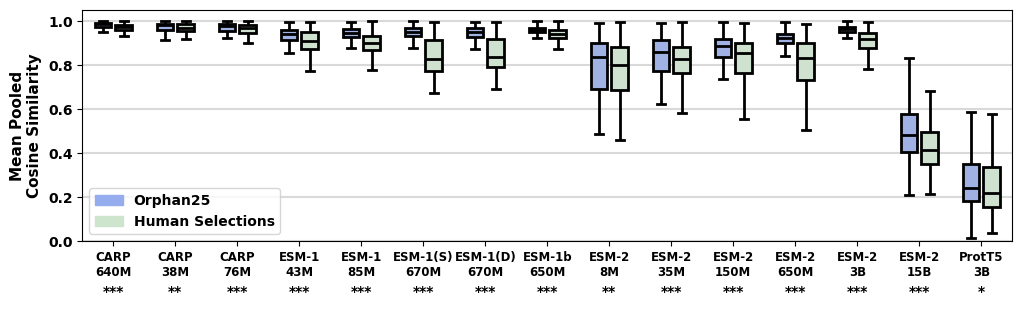

In [33]:
data = []
x = []
my_pal = []
x_ticklabels = []
p_strings = []
stars = []

models_in_question = [
    "carp_640M",
    "carp_38M",
    "carp_76M",
    "esm_1_43M",
    "esm_1_85M",
    "esm_1_UR50",
    "esm_1_UR50D",
    "esm_1b",
    "ESM-2 (8M)",
    "ESM-2 (35M)",
    "ESM-2 (150M)",
    "ESM-2 (650M)",
    "ESM-2 (3B)",
    "ESM-2 (15B)",
    "prott5_xl",
]

data_export_list = []

fig, ax = plt.subplots(figsize = (len(models_in_question)*0.8,3))

for i, m in enumerate(models_in_question):
    x = x + [i*3, (i*3) + 1, (i*3) + 2]
    
    x1 = model_to_mean_pool_res[m]["orphan25"]
    x2 = model_to_mean_pool_res[m]["human"]
    
    data.append(x1)
    data.append(x2)
    data.append([])
    my_pal.append("#95acef")
    my_pal.append("#cce5cc")
    my_pal.append("white")
    x_ticklabels.append(model_to_display_a[m])
    
    _, p = scipy.stats.mannwhitneyu(
         x1,
         x2,
         alternative = "greater"
    )
    print(m, format_p(p))
    p_strings.append(r"$p = " + format_p(p) + "$")
    stars.append(p_val_to_stars(p))
    
    data_export_list.append([
        model_to_display_a[m].replace("\n", " "), 
        "|".join(list(map(lambda x: str(x), x1))),
        "|".join(list(map(lambda x: str(x), x2))),
         p
    ])
    
sns.boxplot(
    data, 
    color = "white", 
    boxprops=dict(linewidth=2, edgecolor='black', zorder = 100),
    medianprops=dict(linewidth=2, color='black', zorder = 100),
    whiskerprops=dict(linewidth=2, color='black', zorder = 100),
    capprops = dict(linewidth=2, color='black', zorder = 100),
    showfliers = False,
    palette = my_pal
)


x_ticks = np.arange(0.5, (len(models_in_question)*3) + 0.001, 3)
ax.set_xticks(x_ticks)
ax.set_xticklabels(x_ticklabels, fontsize = 8.5, fontweight = "bold")
ax.set_ylim(top=1.05, bottom = 0)
ax.set_yticklabels(ax.get_yticklabels(), fontweight = "bold")

for y_val in ax.get_yticks():
    ax.axhline(y = y_val, color = "black", alpha = 0.15)

## use this for the stars
for xpos, text in zip(x_ticks, stars):
    ax.text(xpos, -0.25, text, horizontalalignment = "center", fontsize = 10, fontweight = "bold")

ax.set_xlim(left = -1, right = len(data) - 1)

ax.set_ylabel("Mean Pooled\nCosine Similarity", fontsize = 11, fontweight = "bold")
    
blue_patch = mpatches.Patch(color="#95acef", label='Orphan25')
green_patch = mpatches.Patch(color="#cce5cc", label='Human Selections')

ax.legend(handles=[blue_patch,green_patch], loc = "lower left", prop = {"weight" : "bold", "size" : 10})


In [34]:
# fig_S8

data_df_out = pd.DataFrame(data_export_list, columns = ["model", "orphan25", "human_selections", "one_sided_mwu_p"])
data_df_out.to_csv(data_output_path + "fig_S8/data_S8a.csv", index = False)
data_df_out

,model,orphan25,human_selections,one_sided_mwu_p
0,CARP 640M,0.9866484810372951|0.9860141849722264|0.987642...,0.9934546827772538|0.946230226758574|0.9583087...,9.832437e-17
1,CARP 38M,0.9758200330795713|0.9779124513641748|0.979605...,0.9840578520947301|0.9314148028302773|0.941148...,6.429496e-03
2,CARP 76M,0.9738856899051289|0.975320414913308|0.9780652...,0.9872377270026448|0.9171845689688339|0.941162...,1.808257e-07
3,ESM-1 43M,0.9086391|0.91491425|0.9156541|0.91740835|0.88...,0.9625146|0.86657906|0.8576262|0.9225316|0.870...,1.637785e-13
4,ESM-1 85M,0.91810834|0.9453872|0.9378871|0.9081908|0.908...,0.97120374|0.8763931|0.87972605|0.94085443|0.8...,2.950269e-31
5,ESM-1(S) 670M,0.94534004|0.9516164|0.9561323|0.91966486|0.89...,0.97450656|0.8018283|0.83969146|0.9436953|0.71...,8.783397e-44
6,ESM-1(D) 670M,0.9387306|0.9436982|0.94806033|0.9156477|0.893...,0.96418864|0.8362937|0.8674989|0.94431674|0.74...,1.851800e-41
7,ESM-1b 650M,0.95985776|0.96907073|0.9634488|0.9580225|0.94...,0.9828251|0.9404162|0.93338263|0.94149673|0.92...,7.780012e-24
8,ESM-2 8M,0.7531801|0.79590005|0.82216763|0.8184851|0.68...,0.942705|0.4840747|0.5491077|0.8175132|0.65802...,8.941937e-03
9,ESM-2 35M,0.8376099|0.8701958|0.89023846|0.8306611|0.753...,0.9486766|0.5911634|0.63278276|0.8465234|0.745...,3.469296e-04


esm_1_43M 0.00323
esm_1_85M 1.62 x 10^{-19}
esm_1_UR50 3 x 10^{-52}
esm_1_UR50D 2.19 x 10^{-60}
esm_1b 8.72 x 10^{-41}
ESM-2 (8M) 0.00484
ESM-2 (35M) 0.999
ESM-2 (150M) 4.05 x 10^{-05}
ESM-2 (650M) 1.6 x 10^{-15}
ESM-2 (3B) 2.96 x 10^{-06}
ESM-2 (15B) 1


/tmp/ipykernel_1803507/796789598.py:60: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_1803507/796789598.py:76: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(ax.get_yticklabels(), fontweight = "bold")


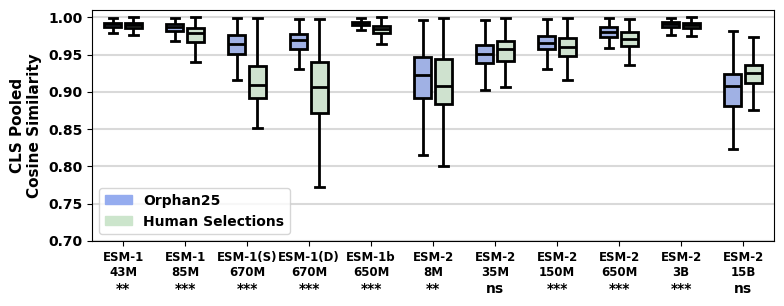

In [35]:
data = []
x = []
my_pal = []
x_ticklabels = []
p_strings = []
stars = []

models_in_question = [
#     "carp_640M",
#     "carp_38M",
#     "carp_76M",
    "esm_1_43M",
    "esm_1_85M",
    "esm_1_UR50",
    "esm_1_UR50D",
    "esm_1b",
    "ESM-2 (8M)",
    "ESM-2 (35M)",
    "ESM-2 (150M)",
    "ESM-2 (650M)",
    "ESM-2 (3B)",
    "ESM-2 (15B)",
#     "prott5_xl",
]

data_export_list = []

fig, ax = plt.subplots(figsize = (len(models_in_question)*0.8,3))

for i, m in enumerate(models_in_question):
    x = x + [i*3, (i*3) + 1, (i*3) + 2]
    
    x1 = model_to_cls_pool_res[m]["orphan25"]
    x2 = model_to_cls_pool_res[m]["human"]
    
    data.append(x1)
    data.append(x2)
    data.append([])
    my_pal.append("#95acef")
    my_pal.append("#cce5cc")
    my_pal.append("white")
    x_ticklabels.append(model_to_display_a[m])
    
    _, p = scipy.stats.mannwhitneyu(
         x1,
         x2,
         alternative = "greater"
    )
    print(m, format_p(p))
    p_strings.append(r"$p = " + format_p(p) + "$")
    stars.append(p_val_to_stars(p))
    
    data_export_list.append([
        model_to_display_a[m].replace("\n", " "), 
        "|".join(list(map(lambda x: str(x), x1))),
        "|".join(list(map(lambda x: str(x), x2))),
         p
    ])
    
sns.boxplot(
    data, 
    color = "white", 
    boxprops=dict(linewidth=2, edgecolor='black', zorder = 100),
    medianprops=dict(linewidth=2, color='black', zorder = 100),
    whiskerprops=dict(linewidth=2, color='black', zorder = 100),
    capprops = dict(linewidth=2, color='black', zorder = 100),
    showfliers = False,
    palette = my_pal
)


x_ticks = np.arange(0.5, (len(models_in_question)*3) + 0.001, 3)
ax.set_xticks(x_ticks)
ax.set_xticklabels(x_ticklabels, fontsize = 8.5, fontweight = "bold")
ax.set_ylim(top=1.01, bottom = 0.7)
ax.set_yticklabels(ax.get_yticklabels(), fontweight = "bold")

for y_val in ax.get_yticks():
    ax.axhline(y = y_val, color = "black", alpha = 0.15)

## use this for the stars
for xpos, text in zip(x_ticks, stars):
    ax.text(xpos, 0.63, text, horizontalalignment = "center", fontsize = 10, fontweight = "bold")

ax.set_xlim(left = -1, right = len(data) - 1)

ax.set_ylabel("CLS Pooled\nCosine Similarity", fontsize = 11, fontweight = "bold")
    
blue_patch = mpatches.Patch(color="#95acef", label='Orphan25')
green_patch = mpatches.Patch(color="#cce5cc", label='Human Selections')

ax.legend(handles=[blue_patch,green_patch], loc = "lower left", prop = {"weight" : "bold", "size" : 10})


In [36]:

data_df_out = pd.DataFrame(data_export_list, columns = ["model", "orphan25", "human_selections", "one_sided_mwu_p"])
data_df_out.to_csv(data_output_path + "fig_S8/data_S8b.csv", index = False)
data_df_out

,model,orphan25,human_selections,one_sided_mwu_p
0,ESM-1 43M,0.98847336|0.9881493|0.9908221|0.99065024|0.98...,0.99372977|0.9762056|0.9849092|0.97518325|0.98...,3.233067e-03
1,ESM-1 85M,0.9878773|0.99020004|0.9830475|0.986551|0.9800...,0.98379904|0.9773154|0.9809897|0.9664626|0.981...,1.622440e-19
2,ESM-1(S) 670M,0.9719299|0.97745895|0.9671093|0.9589864|0.948...,0.9604548|0.90758413|0.8959978|0.9468902|0.908...,2.995973e-52
3,ESM-1(D) 670M,0.96839726|0.9734311|0.9639656|0.9582601|0.955...,0.9639384|0.9076567|0.91211313|0.9443729|0.853...,2.191413e-60
4,ESM-1b 650M,0.9945213|0.9942144|0.98246074|0.991274|0.9905...,0.993744|0.9855201|0.9870746|0.9875277|0.97820...,8.718086e-41
5,ESM-2 8M,0.90838444|0.9311066|0.9230268|0.9410028|0.884...,0.9487396|0.87060493|0.89168817|0.89962244|0.8...,4.840297e-03
6,ESM-2 35M,0.9642291|0.96476895|0.9665514|0.94611824|0.94...,0.9567042|0.94163287|0.94556916|0.9321534|0.95...,9.989257e-01
7,ESM-2 150M,0.97434515|0.9815159|0.95467424|0.9689036|0.96...,0.98277295|0.9541979|0.96055144|0.95171267|0.9...,4.053845e-05
8,ESM-2 650M,0.9914715|0.9881217|0.98094|0.986017|0.9790291...,0.9813858|0.9602664|0.97299457|0.9745815|0.949...,1.596847e-15
9,ESM-2 3B,0.99522775|0.9918275|0.98903817|0.9879504|0.98...,0.97078687|0.99089944|0.990254|0.99035335|0.98...,2.956332e-06


carp_640M < 10^{-256}
carp_38M < 10^{-256}
carp_76M < 10^{-256}
esm_1_43M 1.59 x 10^{-201}
esm_1_85M < 10^{-256}
esm_1_UR50 < 10^{-256}
esm_1_UR50D < 10^{-256}
esm_1b < 10^{-256}
ESM-2 (8M) < 10^{-256}
ESM-2 (35M) < 10^{-256}
ESM-2 (150M) < 10^{-256}
ESM-2 (650M) < 10^{-256}
ESM-2 (3B) < 10^{-256}
ESM-2 (15B) < 10^{-256}
prott5_xl 2.94 x 10^{-05}


/tmp/ipykernel_1803507/2883748409.py:60: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_1803507/2883748409.py:76: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(ax.get_yticklabels(), fontweight = "bold")


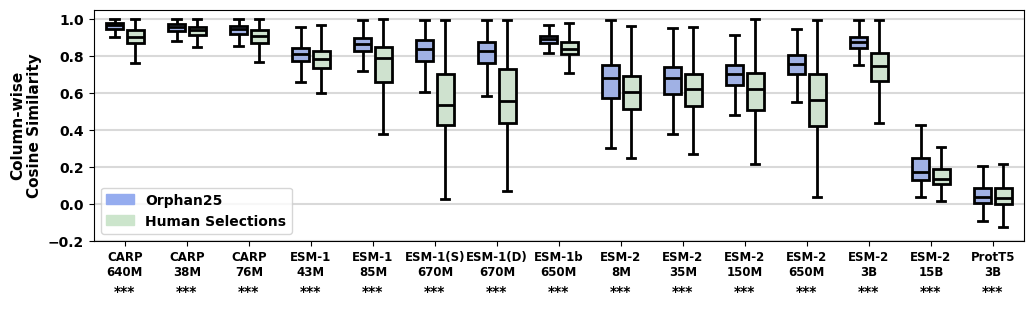

In [37]:
data = []
x = []
my_pal = []
x_ticklabels = []
p_strings = []
stars = []

models_in_question = [
    "carp_640M",
    "carp_38M",
    "carp_76M",
    "esm_1_43M",
    "esm_1_85M",
    "esm_1_UR50",
    "esm_1_UR50D",
    "esm_1b",
    "ESM-2 (8M)",
    "ESM-2 (35M)",
    "ESM-2 (150M)",
    "ESM-2 (650M)",
    "ESM-2 (3B)",
    "ESM-2 (15B)",
    "prott5_xl",
]

data_export_list = []

fig, ax = plt.subplots(figsize = (len(models_in_question)*0.8,3))

for i, m in enumerate(models_in_question):
    x = x + [i*3, (i*3) + 1, (i*3) + 2]
    
    x1 = column_wise_results[m]["orphan25"]
    x2 = column_wise_results[m]["human"]
    
    data.append(x1)
    data.append(x2)
    data.append([])
    my_pal.append("#95acef")
    my_pal.append("#cce5cc")
    my_pal.append("white")
    x_ticklabels.append(model_to_display_a[m])
    
    _, p = scipy.stats.mannwhitneyu(
         x1,
         x2,
         alternative = "greater"
    )
    print(m, format_p(p))
    p_strings.append(r"$p = " + format_p(p) + "$")
    stars.append(p_val_to_stars(p))
    
    data_export_list.append([
        model_to_display_a[m].replace("\n", " "), 
        "|".join(list(map(lambda x: str(x), x1))),
        "|".join(list(map(lambda x: str(x), x2))),
         p
    ])
    
sns.boxplot(
    data, 
    color = "white", 
    boxprops=dict(linewidth=2, edgecolor='black', zorder = 100),
    medianprops=dict(linewidth=2, color='black', zorder = 100),
    whiskerprops=dict(linewidth=2, color='black', zorder = 100),
    capprops = dict(linewidth=2, color='black', zorder = 100),
    showfliers = False,
    palette = my_pal
)


x_ticks = np.arange(0.5, (len(models_in_question)*3) + 0.001, 3)
ax.set_xticks(x_ticks)
ax.set_xticklabels(x_ticklabels, fontsize = 8.5, fontweight = "bold")
ax.set_ylim(top=1.05, bottom = -0.2)
ax.set_yticklabels(ax.get_yticklabels(), fontweight = "bold")

for y_val in ax.get_yticks():
    ax.axhline(y = y_val, color = "black", alpha = 0.15)

## use this for the stars
for xpos, text in zip(x_ticks, stars):
    ax.text(xpos, -0.5, text, horizontalalignment = "center", fontsize = 10, fontweight = "bold")

ax.set_xlim(left = -1, right = len(data) - 1)

ax.set_ylabel("Column-wise\nCosine Similarity", fontsize = 11, fontweight = "bold")
    
blue_patch = mpatches.Patch(color="#95acef", label='Orphan25')
green_patch = mpatches.Patch(color="#cce5cc", label='Human Selections')

ax.legend(handles=[blue_patch,green_patch], loc = "lower left", prop = {"weight" : "bold", "size" : 10})


In [38]:
data_df_out = pd.DataFrame(data_export_list, columns = ["model", "orphan25", "human_selections", "one_sided_mwu_p"])
data_df_out.to_csv(data_output_path + "fig_S8/data_S8c.csv", index = False)
data_df_out

,model,orphan25,human_selections,one_sided_mwu_p
0,CARP 640M,0.96666753|0.96745044|0.9701549|0.96938413|0.9...,0.94243026|0.94636106|0.95733637|0.94210976|0....,0.000000e+00
1,CARP 38M,0.97203314|0.9767442|0.96927255|0.9659399|0.95...,0.9655|0.9484829|0.9257195|0.93541694|0.931967...,0.000000e+00
2,CARP 76M,0.9729151|0.96466583|0.95176375|0.9695834|0.95...,0.9718452|0.92386466|0.94739413|0.93617344|0.9...,0.000000e+00
3,ESM-1 43M,0.89290833|0.8141052|0.88111734|0.89556503|0.9...,0.9370021|0.7546786|0.70919967|0.7048821|0.692...,1.589355e-201
4,ESM-1 85M,0.94079757|0.8527441|0.8878981|0.88709|0.87429...,0.8892299|0.8365546|0.8083217|0.8451669|0.8015...,0.000000e+00
5,ESM-1(S) 670M,0.91209686|0.64624184|0.79636914|0.82182527|0....,0.7685272|0.7367354|0.6821|0.6739327|0.6317966...,0.000000e+00
6,ESM-1(D) 670M,0.9292643|0.6947641|0.8146771|0.80130124|0.730...,0.88013154|0.8291212|0.71100295|0.7351798|0.64...,0.000000e+00
7,ESM-1b 650M,0.92617106|0.88883835|0.88909876|0.8902333|0.8...,0.9080334|0.8214795|0.8136317|0.80637604|0.774...,0.000000e+00
8,ESM-2 8M,0.84227|0.82875|0.82009|0.84997|0.82464|0.8063...,0.83253|0.67922|0.6245|0.68139|0.60341|0.66356...,5.221750e-293
9,ESM-2 35M,0.626|0.49604|0.59456|0.6442|0.57825|0.59657|0...,0.74494|0.58406|0.54032|0.53566|0.32504|0.4254...,2.005244e-268


carp_640M 9.83 x 10^{-17}
esm_1_UR50D 1.85 x 10^{-41}
esm_1b 7.78 x 10^{-24}
ESM-2 (150M) 1.16 x 10^{-08}
ESM-2 (650M) 6.84 x 10^{-28}
ESM-2 (3B) 3.35 x 10^{-43}
ESM-2 (15B) 8.18 x 10^{-10}
prott5_xl 0.0239


/tmp/ipykernel_1803507/771426341.py:61: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_1803507/771426341.py:77: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(ax.get_yticklabels(), fontweight = "bold")


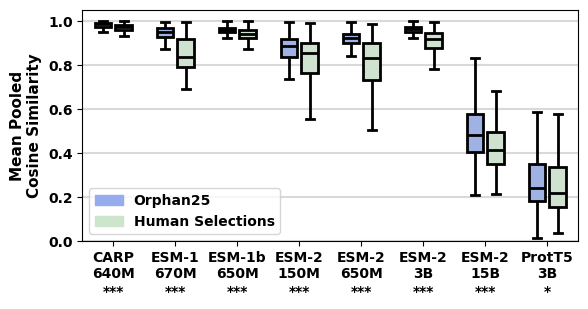

In [39]:
data = []
x = []
my_pal = []
x_ticklabels = []
p_strings = []
stars = []

models_in_question = [
    "carp_640M",
#     "carp_38M",
#     "carp_76M",
#     "esm_1_43M",
#     "esm_1_85M",
#     "esm_1_UR50",
    "esm_1_UR50D",
    "esm_1b",
#     "ESM-2 (8M)",
#     "ESM-2 (35M)",
    "ESM-2 (150M)",
    "ESM-2 (650M)",
    "ESM-2 (3B)",
    "ESM-2 (15B)",
    "prott5_xl",
]

data_export_list = []

fig, ax = plt.subplots(figsize = (len(models_in_question)*0.8,3))

for i, m in enumerate(models_in_question):
    x = x + [i*3, (i*3) + 1, (i*3) + 2]
    
    x1 = model_to_mean_pool_res[m]["orphan25"]
    x2 = model_to_mean_pool_res[m]["human"]
    
    data.append(x1)
    data.append(x2)
    data.append([])
    my_pal.append("#95acef")
    my_pal.append("#cce5cc")
    my_pal.append("white")
    x_ticklabels.append(model_to_display_a[m].replace("(D)", ""))
    
    _, p = scipy.stats.mannwhitneyu(
         x1,
         x2,
         alternative = "greater"
    )
    print(m, format_p(p))
    p_strings.append(r"$p = " + format_p(p) + "$")
    stars.append(p_val_to_stars(p))
    
     
    data_export_list.append([
        model_to_display_a[m].replace("\n", " "), 
        "|".join(list(map(lambda x: str(x), x1))),
        "|".join(list(map(lambda x: str(x), x2))),
         p
    ])
    
sns.boxplot(
    data, 
    color = "white", 
    boxprops=dict(linewidth=2, edgecolor='black', zorder = 100),
    medianprops=dict(linewidth=2, color='black', zorder = 100),
    whiskerprops=dict(linewidth=2, color='black', zorder = 100),
    capprops = dict(linewidth=2, color='black', zorder = 100),
    showfliers = False,
    palette = my_pal
)


x_ticks = np.arange(0.5, (len(models_in_question)*3) + 0.001, 3)
ax.set_xticks(x_ticks)
ax.set_xticklabels(x_ticklabels, fontsize = 10, fontweight = "bold")
ax.set_ylim(top=1.05, bottom = 0)
ax.set_yticklabels(ax.get_yticklabels(), fontweight = "bold")

for y_val in ax.get_yticks():
    ax.axhline(y = y_val, color = "black", alpha = 0.15)

## use this for the stars
for xpos, text in zip(x_ticks, stars):
    ax.text(xpos, -0.25, text, horizontalalignment = "center", fontsize = 10, fontweight = "bold")

ax.set_xlim(left = -1, right = len(data) - 1)

ax.set_ylabel("Mean Pooled\nCosine Similarity", fontsize = 11, fontweight = "bold")
    
blue_patch = mpatches.Patch(color="#95acef", label='Orphan25')
green_patch = mpatches.Patch(color="#cce5cc", label='Human Selections')

ax.legend(handles=[blue_patch,green_patch], loc = "lower left", prop = {"weight" : "bold", "size" : 10})


In [40]:
data_df_out = pd.DataFrame(data_export_list, columns = ["model", "orphan25", "human_selections", "one_sided_mwu_p"])
data_df_out.to_csv(data_output_path + "fig_6/data_6b.csv", index = False)
data_df_out

,model,orphan25,human_selections,one_sided_mwu_p
0,CARP 640M,0.9866484810372951|0.9860141849722264|0.987642...,0.9934546827772538|0.946230226758574|0.9583087...,9.832437e-17
1,ESM-1(D) 670M,0.9387306|0.9436982|0.94806033|0.9156477|0.893...,0.96418864|0.8362937|0.8674989|0.94431674|0.74...,1.851800e-41
2,ESM-1b 650M,0.95985776|0.96907073|0.9634488|0.9580225|0.94...,0.9828251|0.9404162|0.93338263|0.94149673|0.92...,7.780012e-24
3,ESM-2 150M,0.85471743|0.88329506|0.8765317|0.8673657|0.80...,0.96599656|0.74006593|0.77985793|0.854816|0.61...,1.155721e-08
4,ESM-2 650M,0.9279879|0.9276101|0.935019|0.92272586|0.8834...,0.9349781|0.80000746|0.79433364|0.87929296|0.5...,6.840963e-28
5,ESM-2 3B,0.96140707|0.9678173|0.9701807|0.9663925|0.945...,0.9047927|0.9319032|0.9328852|0.9321694|0.8590...,3.345558e-43
6,ESM-2 15B,0.4941569|0.37375972|0.48881|0.5129308|0.38933...,0.6271002|0.48421606|0.3288177|0.36412635|0.57...,8.179289e-10
7,ProtT5 3B,0.25415316|0.27248156|0.11417915|0.4191634|0.1...,0.29902577|0.13737196|0.13978912|0.16524833|0....,2.388388e-02


In [41]:
## making table 


pairs_tracker_mean = {}
pairs_tracker_cls = {}
pairs_tracker_column = {}


wanted_model_list = [
    "carp_640M", 
    "carp_38M", 
    "carp_76M", 
    "prott5_xl", 
    "esm_1b", 
    "esm_1_43M", 
    "esm_1_85M",
    "esm_1_UR50",  
    "esm_1_UR50D"
]


non_cls_models = [
    "carp_640M", 
    "carp_38M", 
    "carp_76M", 
    "prott5_xl", 
]



for wanted_model in wanted_model_list:
    
    mean_dict = {}
    cls_dict = {}
    column_dict = {}
    
    
    using_cls = wanted_model not in non_cls_models


    with open(data_path + wanted_model  + "/embedding_space_used_seqeunces.pkl", "rb") as f1:
        data = pickle.load(f1)
    f1.close()
    


    dfb = pd.read_csv(supp_table_path + "orphan_25_human_pair_distances.csv")

    # just getting pairs, can be any combination all are the same 
    orphan_comparisons = dfb.loc[
        (dfb["category"] == "Orphan25") &
        (dfb["similarity method"] == "Column Wise Dists") &
        (dfb["model"] == "ESM-2 (8M)")
    ]


    human_comparisons = dfb.loc[
        (dfb["category"] == "Human Selections") &
        (dfb["similarity method"] == "Column Wise Dists") &
        (dfb["model"] == "ESM-2 (8M)")
    ]

    for index, row in orphan_comparisons.iterrows():
        p_str = row["protein1"] + "|" + row["protein2"]
        
        emb_1 = data[row["protein1"]]["mean_pooled"]
        emb_2 = data[row["protein2"]]["mean_pooled"]

        cos_sim = cosine_similarity([emb_1], [emb_2])[0][0]
        
        mean_dict[p_str] = cos_sim
        
        if using_cls:
            emb_1 = data[row["protein1"]]["cls_pooled"]
            emb_2 = data[row["protein2"]]["cls_pooled"]

            cos_sim = cosine_similarity([emb_1], [emb_2])[0][0]
            
            cls_dict[p_str] = cos_sim
            
    for index, row in human_comparisons.iterrows():
        p_str = row["protein1"] + "|" + row["protein2"]
        
        emb_1 = data[row["protein1"]]["mean_pooled"]
        emb_2 = data[row["protein2"]]["mean_pooled"]

        cos_sim = cosine_similarity([emb_1], [emb_2])[0][0]
        
        mean_dict[p_str] = cos_sim
        
        if using_cls:
            emb_1 = data[row["protein1"]]["cls_pooled"]
            emb_2 = data[row["protein2"]]["cls_pooled"]

            cos_sim = cosine_similarity([emb_1], [emb_2])[0][0]
            
            cls_dict[p_str] = cos_sim
        
    
    
    pairs_tracker_mean[wanted_model] = mean_dict
    pairs_tracker_cls[wanted_model] = cls_dict
    
    
    with open(data_path + wanted_model  + "/selected_full_seqs_all_groups.pkl", "rb") as f1:
        data = pickle.load(f1)
    f1.close()
    
    
    for index, row in orphan_comparisons.iterrows():
        p_str = row["protein1"] + "|" + row["protein2"]
        
        p1 = row["protein1"]
        p2 = row["protein2"]

        emb_1 = data["orphan_25"][p1]
        emb_2 = data["orphan_25"][p2]
        
        min_length = min(np.shape(emb_1)[0], np.shape(emb_2)[0])
        lst = []
        for i in range(min_length):
            x1 = emb_1[i]
            x2 = emb_2[i]
            cos_sim = cosine_similarity([x1], [x2])[0][0]
            lst.append(cos_sim)
            
        
        column_dict[p_str] = lst
    
    
    
    for index, row in human_comparisons.iterrows():
        p_str = row["protein1"] + "|" + row["protein2"]
        
        p1 = row["protein1"]
        p2 = row["protein2"]

        emb_1 = data["human_selections"][p1]
        emb_2 = data["human_selections"][p2]
        
        min_length = min(np.shape(emb_1)[0], np.shape(emb_2)[0])
        lst = []
        for i in range(min_length):
            x1 = emb_1[i]
            x2 = emb_2[i]
            cos_sim = cosine_similarity([x1], [x2])[0][0]
            lst.append(cos_sim)
            
        
        column_dict[p_str] = lst
        
    pairs_tracker_column[wanted_model] = column_dict
    
    


In [42]:

model_to_display_d = {
    "carp_38M" : "CARP (38M)",
    "carp_76M":"CARP (76M)",
    "carp_640M":"CARP (640M)",
    "esm_1_43M":"ESM-1 (43M)",
    "esm_1_85M":"ESM-1 (85M)",
    "esm_1_UR50":"ESM-1 (670M) UR50S",
    "esm_1_UR50D":"ESM-1 (670M) UR50D",
    "esm_1b":"ESM-1b (650M)",
    "prott5_xl" : "ProtT5 (3B)",
}




df_piece_list = []

for wanted_model in model_to_display_d.keys():
    

    dfb = pd.read_csv(supp_table_path + "orphan_25_human_pair_distances.csv", index_col = 0)

    df_spine = copy.deepcopy(dfb.loc[
        (dfb["model"] == "ESM-2 (8M)") &
        (dfb["similarity method"] == "Column Wise Dists")
    ])

    using_cls = wanted_model not in non_cls_models

    p

    df_spine = df_spine.drop(columns = ["model", "similarity method", "distance"])


    mean_pooled_list = []
    cls_pooled_list = []
    column_wise_list = []

    for index, row in df_spine.iterrows():
        p_str = row["protein1"] + "|" + row["protein2"]
        mean_pooled_list.append(pairs_tracker_mean[wanted_model][p_str])

        if using_cls:
            cls_pooled_list.append(pairs_tracker_cls[wanted_model][p_str])
        else:
            cls_pooled_list.append("N/A")

        lst = pairs_tracker_column[wanted_model][p_str]
        lst = "|".join(list(map(lambda x : str(x), lst)))
        column_wise_list.append(lst)


    s1 = copy.deepcopy(df_spine)
    s1["model"] = model_to_display_d[wanted_model]
    s1["similarity method"] = "Mean Pool"
    s1["distance"] = mean_pooled_list


    s2 = copy.deepcopy(df_spine)
    s2["model"] = model_to_display_d[wanted_model]
    s2["similarity method"] = "CLS Pool"
    s2["distance"] = cls_pooled_list


    s3 = copy.deepcopy(df_spine)
    s3["model"] = model_to_display_d[wanted_model]
    s3["similarity method"] = "Column Wise Dists"
    s3["distance"] = column_wise_list

    df_piece_list.append(s1)
    df_piece_list.append(s2)
    df_piece_list.append(s3)

dfb = pd.read_csv(supp_table_path + "orphan_25_human_pair_distances.csv", index_col = 0)
df_new = pd.concat(df_piece_list)
df_out = pd.concat([df_new, dfb])
df_out = df_out.rename(columns = {"distance" : "cosine_similarity"})
df_out.to_csv(supp_table_path + "revisions/orphan25_human_cosine_sims_green_blue_boxes.csv", index = False)

In [43]:
df_out

,category,protein1,protein2,model,similarity method,cosine_similarity
7200,Orphan25,6XYI_A,6ZJ3_Lo,CARP (38M),Mean Pool,0.990057
7201,Orphan25,6XYI_A,6LH8_A,CARP (38M),Mean Pool,0.984909
7202,Orphan25,6XYI_A,7JJV_B,CARP (38M),Mean Pool,0.956148
7203,Orphan25,6XYI_A,7N50_A,CARP (38M),Mean Pool,0.985112
7204,Orphan25,6XYI_A,6MRQ_I,CARP (38M),Mean Pool,0.996485
...,...,...,...,...,...,...
10795,Human Selections,P02795,P26678,ESM-2 (15B),Column Wise Dists,0.24408|0.12674|0.13565|0.10231|0.0914|0.0948|...
10796,Human Selections,P02795,P56381,ESM-2 (15B),Column Wise Dists,0.33056|0.23679|0.19148|0.16778|0.22627|0.1856...
10797,Human Selections,P47944,P26678,ESM-2 (15B),Column Wise Dists,0.29224|0.20393|0.20037|0.15504|0.15943|0.1429...
10798,Human Selections,P47944,P56381,ESM-2 (15B),Column Wise Dists,0.33569|0.24927|0.19059|0.19456|0.15266|0.1742...


In [44]:
model_to_display_b = {
    "carp_640M" : "CARP (640M)",
    "carp_38M": "CARP (38M)",
    "carp_76M": "CARP (76M)",
    "prott5_xl" : "ProtT5 (3B)",
    "esm_1b": "ESM-1b (650M)",
    "esm_1_43M": "ESM-1 (43M)",
    "esm_1_85M": "ESM-1 (85M)",
    "esm_1_UR50": "ESM-1 (670M) S",
    "esm_1_UR50D": "ESM-1 (670M) D",
    "esm_2_150M": "ESM-2 (150M)",
    "esm_2_15B": "ESM-2 (15B)",
    "esm_2_35M": "ESM-2 (35M)",
    "esm_2": "ESM-2 (3B)",
    "esm_2_650M": "ESM-2 (650M)",
    "esm_2_8M": "ESM-2 (8M)",
}

models_in_question = [
    "carp_640M",
    "carp_38M",
    "carp_76M",
    "esm_1_43M",
    "esm_1_85M",
    "esm_1_UR50",
    "esm_1_UR50D",
    "esm_1b",
    "prott5_xl",
    "esm_2_35M",
    "esm_2_150M",
    "esm_2_650M", 
    "esm_2", # ESM-2 15B is in the main text 
]

In [45]:

scope_classes_data = {}

dfc = pd.read_csv(supp_table_path + "scope_orphanage_choices_with_distances.csv")

family_pairs = dfc.loc[dfc["grouping"] == "same_family"]
superfamily_pairs = dfc.loc[dfc["grouping"] == "same_superfamily_different_family"]
fold_pairs = dfc.loc[dfc["grouping"] == "same_fold_different_superfamily"]

models_in_question = [
    "carp_640M",
    "carp_38M",
    "carp_76M",
    "esm_1_43M",
    "esm_1_85M",
    "esm_1_UR50",
    "esm_1_UR50D",
    "esm_1b",
    "prott5_xl"
]

for wanted_model in models_in_question:

    with open(data_path + wanted_model  + "/all_romote_homologs_seqeunces.pkl", "rb") as f1:
        data = pickle.load(f1)
    f1.close()
    
    wanted_pool_method = "mean_pooled"

    family_res = []

    for index, row in family_pairs.iterrows():
        p1 = row["id_1"]
        p2 = row["id_2"]


        emb_1 = data[p1][wanted_pool_method]
        emb_2 = data[p2][wanted_pool_method]

        cos_sim = cosine_similarity([emb_1], [emb_2])[0][0]

        family_res.append(cos_sim)

    superfamily_res = []
    for index, row in superfamily_pairs.iterrows():
        p1 = row["id_1"]
        p2 = row["id_2"]


        emb_1 = data[p1][wanted_pool_method]
        emb_2 = data[p2][wanted_pool_method]

        cos_sim = cosine_similarity([emb_1], [emb_2])[0][0]

        superfamily_res.append(cos_sim)

    fold_res = []
    for index, row in fold_pairs.iterrows():
        p1 = row["id_1"]
        p2 = row["id_2"]


        emb_1 = data[p1][wanted_pool_method]
        emb_2 = data[p2][wanted_pool_method]

        cos_sim = cosine_similarity([emb_1], [emb_2])[0][0]

        fold_res.append(cos_sim)

    different_fold_res = []

    dfa = pd.read_csv(supp_table_path + "top_bottom_homologs_pairs_scope_distances.csv")
    diff_folds = dfa.loc[dfa["model"] == "ESM-2 (8M)"] # can be any model just need the pairs

    for index, row in diff_folds.iterrows():
        p1 = row["protein_1"]
        p2 = row["protein_2"]


        emb_1 = data[p1][wanted_pool_method]
        emb_2 = data[p2][wanted_pool_method]

        cos_sim = cosine_similarity([emb_1], [emb_2])[0][0]

        different_fold_res.append(cos_sim)


    scope_classes_data[wanted_model] = {
        "family_res" : family_res,
        "superfamily_res" : superfamily_res,
        "fold_res" : fold_res,
        "diff_fold_res" : different_fold_res
    }



In [46]:
## data from ESM-2 models 

m2_list = [
    "esm_2_8M",
    "esm_2_35M",
    "esm_2_150M",
    "esm_2_650M", 
    "esm_2", 
    "esm_2_15B"
]

d3 = {
    "esm_2_8M" : "ESM-2 (8M)",
    "esm_2_35M": "ESM-2 (35M)",
    "esm_2_150M" : "ESM-2 (150M)",
    "esm_2_650M" : "ESM-2 (650M)",
    "esm_2" : "ESM-2 (3B)",
    "esm_2_15B" : "ESM-2 (15B)",
}

dfc = pd.read_csv(supp_table_path + "scope_orphanage_choices_with_distances.csv")

family_pairs = dfc.loc[dfc["grouping"] == "same_family"]
superfamily_pairs = dfc.loc[dfc["grouping"] == "same_superfamily_different_family"]
fold_pairs = dfc.loc[dfc["grouping"] == "same_fold_different_superfamily"]

for wanted_model in m2_list:
    
    
    dfa = pd.read_csv(supp_table_path + "top_bottom_homologs_pairs_scope_distances.csv")
    diff_folds = dfa.loc[dfa["model"] == d3[wanted_model]] # can be any model just need the pairs
    print(len(diff_folds))
    scope_classes_data[wanted_model] = {
        "family_res" : family_pairs[wanted_model].values,
        "superfamily_res" : superfamily_pairs[wanted_model].values,
        "fold_res" : fold_pairs[wanted_model].values,
        "diff_fold_res" : diff_folds["cos_sim_mean_pool"].values
    }
    
    
mean_pooled_scope_classes = copy.deepcopy(scope_classes_data)

1189
1189
1189
1189
1189
1189


/tmp/ipykernel_1803507/3955469870.py:67: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_1803507/3955469870.py:98: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  rect = mpatches.Rectangle(
/tmp/ipykernel_1803507/3955469870.py:122: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(labels, fontweight = "bold", fontsize = 9)
/tmp/ipykernel_1803507/3955469870.py:67: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_1803507/3955469870.py:98: UserWarning: Setting the 'color' property will override the edgecolor or facecolor

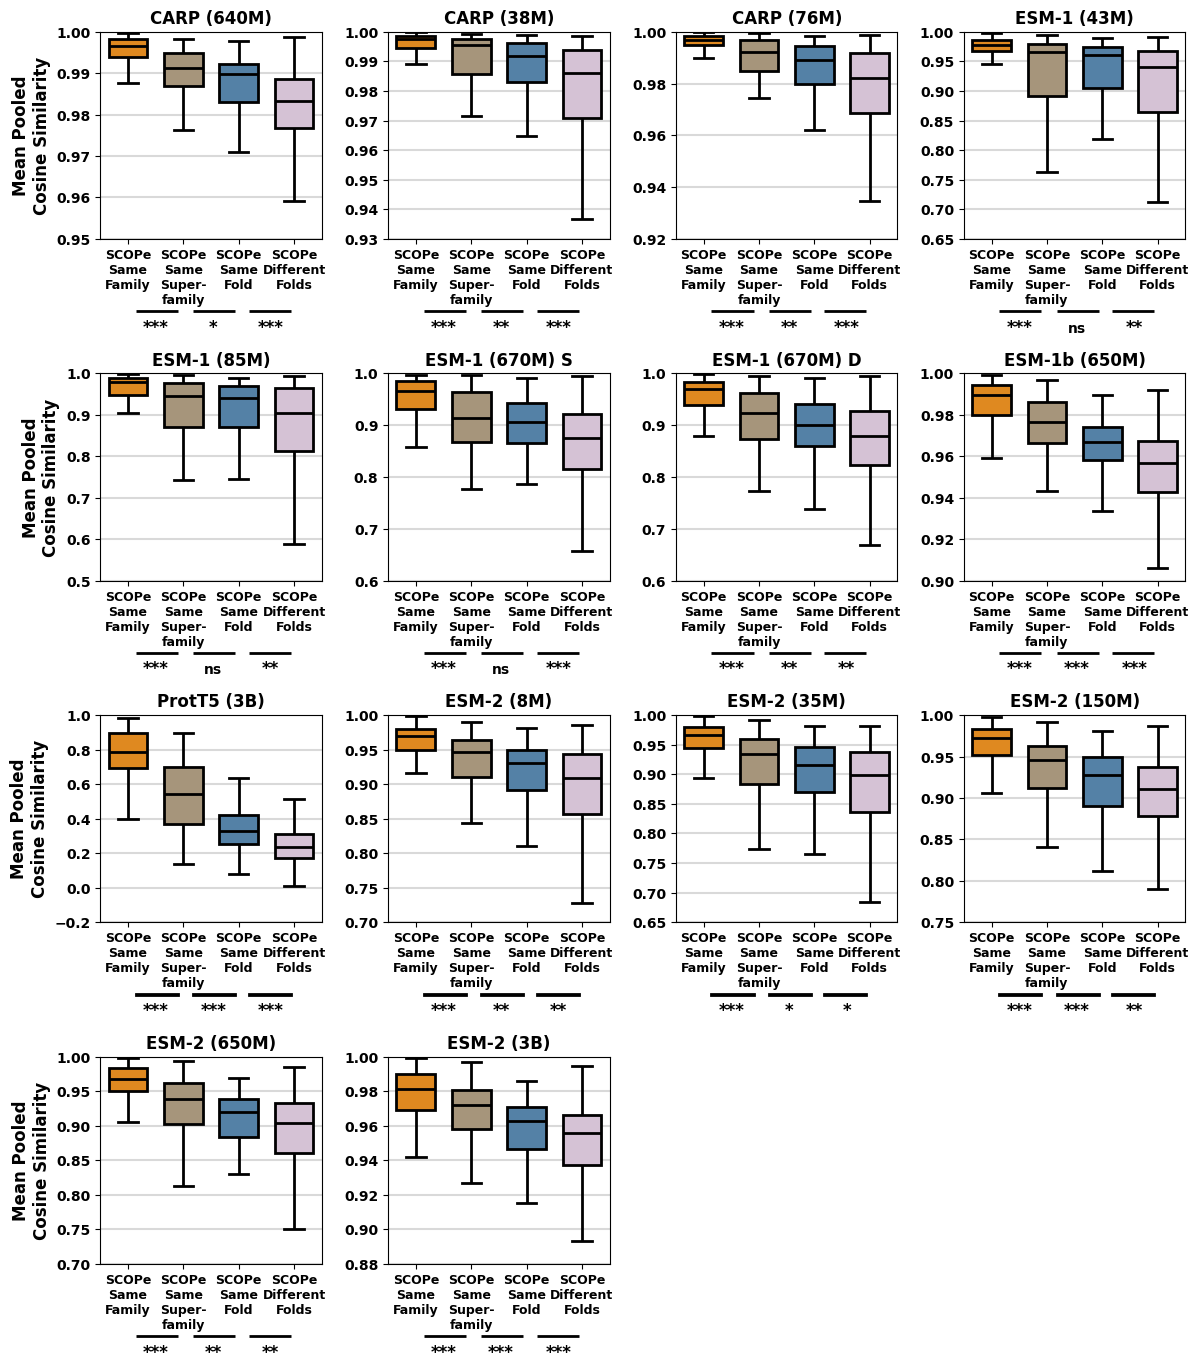

In [47]:

data_export_list = []

models_in_question = [
    "carp_640M",
    "carp_38M",
    "carp_76M",
    "esm_1_43M",
    "esm_1_85M",
    "esm_1_UR50",
    "esm_1_UR50D",
    "esm_1b",
    "prott5_xl",
     "esm_2_8M",
    "esm_2_35M",
    "esm_2_150M",
    "esm_2_650M", 
    "esm_2", # ESM-2 15B is in the main text 
]


fig, axes = plt.subplots(4,4, figsize = (14, 16))

fig.subplots_adjust(wspace = 0.3, hspace = 0.65)

axes = axes.ravel()

for ax_i, wanted_model in enumerate(models_in_question):
    
    export_list = []
    
    
    export_list.append(model_to_display_b[wanted_model].replace("\n", " "))
    
    ax = axes[ax_i]
    
    scope_data = scope_classes_data[wanted_model]

    data = []
    my_pal = {}

    i = 0

    v1 = scope_data["family_res"]
    data.append(v1)
    my_pal[str(i)] = "darkorange"
    i += 1
    export_list.append("|".join(list(map(lambda x : str(x), v1))))

    v1 = scope_data["superfamily_res"]
    data.append(v1)
    my_pal[str(i)] = "#ad9674"
    i += 1
    export_list.append("|".join(list(map(lambda x : str(x), v1))))

    v1 = scope_data["fold_res"]
    data.append(v1)
    my_pal[str(i)] = "steelblue"
    i += 1
    export_list.append("|".join(list(map(lambda x : str(x), v1))))

    v1 = scope_data["diff_fold_res"]
    data.append(v1)
    my_pal[str(i)] = "thistle"
    i += 1
    export_list.append("|".join(list(map(lambda x : str(x), v1))))

    sns.boxplot(
        data, 
        color = "black", 
        boxprops=dict(linewidth=2, edgecolor='black', zorder = 100),
        medianprops=dict(linewidth=2, color='black', zorder = 100),
        whiskerprops=dict(linewidth=2, color='black', zorder = 100),
        capprops = dict(linewidth=2, color='black', zorder = 100),
        showfliers = False,
        palette = my_pal,
        width = 0.7,
        ax=ax
    )

    labels = [
        "SCOPe\nSame\nFamily",
        "SCOPe\nSame\nSuper-\nfamily",
        "SCOPe\nSame\nFold",
        "SCOPe\nDifferent\nFolds"
    ]

    rect_points = [
        (0.16, -0.35), 
        (0.42, -0.35), 
        (0.67, -0.35), 
    ]


    ax.set_yticks(ax.get_yticks())
    ax.set_ylim(top = 1.0)

    for i, r_points in enumerate(rect_points):
        rect = mpatches.Rectangle(
            r_points, 
            0.19, 
            0.001, 
            transform = ax.transAxes, 
            clip_on=False, 
            linewidth=2, 
            edgecolor="black", 
            color = "black"
        )
        ax.add_patch(rect)

        p_val = scipy.stats.mannwhitneyu(data[i], data[i+1], alternative = "greater")[1]
        stars = p_val_to_stars(p_val)
        
        export_list.append(p_val)


        fs=12
        if stars == "ns":
            fs = 10
        ax.text(0.25 + (0.01*i) + (0.25*i), -0.45, stars,fontsize = fs,transform = ax.transAxes,fontweight = "bold", horizontalalignment="center")


    ax.set_xticklabels(labels, fontweight = "bold", fontsize = 9)

    for y in ax.get_yticks():
        ax.axhline(y = y, color = "black", alpha = 0.15, zorder = 1)

        ax.set_yticklabels(ax.get_yticklabels(), fontweight = "bold")
    
    if ax_i % 4 == 0:
        
        ax.set_ylabel("Mean Pooled\nCosine Similarity", fontweight = "bold", fontsize = 12)


    ax.set_title(model_to_display_b[wanted_model], fontweight = "bold")
    
    data_export_list.append(export_list)
    
    
fig.delaxes(axes[-1])
fig.delaxes(axes[-2])


In [48]:
data_export_df = pd.DataFrame(
    data_export_list, 
    columns = [
        "model",
        "SCOPe same family",
        "SCOPe same superfamily",
        "SCOPe same fold",
        "SCOPe different fold",
        "one sided MWU p value same family vs. same superfamily",
        "one sided MWU p value same superfamily vs. same fold",
        "one sided MWU p value same fold vs. different fold"    
    ]
)

data_export_df.to_csv(data_output_path + "fig_E7/data_E7a.csv", index = False)
data_export_df


,model,SCOPe same family,SCOPe same superfamily,SCOPe same fold,SCOPe different fold,one sided MWU p value same family vs. same superfamily,one sided MWU p value same superfamily vs. same fold,one sided MWU p value same fold vs. different fold
0,CARP (640M),0.9987280538420225|0.9926030240101575|0.997449...,0.9955463028929619|0.9886120490004519|0.993243...,0.9829627079778764|0.991849654197715|0.9855593...,0.9972737388939291|0.9948739901278237|0.996134...,1.097796e-10,1.134129e-02,1.328602e-08
1,CARP (38M),0.9976713208168768|0.9975847931560882|0.986716...,0.997149543854635|0.9980328480395722|0.9934999...,0.9850341435052037|0.9937184709302396|0.982171...,0.996316695959866|0.9892120299585361|0.9944313...,7.851470e-06,8.094634e-03,1.216479e-05
2,CARP (76M),0.9984160704001122|0.993868330696005|0.9967346...,0.9970052348765195|0.9849287465672019|0.995093...,0.979058036453631|0.9870425180717424|0.9828250...,0.9970721558335789|0.9859845376980065|0.994952...,1.701622e-07,7.968778e-03,4.001189e-06
3,ESM-1 (43M),0.9861825|0.97359705|0.95945024|0.9869089|0.97...,0.9830002|0.93592787|0.9688913|0.9655057|0.966...,0.96592283|0.94998163|0.93026435|0.960408|0.96...,0.9833623|0.9682084|0.97319305|0.95979637|0.98...,5.303415e-06,1.949737e-01,1.056122e-03
4,ESM-1 (85M),0.9858531|0.9329715|0.87243044|0.98598504|0.98...,0.9782957|0.7682697|0.965763|0.9621389|0.86709...,0.94871366|0.87769735|0.8731061|0.97582036|0.9...,0.99207664|0.97339153|0.9705163|0.967716|0.987...,8.925716e-07,2.792529e-01,1.729950e-03
5,ESM-1 (670M) S,0.9314561|0.9132016|0.96404207|0.9765435|0.985...,0.94773775|0.84679383|0.95688343|0.9692493|0.9...,0.8903605|0.9370515|0.732183|0.976661|0.566992...,0.9939335|0.98442173|0.9873264|0.98080724|0.99...,5.639796e-07,1.445772e-01,1.265285e-04
6,ESM-1 (670M) D,0.9631971|0.9155907|0.98084617|0.97777045|0.97...,0.93731606|0.8501905|0.95397764|0.97125906|0.8...,0.88914406|0.943862|0.7806911|0.9096271|0.6348...,0.9941372|0.98472583|0.97054434|0.9842783|0.97...,1.440294e-07,8.031489e-03,3.371042e-03
7,ESM-1b (650M),0.9933548|0.98458576|0.99555236|0.99462694|0.9...,0.98823315|0.97428745|0.9789607|0.9814204|0.96...,0.9679907|0.9841712|0.96952915|0.9686602|0.943...,0.99091244|0.97519517|0.98361415|0.9783531|0.9...,2.227350e-09,2.789551e-06,2.492299e-07
8,ProtT5 (3B),0.9402978|0.7635541|0.92048764|0.91843015|0.53...,0.7478025|0.7015454|0.27823138|0.3180145|0.281...,0.29400328|0.58455193|0.54932964|0.39720845|0....,0.7279959|0.38285446|0.5796963|0.5118276|0.580...,1.354327e-14,7.013012e-10,4.070745e-11
9,ESM-2 (8M),0.9657887|0.9530661|0.9653662|0.97919697|0.947...,0.9470061|0.97034353|0.93233883|0.9143898|0.94...,0.9351864|0.93874496|0.90037274|0.92504793|0.9...,0.9547068|0.8938077|0.90982974|0.8712782|0.948...,1.255726e-07,5.035005e-03,3.386111e-03


In [49]:
models_in_question = [
#     "carp_640M",
#     "carp_38M",
#     "carp_76M", # no CLS on these 
    "esm_1_43M",
    "esm_1_85M",
    "esm_1_UR50",
    "esm_1_UR50D",
    "esm_1b",
#     "prott5_xl", # no CLS on this 
    
]


for wanted_model in models_in_question:

    with open(data_path + wanted_model  + "/all_romote_homologs_seqeunces.pkl", "rb") as f1:
        data = pickle.load(f1)
    f1.close()
    
    wanted_pool_method = "cls_pooled"

    family_res = []

    for index, row in family_pairs.iterrows():
        p1 = row["id_1"]
        p2 = row["id_2"]


        emb_1 = data[p1][wanted_pool_method]
        emb_2 = data[p2][wanted_pool_method]

        cos_sim = cosine_similarity([emb_1], [emb_2])[0][0]

        family_res.append(cos_sim)

    superfamily_res = []
    for index, row in superfamily_pairs.iterrows():
        p1 = row["id_1"]
        p2 = row["id_2"]


        emb_1 = data[p1][wanted_pool_method]
        emb_2 = data[p2][wanted_pool_method]

        cos_sim = cosine_similarity([emb_1], [emb_2])[0][0]

        superfamily_res.append(cos_sim)

    fold_res = []
    for index, row in fold_pairs.iterrows():
        p1 = row["id_1"]
        p2 = row["id_2"]


        emb_1 = data[p1][wanted_pool_method]
        emb_2 = data[p2][wanted_pool_method]

        cos_sim = cosine_similarity([emb_1], [emb_2])[0][0]

        fold_res.append(cos_sim)

    different_fold_res = []

    dfa = pd.read_csv(supp_table_path + "top_bottom_homologs_pairs_scope_distances.csv")
    diff_folds = dfa.loc[dfa["model"] == "ESM-2 (8M)"] # can be any model just need the pairs

    for index, row in diff_folds.iterrows():
        p1 = row["protein_1"]
        p2 = row["protein_2"]


        emb_1 = data[p1][wanted_pool_method]
        emb_2 = data[p2][wanted_pool_method]

        cos_sim = cosine_similarity([emb_1], [emb_2])[0][0]

        different_fold_res.append(cos_sim)


    scope_classes_data[wanted_model] = {
        "family_res" : family_res,
        "superfamily_res" : superfamily_res,
        "fold_res" : fold_res,
        "diff_fold_res" : different_fold_res
    }





In [50]:
## data from ESM-2 models 

m2_list = [
    "esm_2_8M",
    "esm_2_35M",
    "esm_2_150M",
    "esm_2_650M", 
    "esm_2", 
    "esm_2_15B"
]

d3 = {
    "esm_2_8M" : "ESM-2 (8M)",
    "esm_2_35M": "ESM-2 (35M)",
    "esm_2_150M" : "ESM-2 (150M)",
    "esm_2_650M" : "ESM-2 (650M)",
    "esm_2" : "ESM-2 (3B)",
    "esm_2_15B" : "ESM-2 (15B)",
}

dfc = pd.read_csv(supp_table_path + "scope_orphanage_choices_with_distances.csv")

family_pairs = dfc.loc[dfc["grouping"] == "same_family"]
superfamily_pairs = dfc.loc[dfc["grouping"] == "same_superfamily_different_family"]
fold_pairs = dfc.loc[dfc["grouping"] == "same_fold_different_superfamily"]

for wanted_model in m2_list:
    
    
    dfa = pd.read_csv(supp_table_path + "top_bottom_homologs_pairs_scope_distances.csv")
    diff_folds = dfa.loc[dfa["model"] == d3[wanted_model]] # can be any model just need the pairs
    print(len(diff_folds))
    scope_classes_data[wanted_model] = {
        "family_res" : family_pairs[wanted_model + "_CLS"].values,
        "superfamily_res" : superfamily_pairs[wanted_model+ "_CLS"].values,
        "fold_res" : fold_pairs[wanted_model+ "_CLS"].values,
        "diff_fold_res" : diff_folds["cos_sim_cls"].values
    }
    
    
cls_pooled_scope_classes = copy.deepcopy(scope_classes_data)
    

1189
1189
1189
1189
1189
1189


/tmp/ipykernel_1803507/4037968608.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_1803507/4037968608.py:84: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  rect = mpatches.Rectangle(
/tmp/ipykernel_1803507/4037968608.py:106: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(labels, fontweight = "bold", fontsize = 9)
/tmp/ipykernel_1803507/4037968608.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_1803507/4037968608.py:84: UserWarning: Setting the 'color' property will override the edgecolor or facecolor

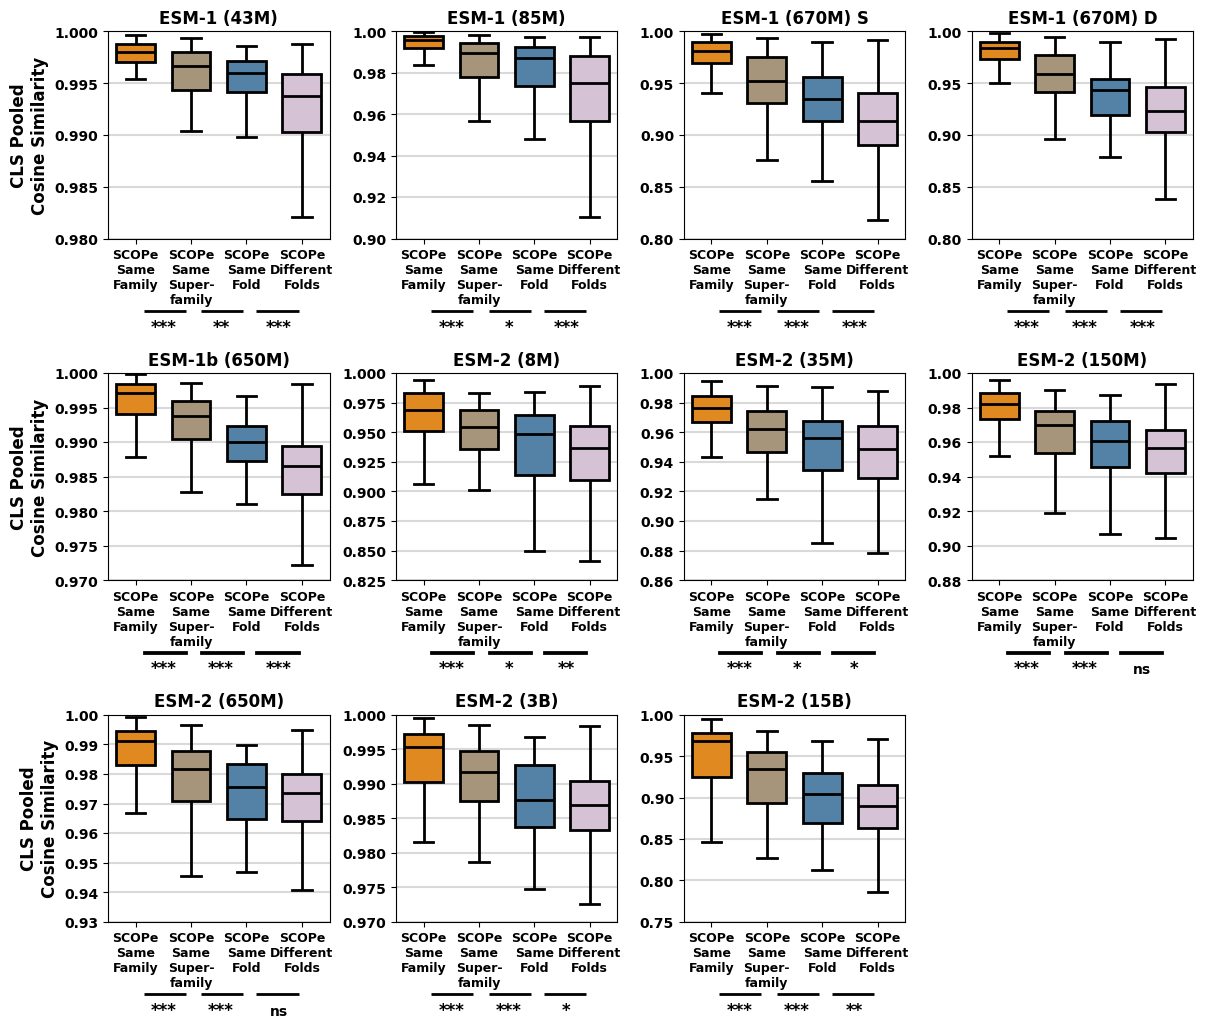

In [51]:

models_in_question = [
    "esm_1_43M",
    "esm_1_85M",
    "esm_1_UR50",
    "esm_1_UR50D",
    "esm_1b",
    "esm_2_8M",
    "esm_2_35M",
    "esm_2_150M",
    "esm_2_650M", 
    "esm_2", # ESM-2 15B is in the main text 
    "esm_2_15B"
]


fig, axes = plt.subplots(4,4, figsize = (14, 16))

fig.subplots_adjust(wspace = 0.3, hspace = 0.65)

axes = axes.ravel()

for ax_i, wanted_model in enumerate(models_in_question):
    ax = axes[ax_i]
    
    scope_data = scope_classes_data[wanted_model]

    data = []
    my_pal = {}

    i = 0

    v1 = scope_data["family_res"]
    data.append(v1)
    my_pal[str(i)] = "darkorange"
    i += 1


    v1 = scope_data["superfamily_res"]
    data.append(v1)
    my_pal[str(i)] = "#ad9674"
    i += 1

    v1 = scope_data["fold_res"]
    data.append(v1)
    my_pal[str(i)] = "steelblue"
    i += 1

    v1 = scope_data["diff_fold_res"]
    data.append(v1)
    my_pal[str(i)] = "thistle"
    i += 1

    sns.boxplot(
        data, 
        color = "black", 
        boxprops=dict(linewidth=2, edgecolor='black', zorder = 100),
        medianprops=dict(linewidth=2, color='black', zorder = 100),
        whiskerprops=dict(linewidth=2, color='black', zorder = 100),
        capprops = dict(linewidth=2, color='black', zorder = 100),
        showfliers = False,
        palette = my_pal,
        width = 0.7,
        ax=ax
    )

    labels = [
        "SCOPe\nSame\nFamily",
        "SCOPe\nSame\nSuper-\nfamily",
        "SCOPe\nSame\nFold",
        "SCOPe\nDifferent\nFolds"
    ]

    rect_points = [
        (0.16, -0.35), 
        (0.42, -0.35), 
        (0.67, -0.35), 
    ]


    ax.set_yticks(ax.get_yticks())
    ax.set_ylim(top = 1.0)

    for i, r_points in enumerate(rect_points):
        rect = mpatches.Rectangle(
            r_points, 
            0.19, 
            0.001, 
            transform = ax.transAxes, 
            clip_on=False, 
            linewidth=2, 
            edgecolor="black", 
            color = "black"
        )
        ax.add_patch(rect)

        p_val = scipy.stats.mannwhitneyu(data[i], data[i+1], alternative = "greater")[1]
        stars = p_val_to_stars(p_val)


        fs=12
        if stars == "ns":
            fs = 10
        ax.text(0.25 + (0.01*i) + (0.25*i), -0.45, stars,fontsize = fs,transform = ax.transAxes,fontweight = "bold", horizontalalignment="center")


    ax.set_xticklabels(labels, fontweight = "bold", fontsize = 9)

    for y in ax.get_yticks():
        ax.axhline(y = y, color = "black", alpha = 0.15, zorder = 1)

        ax.set_yticklabels(ax.get_yticklabels(), fontweight = "bold")
    
    if ax_i % 4 == 0:
        
        ax.set_ylabel("CLS Pooled\nCosine Similarity", fontweight = "bold", fontsize = 12)


    ax.set_title(model_to_display_b[wanted_model], fontweight = "bold")
    
    
fig.delaxes(axes[-1])
fig.delaxes(axes[-2])
fig.delaxes(axes[-3])
fig.delaxes(axes[-4])
fig.delaxes(axes[-5])

In [52]:
# making tables scope choices 


model_to_display_b = {
    "carp_640M" : "CARP (640M)",
    "carp_38M": "CARP (38M)",
    "carp_76M": "CARP (76M)",
    "prott5_xl" : "ProtT5 (3B)",
    "esm_1b": "ESM-1b (650M)",
    "esm_1_43M": "ESM-1 (43M)",
    "esm_1_85M": "ESM-1 (85M)",
    "esm_1_UR50": "ESM-1 (670M) S",
    "esm_1_UR50D": "ESM-1 (670M) D",
    "esm_2_150M": "ESM-2 (150M)",
    "esm_2_15B": "ESM-2 (15B)",
    "esm_2_35M": "ESM-2 (35M)",
    "esm_2": "ESM-2 (3B)",
    "esm_2_650M": "ESM-2 (650M)",
    "esm_2_8M": "ESM-2 (8M)",
}

models_in_question = [
    "carp_640M",
    "carp_38M",
    "carp_76M",
    "esm_1_43M",
    "esm_1_85M",
    "esm_1_UR50",
    "esm_1_UR50D",
    "esm_1b",
    "prott5_xl",
    
]

non_cls_models = [
    "prott5_xl",
    "carp_640M",
    "carp_38M",
    "carp_76M",
]


dfc = pd.read_csv(supp_table_path + "scope_orphanage_choices_with_distances.csv")

df_spine = copy.deepcopy(dfc) 

for wanted_model in models_in_question:
    
    using_cls = wanted_model not in non_cls_models
    
    mean_pool_list = []
    cls_pool_list = []
    
    with open(data_path + wanted_model  + "/all_romote_homologs_seqeunces.pkl", "rb") as f1:
        data = pickle.load(f1)
    f1.close()
    

    for index, row in df_spine.iterrows():
        
        p1 = row["id_1"]
        p2 = row["id_2"]
        
        emb_1 = data[p1]["mean_pooled"]
        emb_2 = data[p2]["mean_pooled"]

        cos_sim = cosine_similarity([emb_1], [emb_2])[0][0]
        
        mean_pool_list.append(cos_sim)
        
        if using_cls:
            
            emb_1 = data[p1]["cls_pooled"]
            emb_2 = data[p2]["cls_pooled"]
            cos_sim = cosine_similarity([emb_1], [emb_2])[0][0]
            cls_pool_list.append(cos_sim)
            
            
    df_spine[model_to_display_b[wanted_model] + " Mean Pooled"] = mean_pool_list
    if using_cls:
        df_spine[model_to_display_b[wanted_model] + " CLS Pooled"] = cls_pool_list

column_swaps = {
    "esm_2" : "ESM-2 (3B) Mean Pooled",
    "esm_2_15B" : "ESM-2 (15B) Mean Pooled",
    "esm_2_150M" : "ESM-2 (150M) Mean Pooled",
    "esm_2_650M" : "ESM-2 (650M) Mean Pooled",
    "esm_2_35M" : "ESM-2 (35M) Mean Pooled",
    "esm_2_8M" : "ESM-2 (8M) Mean Pooled",
    "esm_2_CLS" : "ESM-2 (3B) CLS Pooled",
    "esm_2_15B_CLS" : "ESM-2 (15B) CLS Pooled",
    "esm_2_150M_CLS" : "ESM-2 (150M) CLS Pooled",
    "esm_2_650M_CLS" : "ESM-2 (650M) CLS Pooled",
    "esm_2_35M_CLS" : "ESM-2 (35M) CLS Pooled",
    "esm_2_8M_CLS" : "ESM-2 (8M) CLS Pooled",
    
}


df_spine = df_spine.rename(columns = column_swaps)
df_spine.to_csv(supp_table_path + "revisions/r_scope_orphanage_choices_with_distances.csv")  

In [53]:
def get_all_pairs(lst):
    res = [(a, b) for idx, a in enumerate(lst) for b in lst[idx + 1:]]
    return res

In [54]:
models_in_question = [
    "carp_640M",
    "carp_38M",
    "carp_76M", # no CLS on these 
    "esm_1_43M",
    "esm_1_85M",
    "esm_1_UR50",
    "esm_1_UR50D",
    "esm_1b",
    "prott5_xl", # no CLS on this 
    
]

model_to_emb_intra_group_sims = {}

model_to_table_df = {}


for wanted_model in models_in_question:
    

    dfg = pd.read_csv(supp_table_path + "random_seq_intra_group_mean_pool_dists.csv")


    with open(f"../../../revisions/data/orphanage/orphanage_extractions/{wanted_model}/embedding_space_used_seqeunces.pkl", "rb") as f1:
        data = pickle.load(f1)
    f1.close()

    # just getting pairs, can be any model 
    dfg_pairs = dfg.loc[dfg["model"] == "ESM-2 (8M)"]


    wanted_pool_method = "mean_pooled"

    sub_df_tracker_list = []

    seq_group_to_cos_sim_list = {}

    for seq_group, sub_df in dfg_pairs.groupby("sequence_group"):

        cs_list = []

        for index, row in sub_df.iterrows():
            p1 = row["protein_1"]
            p2 = row["protein_2"]

            emb_1 = data[p1][wanted_pool_method]
            emb_2 = data[p2][wanted_pool_method]
            cos_sim = cosine_similarity([emb_1], [emb_2])[0][0]
            cs_list.append(cos_sim)

        seq_group_to_cos_sim_list[seq_group] = cs_list

        sub_df_2 = copy.deepcopy(sub_df)

        sub_df_2["mean_pool_cosine_sim"] = cs_list    
        sub_df_2["model"] = wanted_model
        sub_df_tracker_list.append(sub_df_2)
        
    model_to_emb_intra_group_sims[wanted_model] = seq_group_to_cos_sim_list
    model_to_table_df[wanted_model] = pd.concat(sub_df_tracker_list)
    

In [55]:
dfg = pd.read_csv(supp_table_path + "random_seq_intra_group_mean_pool_dists.csv")
df_pieces = []
for model, table_df in model_to_table_df.items():
    table_df["model"] = model_to_display_b[model]
    df_pieces.append(table_df)
    
df_pieces.append(dfg)

removing_groups = ["markov_window_16", "markov_window_15", "markov_window_14", "markov_window_13", "markov_window_12"]

df_out = pd.concat(df_pieces)
df_out["sequence_group"].value_counts()
df_out = df_out.loc[~df_out["sequence_group"].isin(removing_groups)]
df_out.to_csv(supp_table_path + "revisions/r_random_seq_intra_group_mean_pool_dists.csv")



In [56]:
dfg = pd.read_csv(supp_table_path + "random_seq_intra_group_mean_pool_dists.csv")

for model, model_df in dfg.groupby("model"):
    seq_group_to_cos_sim_list = {}
    for seq_group, sub_df in model_df.groupby("sequence_group"):
        seq_group_to_cos_sim_list[seq_group] = sub_df["mean_pool_cosine_sim"].values
        
    model_to_emb_intra_group_sims[model] = seq_group_to_cos_sim_list

In [57]:


m_to_display_c = {
    'carp_640M' : "CARP 640M", 
    'carp_38M': "CARP 38M", 
    'carp_76M': "CARP 76M", 
    'esm_1_43M' : "ESM-1 43M", 
    'esm_1_85M': "ESM-1 85M", 
    'esm_1_UR50': "ESM-1 670M (S)",  
    'esm_1_UR50D': "ESM-1 670M (D)",  
    'esm_1b': "ESM-1b 650M",  
    'prott5_xl': "ProtT5 3B", 
    'ESM-2 (150M)': "ESM-2 150M", 
    'ESM-2 (15B)': "ESM-2 15B",  
    'ESM-2 (35M)': "ESM-2 35M", 
    'ESM-2 (3B)': "ESM-2 3B",
    'ESM-2 (650M)': "ESM-2 650M", 
    'ESM-2 (8M)': "ESM-2 8M", 
}

d2 = {
    'ESM-2 (8M)': 'esm_2_8M', 
    'ESM-2 (35M)': 'esm_2_35M', 
    'ESM-2 (150M)': 'esm_2_150M', 
    'ESM-2 (650M)': 'esm_2_650M', 
    'ESM-2 (3B)': 'esm_2',
    'ESM-2 (15B)':"esm_2_15B"
}

/tmp/ipykernel_1803507/2737392643.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_1803507/2737392643.py:70: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  rect = mpatches.Rectangle(


Text(0.5, 1.0, 'CARP 640M')

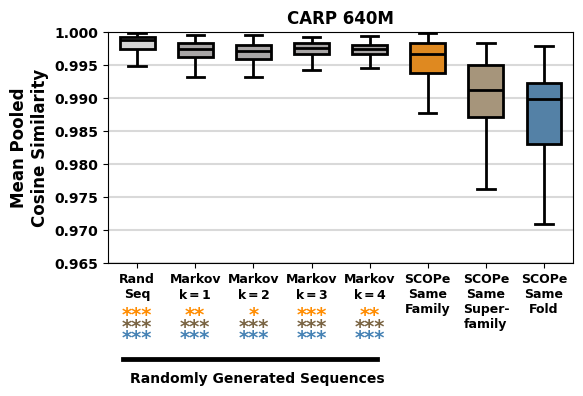

In [58]:
wanted_model = "carp_640M"
intra_group_sims = model_to_emb_intra_group_sims[wanted_model]

data = [
    intra_group_sims['RandSeq'], 
    intra_group_sims['markov_window_1'], 
    intra_group_sims['markov_window_2'], 
    intra_group_sims['markov_window_3'], 
    intra_group_sims['markov_window_4'], 
    mean_pooled_scope_classes[wanted_model]['family_res'],
    mean_pooled_scope_classes[wanted_model]['superfamily_res'],
    mean_pooled_scope_classes[wanted_model]['fold_res'],   
]



c_list = ["lightgray","#a8a5a5","#a8a5a5","#a8a5a5","#a8a5a5", "darkorange","#ad9674", "steelblue"]
fig, ax = plt.subplots(figsize = (6,3))

sns.boxplot(
    data, 
    color = "black", 
    boxprops=dict(linewidth=2, edgecolor='black', zorder = 100),
    medianprops=dict(linewidth=2, color='black', zorder = 100),
    whiskerprops=dict(linewidth=2, color='black', zorder = 100),
    capprops = dict(linewidth=2, color='black', zorder = 100),
    showfliers = False,
    palette = c_list,
    width = 0.6,
    ax = ax
)

labels = [
    "Rand\nSeq",
    "Markov\n$\mathbf{k=1}$",
    "Markov\n$\mathbf{k=2}$",
    "Markov\n$\mathbf{k=3}$", 
    "Markov\n$\mathbf{k=4}$",
    "SCOPe\nSame\nFamily",
    "SCOPe\nSame\nSuper-\nfamily",
    "SCOPe\nSame\nFold",
]

ax.set_xticks(ax.get_xticks())
ax.set_xticklabels(labels, fontsize = 9, fontweight = "bold")

for i in range(0, len(data) - 3):
        
    st1, p1 = scipy.stats.mannwhitneyu(data[i], data[-3], alternative = "greater")
    stars_1 = p_val_to_stars(p1)

    ax.text((i+0.5)/len(data), -0.23 if stars_1 == "ns" else -0.25, "n s" if stars_1 == "ns" else stars_1, color = "darkorange", fontsize = 9 if stars_1 == "ns" else 14, fontweight = "bold", horizontalalignment="center", transform = ax.transAxes)

    st1, p2 = scipy.stats.mannwhitneyu(data[i], data[-2], alternative = "greater")
    stars_2 = p_val_to_stars(p2)
    ax.text((i+0.5)/len(data), -0.28 if stars_2 == "ns" else -0.3, "n s" if stars_2 == "ns" else stars_2, color = "#7a6443", fontsize = 9 if stars_2 == "ns" else 14, fontweight = "bold", horizontalalignment="center", transform = ax.transAxes)

    st1, p3 = scipy.stats.mannwhitneyu(data[i], data[-1], alternative = "greater")
    stars_3 = p_val_to_stars(p3)
    ax.text((i+0.5)/len(data), -0.35, "n s" if stars_3 == "ns" else stars_3, color = "steelblue", fontsize = 9 if stars_3 == "ns" else 14, horizontalalignment="center", fontweight = "bold",  transform = ax.transAxes)

    
ax.set_ylabel("Mean Pooled\nCosine Similarity", fontsize = 12, fontweight = "bold")
ax.set_yticks(ax.get_yticks())
ax.set_ylim(top = 1.)

for y in ax.get_yticks():
    ax.axhline(y = y, color = "black", alpha = 0.15, zorder = 1)

rect = mpatches.Rectangle(
    (0.03, -0.42), 
    0.55, 
    0.01, 
    transform = ax.transAxes, 
    clip_on=False, 
    linewidth=2, 
    edgecolor="black", 
    color = "black"
)
ax.add_patch(rect)
ax.set_yticklabels(ax.get_yticklabels(), fontweight = "bold")

ax.text(0.32, -0.52, "Randomly Generated Sequences", horizontalalignment = "center", transform = ax.transAxes, fontweight = "bold")
ax.set_title(m_to_display_c[wanted_model], fontweight = "bold")


/tmp/ipykernel_1803507/3529634475.py:56: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_1803507/3529634475.py:137: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  rect = mpatches.Rectangle(
/tmp/ipykernel_1803507/3529634475.py:56: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_1803507/3529634475.py:137: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  rect = mpatches.Rectangle(
/tmp/ipykernel_1803507/3529634475.py:56: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `le

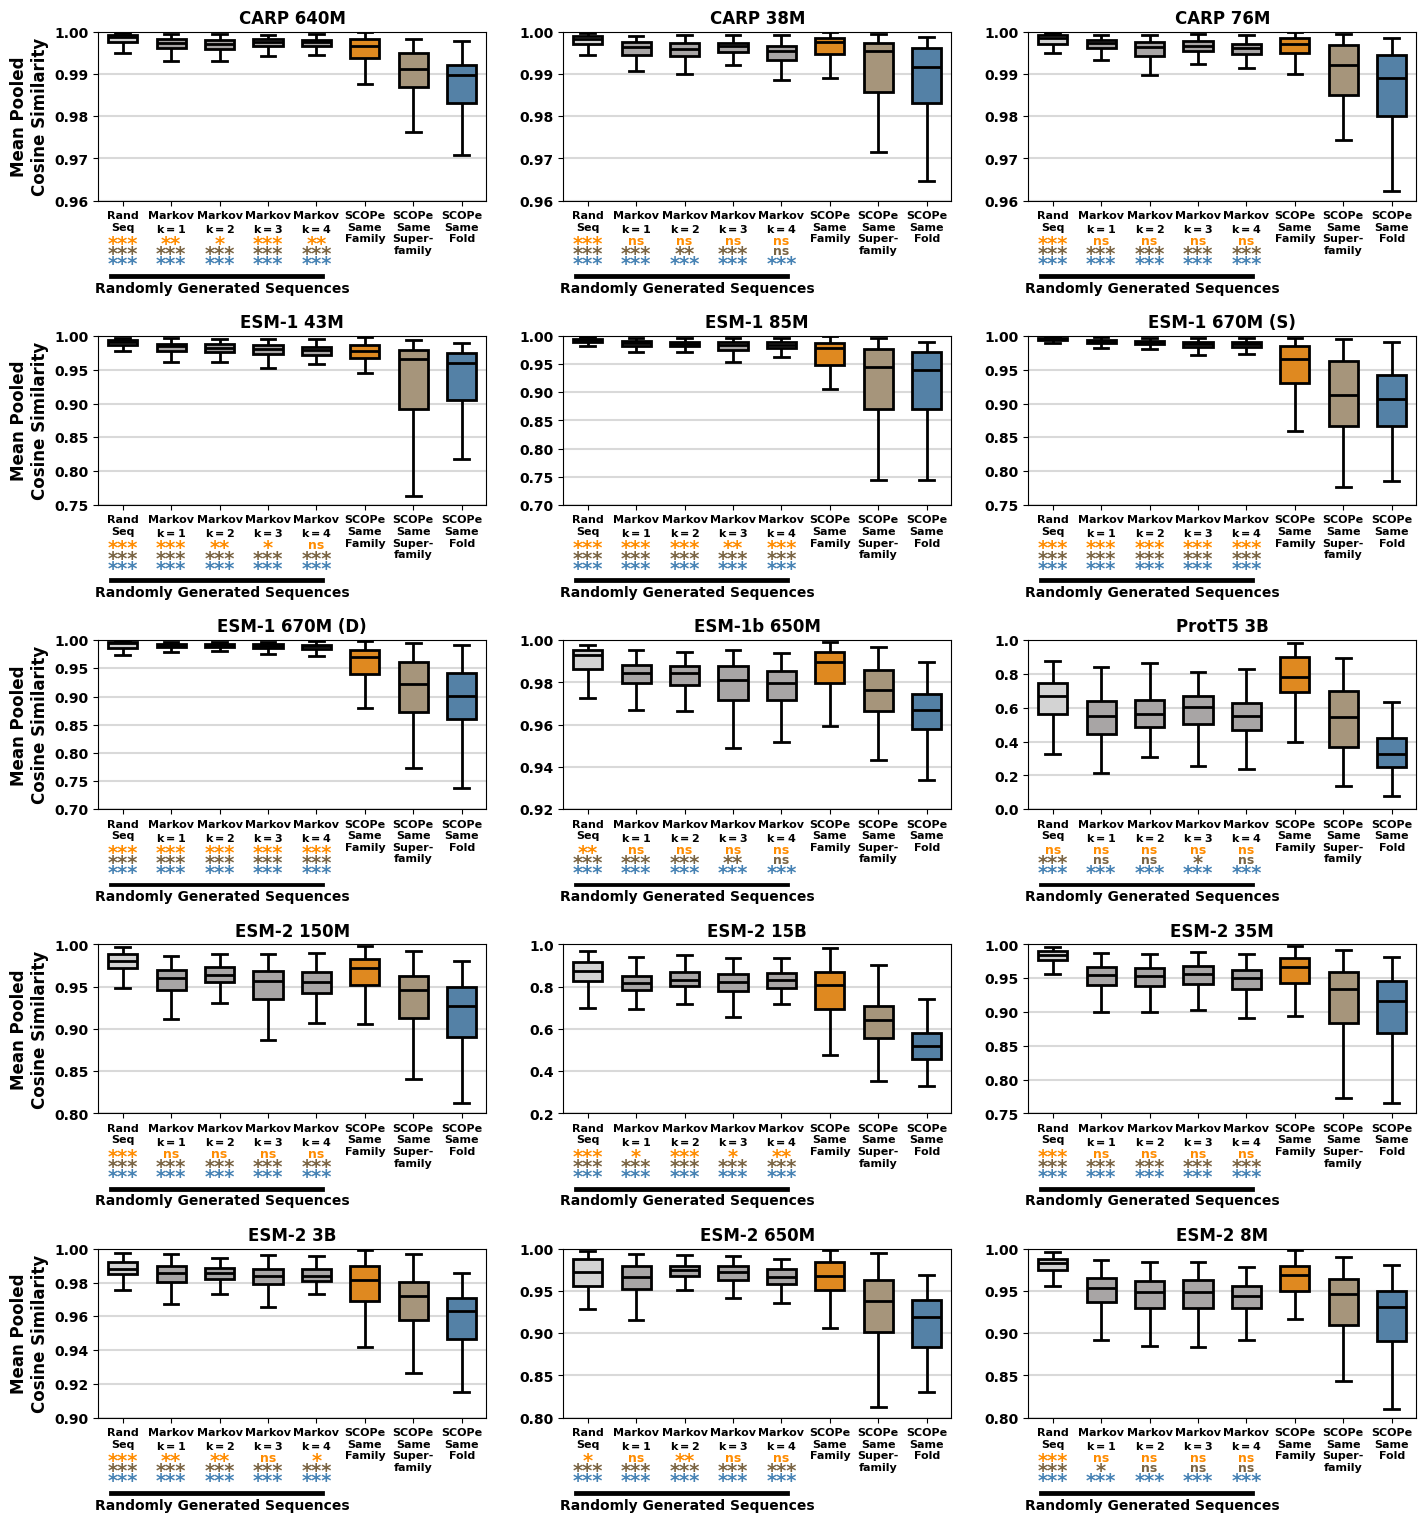

In [59]:
fig, axes = plt.subplots(5,3,figsize = (17,18))
axes = axes.ravel()

fig.subplots_adjust(hspace = 0.8)

wanted_models = [
    "carp_640M",
    "carp_38M",
    "carp_76M",
    "esm_1_43M",
    "esm_1_85M",
    "esm_1_UR50",
    "esm_1_UR50D",
    "esm_1b",
    "prott5_xl",
    "ESM-2 (150M)",
    "ESM-2 (15B)",
    "ESM-2 (35M)",
    "ESM-2 (3B)",
    "ESM-2 (650M)",
    "ESM-2 (8M)",
]
for ax_i, wanted_model in enumerate(wanted_models):
    ax = axes[ax_i]
    
    intra_group_sims = model_to_emb_intra_group_sims[wanted_model]

    if "ESM-2" in wanted_model:
        data = [
            intra_group_sims['RandSeq'], 
            intra_group_sims['markov_window_1'], 
            intra_group_sims['markov_window_2'], 
            intra_group_sims['markov_window_3'], 
            intra_group_sims['markov_window_4'], 
            mean_pooled_scope_classes[d2[wanted_model]]['family_res'],
            mean_pooled_scope_classes[d2[wanted_model]]['superfamily_res'],
            mean_pooled_scope_classes[d2[wanted_model]]['fold_res'],   
        ]
    else:

        data = [
            intra_group_sims['RandSeq'], 
            intra_group_sims['markov_window_1'], 
            intra_group_sims['markov_window_2'], 
            intra_group_sims['markov_window_3'], 
            intra_group_sims['markov_window_4'], 
            mean_pooled_scope_classes[wanted_model]['family_res'],
            mean_pooled_scope_classes[wanted_model]['superfamily_res'],
            mean_pooled_scope_classes[wanted_model]['fold_res'],   
        ]



    c_list = ["lightgray","#a8a5a5","#a8a5a5","#a8a5a5","#a8a5a5", "darkorange","#ad9674", "steelblue"]

    sns.boxplot(
        data, 
        color = "black", 
        boxprops=dict(linewidth=2, edgecolor='black', zorder = 100),
        medianprops=dict(linewidth=2, color='black', zorder = 100),
        whiskerprops=dict(linewidth=2, color='black', zorder = 100),
        capprops = dict(linewidth=2, color='black', zorder = 100),
        showfliers = False,
        palette = c_list,
        width = 0.6,
        ax = ax
    )

    labels = [
        "Rand\nSeq",
        "Markov\n$\mathbf{k=1}$",
        "Markov\n$\mathbf{k=2}$",
        "Markov\n$\mathbf{k=3}$", 
        "Markov\n$\mathbf{k=4}$",
        "SCOPe\nSame\nFamily",
        "SCOPe\nSame\nSuper-\nfamily",
        "SCOPe\nSame\nFold",
    ]

    ax.set_xticks(ax.get_xticks())
    ax.set_xticklabels(labels, fontsize = 8, fontweight = "bold")

    for i in range(0, len(data) - 3):

        st1, p1 = scipy.stats.mannwhitneyu(data[i], data[-3], alternative = "greater")
        stars_1 = p_val_to_stars(p1)

        ax.text(
            (i+0.5)/len(data), 
            -0.2, 
            "ns" if stars_1 == "ns" else stars_1, 
            color = "darkorange", 
            fontsize = 9 if stars_1 == "ns" else 14, 
            fontweight = "bold", 
            horizontalalignment="center", 
            transform = ax.transAxes, 
            verticalalignment = "top"
        )

        st1, p2 = scipy.stats.mannwhitneyu(data[i], data[-2], alternative = "greater")
        stars_2 = p_val_to_stars(p2)
        ax.text(
            (i+0.5)/len(data), 
            -0.26, 
            "ns" if stars_2 == "ns" else stars_2, 
            color = "#7a6443", 
            fontsize = 9 if stars_2 == "ns" else 14, 
            fontweight = "bold", 
            horizontalalignment="center", 
            transform = ax.transAxes, 
            verticalalignment = "top"
        )

        st1, p3 = scipy.stats.mannwhitneyu(data[i], data[-1], alternative = "greater")
        stars_3 = p_val_to_stars(p3)
        ax.text(
            (i+0.5)/len(data), 
            -0.32, 
            "ns" if stars_3 == "ns" else stars_3, 
            color = "steelblue", 
            fontsize = 9 if stars_3 == "ns" else 14, 
            horizontalalignment="center", 
            fontweight = "bold",  
            transform = ax.transAxes, 
            verticalalignment = "top"
        )

    if ax_i % 3 == 0:
        ax.set_ylabel("Mean Pooled\nCosine Similarity", fontsize = 12, fontweight = "bold")
        
    ax.set_yticks(ax.get_yticks())
    ax.set_ylim(top = 1.)

    for y in ax.get_yticks():
        ax.axhline(y = y, color = "black", alpha = 0.15, zorder = 1)

    rect = mpatches.Rectangle(
        (0.03, -0.45), 
        0.55, 
        0.01, 
        transform = ax.transAxes, 
        clip_on=False, 
        linewidth=2, 
        edgecolor="black", 
        color = "black"
    )
    ax.add_patch(rect)
    ax.set_yticklabels(ax.get_yticklabels(), fontweight = "bold")

    ax.text(0.32, -0.54, "Randomly Generated Sequences", horizontalalignment = "center", transform = ax.transAxes, fontweight = "bold")
    ax.set_title(m_to_display_c[wanted_model], fontweight = "bold")





In [60]:



model_to_mean_pool_df = {}


wanted_model_list = [
    "carp_640M",
    "carp_38M",
    "carp_76M",
    "esm_1_43M",
    "esm_1_85M",
    "esm_1_UR50",
    "esm_1_UR50D",
    "esm_1b",
    "prott5_xl",
]

dfh = pd.read_csv(supp_table_path + "orphanage_pcs_homologs_seqeunces_all_models_all_pooling.csv")
#can be any model/embedding type 
selected_group = dfh.loc[(dfh["model"] == "ESM-2 (150M)") & (dfh["embedding_type"] == "mean_pooled")]
ident_to_homologs = dict(zip(selected_group["name"].values,  selected_group["log_2 UR50 homologs"].values))

wanted_pool_method = "mean_pooled"


for wanted_model in wanted_model_list:
    
    # making names consistent
    keeping_cols = []
    # can be any model / pool method
    dist_df_original = pd.read_csv(f"../../../Orphan25/random_UR50_protein_embedding_experiment/all_distance_results/esm_2_150M__CLS.csv",index_col = 0)
    for k in list(dist_df_original.columns):
        keeping_cols.append(k.replace("Orphan25_", "").replace("randseq_", ""))

    df = pd.read_csv(f"../../../revisions/scripts/orphanage/results/{wanted_model}_{wanted_pool_method}.csv", index_col = 0)
    df = df[keeping_cols]

    ident_to_mean_dist = {}

    for index, row in df.iterrows():
        m1 = np.mean(row.values)
        ident_to_mean_dist[index] = m1

    df["orphanage_distance"] = ident_to_mean_dist


    with open(f"../../../revisions/data/orphanage/orphanage_extractions/{wanted_model}/UR50_sample_sequences.pkl", "rb") as f1:
        data = pickle.load(f1)
    f1.close()


    X = []
    identifiers = []

    for k, v in data.items():
        X.append(v[wanted_pool_method])
        identifiers.append(k)


    X = np.asarray(X)

    pca = PCA(n_components=2)  # Specify the number of components
    pca.fit(X)
    embedding = pca.transform(X)


    PC_1 = embedding[:, 0]
    PC_2 = embedding[:, 1]

    PC_1_dict = dict(zip(identifiers, PC_1))
    PC_2_dict = dict(zip(identifiers, PC_2))

    df["PC1"] = PC_1_dict
    df["PC2"] = PC_2_dict
    df["log_2 UR50 homologs"] = ident_to_homologs

    print(wanted_model)
#     print(scipy.stats.spearmanr(df["PC1"].values, df["orphanage_distance"].values))
#     print(scipy.stats.spearmanr(df["PC1"].values, df["homologs"].values))
#     print(scipy.stats.spearmanr(df["PC2"].values, df["orphanage_distance"].values))
    
    model_to_mean_pool_df[wanted_model] = copy.deepcopy(df)
    
dfh = pd.read_csv(supp_table_path + "orphanage_pcs_homologs_seqeunces_all_models_all_pooling.csv")

for m, sub_df in dfh.groupby("model"):
    sub_df = sub_df.loc[sub_df["embedding_type"] == "mean_pooled"]
    model_to_mean_pool_df[m] = copy.deepcopy(sub_df)

carp_640M
carp_38M
carp_76M
esm_1_43M
esm_1_85M
esm_1_UR50
esm_1_UR50D
esm_1b
prott5_xl


In [61]:
m_to_display_c = {
    'carp_640M' : "CARP 640M", 
    'carp_38M': "CARP 38M", 
    'carp_76M': "CARP 76M", 
    'esm_1_43M' : "ESM-1 43M", 
    'esm_1_85M': "ESM-1 85M", 
    'esm_1_UR50': "ESM-1 670M (S)",  
    'esm_1_UR50D': "ESM-1 670M (D)",  
    'esm_1b': "ESM-1b 650M",  
    'prott5_xl': "ProtT5 3B", 
    'ESM-2 (150M)': "ESM-2 150M", 
    'ESM-2 (15B)': "ESM-2 15B",  
    'ESM-2 (35M)': "ESM-2 35M", 
    'ESM-2 (3B)': "ESM-2 3B",
    'ESM-2 (650M)': "ESM-2 650M", 
    'ESM-2 (8M)': "ESM-2 8M", 
}

[0.9085872167899315, 0.9000221535337315, 0.9088424186299559, 0.8045336565643143, 0.8945546974996834, 0.9376844289871753, 0.9312416865002359, 0.8848128665731161, 0.8239361462312844, 0.893813198229042, 0.7862612058641077, 0.9080824765441541, 0.9069912940442667, 0.9119484100124072, 0.8528580307444579]


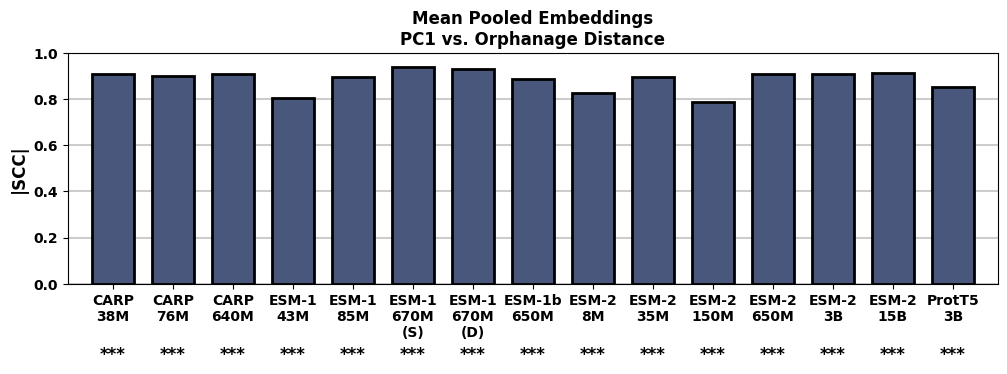

In [62]:
fig, ax = plt.subplots(figsize = (12,3))

model_order = [
    
    "carp_38M",
    "carp_76M",
    "carp_640M",
    "esm_1_43M",
    "esm_1_85M",
    "esm_1_UR50",
    "esm_1_UR50D",
    "esm_1b",
    "ESM-2 (8M)",
    "ESM-2 (35M)",
    "ESM-2 (150M)",
    "ESM-2 (650M)",
    "ESM-2 (3B)",
    "ESM-2 (15B)",
    "prott5_xl",
]


x = []
y = []

stars = []
labels = []

p_list = []

for i, m in enumerate(model_order):
    x1 = model_to_mean_pool_df[m]["PC1"].values
    x2 = model_to_mean_pool_df[m]["orphanage_distance"].values
    
    corr, p = scipy.stats.spearmanr(x1,x2)
    stars.append(p_val_to_stars(p))
    p_list.append(p)
    
    y.append(abs(corr))
    x.append(i)
    labels.append(m_to_display_c[m].replace(" ", "\n").replace("_", " "))
    
ax.set_xticks(x)
ax.set_xticklabels(labels, fontweight = "bold")
ax.bar(x,y,color = "#4a577d", edgecolor = "black", alpha = 1, width = 0.7, linewidth = 2, zorder = 100)
ax.set_yticks(ax.get_yticks())
ax.set_yticklabels(ax.get_yticklabels(), fontweight = "bold")
ax.set_ylabel("|SCC|", fontweight = "bold", fontsize = 12)

for y_val in ax.get_yticks():
    ax.axhline(y = y_val, color = "black", alpha = 0.2, zorder = 1)

ax.set_xlim(left = -0.75, right = len(labels) - 0.25)

for i, star_val in enumerate(stars):
    ax.text(i, -0.33, star_val, fontsize = 12, horizontalalignment = "center", fontweight = "bold")
    
ax.set_title("Mean Pooled Embeddings\nPC1 vs. Orphanage Distance", fontweight= "bold")

print(y)

In [63]:
correlation_tracker = {}


data_df = pd.DataFrame({
    "model" : list(map(lambda x : x.replace("\n", " "), labels)),
    "spearman correlation" : y,
    "spearman p-value" : p_list,
    "pool method" : "mean pooled"
})

correlation_tracker["mean_pooled_PC1_orphanage"] = data_df

data_df

,model,spearman correlation,spearman p-value,pool method
0,CARP 38M,0.908587,0.0,mean pooled
1,CARP 76M,0.900022,0.0,mean pooled
2,CARP 640M,0.908842,0.0,mean pooled
3,ESM-1 43M,0.804534,0.0,mean pooled
4,ESM-1 85M,0.894555,0.0,mean pooled
5,ESM-1 670M (S),0.937684,0.0,mean pooled
6,ESM-1 670M (D),0.931242,0.0,mean pooled
7,ESM-1b 650M,0.884813,0.0,mean pooled
8,ESM-2 8M,0.823936,0.0,mean pooled
9,ESM-2 35M,0.893813,0.0,mean pooled


Text(0.5, 1.0, 'Mean Pooled Embeddings\nPC2 vs. Orphanage Distance')

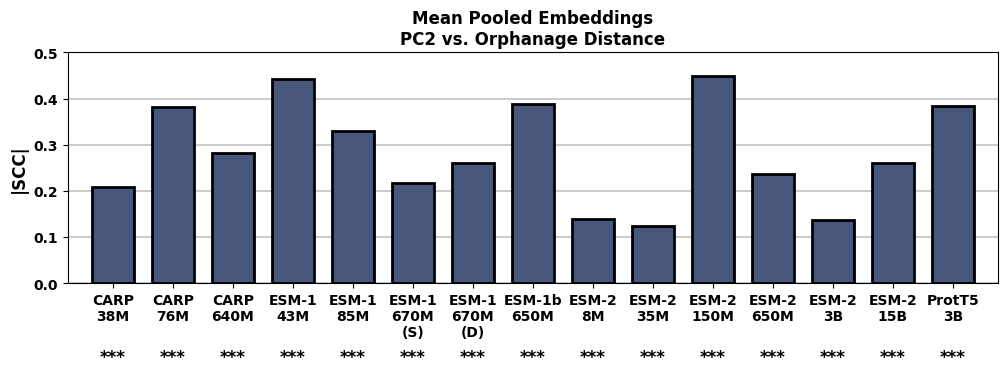

In [64]:
fig, ax = plt.subplots(figsize = (12,3))

model_order = [
    
    "carp_38M",
    "carp_76M",
    "carp_640M",
    "esm_1_43M",
    "esm_1_85M",
    "esm_1_UR50",
    "esm_1_UR50D",
    "esm_1b",
    "ESM-2 (8M)",
    "ESM-2 (35M)",
    "ESM-2 (150M)",
    "ESM-2 (650M)",
    "ESM-2 (3B)",
    "ESM-2 (15B)",
    "prott5_xl",
]


x = []
y = []

stars = []
labels = []

p_list = []

for i, m in enumerate(model_order):
    x1 = model_to_mean_pool_df[m]["PC2"].values
    x2 = model_to_mean_pool_df[m]["orphanage_distance"].values
    
    corr, p = scipy.stats.spearmanr(x1,x2)
    stars.append(p_val_to_stars(p))
    y.append(abs(corr))
    x.append(i)
    labels.append(m_to_display_c[m].replace(" ", "\n").replace("_", " "))
    p_list.append(p)
    
ax.set_xticks(x)
ax.set_xticklabels(labels, fontweight = "bold")
ax.bar(x,y,color = "#4a577d", edgecolor = "black", alpha = 1, width = 0.7, linewidth = 2, zorder = 100)
ax.set_yticks(ax.get_yticks())
ax.set_yticklabels(ax.get_yticklabels(), fontweight = "bold")
ax.set_ylabel("|SCC|", fontweight = "bold", fontsize = 12)

for y_val in ax.get_yticks():
    ax.axhline(y = y_val, color = "black", alpha = 0.2, zorder = 1)

ax.set_xlim(left = -0.75, right = len(labels) - 0.25)

for i, star_val in enumerate(stars):
    ax.text(i, -0.17, star_val, fontsize = 12, horizontalalignment = "center", fontweight = "bold")
    
ax.set_title("Mean Pooled Embeddings\nPC2 vs. Orphanage Distance", fontweight= "bold")

In [65]:
data_df = pd.DataFrame({
    "model" : list(map(lambda x : x.replace("\n", " "), labels)),
    "spearman correlation" : y,
    "spearman p-value" : p_list,
    "pool method" : "mean pooled"
})

correlation_tracker["mean_pooled_PC2_orphanage"] = data_df

data_df

,model,spearman correlation,spearman p-value,pool method
0,CARP 38M,0.207845,4.689652e-242,mean pooled
1,CARP 76M,0.383015,0.000000e+00,mean pooled
2,CARP 640M,0.281716,0.000000e+00,mean pooled
3,ESM-1 43M,0.443551,0.000000e+00,mean pooled
4,ESM-1 85M,0.329384,0.000000e+00,mean pooled
5,ESM-1 670M (S),0.217181,1.241188e-264,mean pooled
6,ESM-1 670M (D),0.260419,0.000000e+00,mean pooled
7,ESM-1b 650M,0.388317,0.000000e+00,mean pooled
8,ESM-2 8M,0.140075,9.770421e-110,mean pooled
9,ESM-2 35M,0.124850,2.117951e-87,mean pooled


Text(0.5, 1.0, 'Mean Pooled Embeddings\nPC1 vs. Homologs')

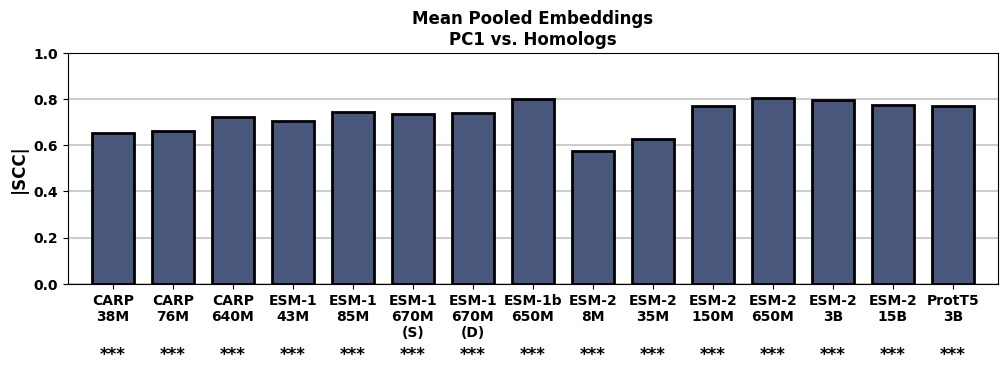

In [66]:
fig, ax = plt.subplots(figsize = (12,3))

model_order = [
    
    "carp_38M",
    "carp_76M",
    "carp_640M",
    "esm_1_43M",
    "esm_1_85M",
    "esm_1_UR50",
    "esm_1_UR50D",
    "esm_1b",
    "ESM-2 (8M)",
    "ESM-2 (35M)",
    "ESM-2 (150M)",
    "ESM-2 (650M)",
    "ESM-2 (3B)",
    "ESM-2 (15B)",
    "prott5_xl",
]


x = []
y = []

stars = []
labels = []
p_list = []

for i, m in enumerate(model_order):
    x1 = model_to_mean_pool_df[m]["PC1"].values
    x2 = model_to_mean_pool_df[m]["log_2 UR50 homologs"].values
    
    corr, p = scipy.stats.spearmanr(x1,x2)
    stars.append(p_val_to_stars(p))
    y.append(abs(corr))
    x.append(i)
    labels.append(m_to_display_c[m].replace(" ", "\n").replace("_", " "))
    p_list.append(p)
    
ax.set_xticks(x)
ax.set_xticklabels(labels, fontweight = "bold")
ax.bar(x,y,color = "#4a577d", edgecolor = "black", alpha = 1, width = 0.7, linewidth = 2, zorder = 100)
ax.set_yticks(ax.get_yticks())
ax.set_yticklabels(ax.get_yticklabels(), fontweight = "bold")
ax.set_ylabel("|SCC|", fontweight = "bold", fontsize = 12)

for y_val in ax.get_yticks():
    ax.axhline(y = y_val, color = "black", alpha = 0.2, zorder = 1)

ax.set_xlim(left = -0.75, right = len(labels) - 0.25)

for i, star_val in enumerate(stars):
    ax.text(i, -0.33, star_val, fontsize = 12, horizontalalignment = "center", fontweight = "bold")
    
ax.set_title("Mean Pooled Embeddings\nPC1 vs. Homologs", fontweight= "bold")

In [67]:
data_df = pd.DataFrame({
    "model" : list(map(lambda x : x.replace("\n", " "), labels)),
    "spearman correlation" : y,
    "spearman p-value" : p_list,
    "pool method" : "mean pooled"
})

correlation_tracker["mean_pooled_PC1_homologs"] = data_df

data_df

,model,spearman correlation,spearman p-value,pool method
0,CARP 38M,0.654177,0.0,mean pooled
1,CARP 76M,0.661356,0.0,mean pooled
2,CARP 640M,0.720671,0.0,mean pooled
3,ESM-1 43M,0.704736,0.0,mean pooled
4,ESM-1 85M,0.745156,0.0,mean pooled
5,ESM-1 670M (S),0.735019,0.0,mean pooled
6,ESM-1 670M (D),0.738948,0.0,mean pooled
7,ESM-1b 650M,0.801073,0.0,mean pooled
8,ESM-2 8M,0.573407,0.0,mean pooled
9,ESM-2 35M,0.625983,0.0,mean pooled


Text(0.5, 1.0, 'Mean Pooled Embeddings\nPC2 vs. Homologs')

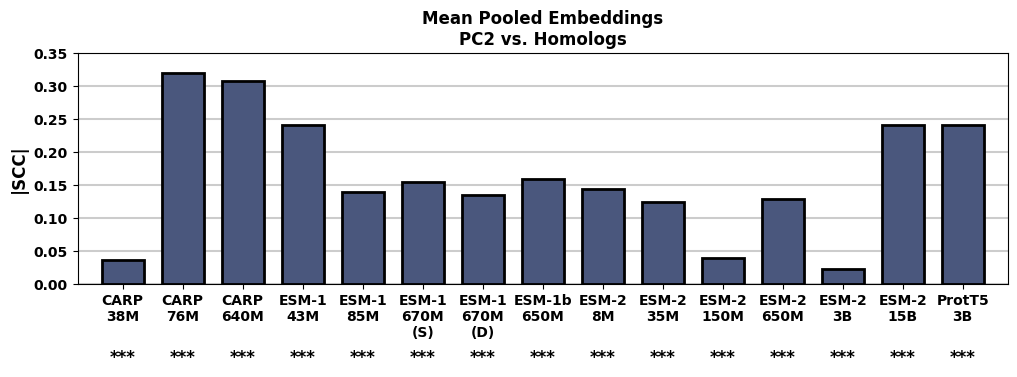

In [68]:
fig, ax = plt.subplots(figsize = (12,3))

model_order = [
    
    "carp_38M",
    "carp_76M",
    "carp_640M",
    "esm_1_43M",
    "esm_1_85M",
    "esm_1_UR50",
    "esm_1_UR50D",
    "esm_1b",
    "ESM-2 (8M)",
    "ESM-2 (35M)",
    "ESM-2 (150M)",
    "ESM-2 (650M)",
    "ESM-2 (3B)",
    "ESM-2 (15B)",
    "prott5_xl",
]


x = []
y = []

stars = []
labels = []
p_list = [] 

for i, m in enumerate(model_order):
    x1 = model_to_mean_pool_df[m]["PC2"].values
    x2 = model_to_mean_pool_df[m]["log_2 UR50 homologs"].values
    
    corr, p = scipy.stats.spearmanr(x1,x2)
    stars.append(p_val_to_stars(p))
    y.append(abs(corr))
    x.append(i)
    labels.append(m_to_display_c[m].replace(" ", "\n").replace("_", " "))
    p_list.append(p)
    
ax.set_xticks(x)
ax.set_xticklabels(labels, fontweight = "bold")
ax.bar(x,y,color = "#4a577d", edgecolor = "black", alpha = 1, width = 0.7, linewidth = 2, zorder = 100)
ax.set_yticks(ax.get_yticks())
ax.set_yticklabels(ax.get_yticklabels(), fontweight = "bold")
ax.set_ylabel("|SCC|", fontweight = "bold", fontsize = 12)

for y_val in ax.get_yticks():
    ax.axhline(y = y_val, color = "black", alpha = 0.2, zorder = 1)

ax.set_xlim(left = -0.75, right = len(labels) - 0.25)

for i, star_val in enumerate(stars):
    ax.text(i, -0.12, star_val, fontsize = 12, horizontalalignment = "center", fontweight = "bold")
    
ax.set_title("Mean Pooled Embeddings\nPC2 vs. Homologs", fontweight= "bold")

In [69]:
data_df = pd.DataFrame({
    "model" : list(map(lambda x : x.replace("\n", " "), labels)),
    "spearman correlation" : y,
    "spearman p-value" : p_list,
    "pool method" : "mean pooled"
})

correlation_tracker["mean_pooled_PC2_homologs"] = data_df

data_df

,model,spearman correlation,spearman p-value,pool method
0,CARP 38M,0.035998,1.246249e-08,mean pooled
1,CARP 76M,0.319732,0.000000e+00,mean pooled
2,CARP 640M,0.307586,0.000000e+00,mean pooled
3,ESM-1 43M,0.240778,0.000000e+00,mean pooled
4,ESM-1 85M,0.138753,1.080226e-107,mean pooled
5,ESM-1 670M (S),0.153544,1.020586e-131,mean pooled
6,ESM-1 670M (D),0.134489,3.110503e-101,mean pooled
7,ESM-1b 650M,0.158925,4.346865e-141,mean pooled
8,ESM-2 8M,0.143270,9.230295e-115,mean pooled
9,ESM-2 35M,0.124538,5.705955e-87,mean pooled


Text(0.5, 1.0, 'Mean Pooled Embeddings\nOrphanage Distance vs. Homologs')

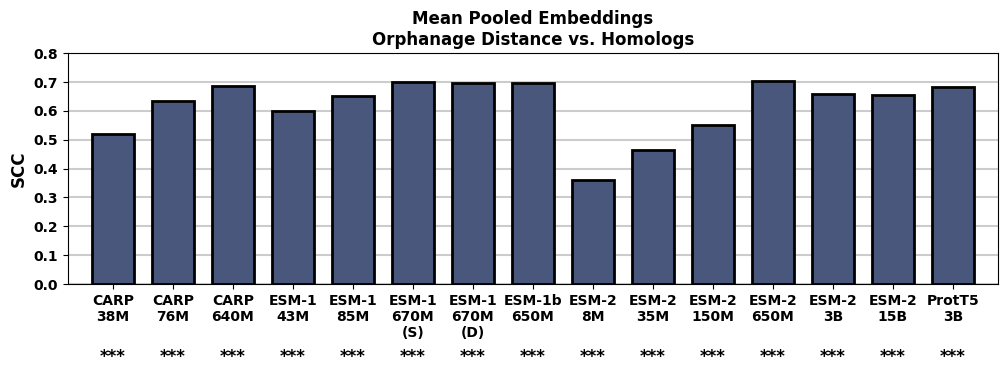

In [70]:
fig, ax = plt.subplots(figsize = (12,3))

model_order = [
    
    "carp_38M",
    "carp_76M",
    "carp_640M",
    "esm_1_43M",
    "esm_1_85M",
    "esm_1_UR50",
    "esm_1_UR50D",
    "esm_1b",
    "ESM-2 (8M)",
    "ESM-2 (35M)",
    "ESM-2 (150M)",
    "ESM-2 (650M)",
    "ESM-2 (3B)",
    "ESM-2 (15B)",
    "prott5_xl",
]


x = []
y = []

stars = []
labels = []
p_list = []

for i, m in enumerate(model_order):
    x1 = model_to_mean_pool_df[m]["orphanage_distance"].values
    x2 = model_to_mean_pool_df[m]["log_2 UR50 homologs"].values
    
    corr, p = scipy.stats.spearmanr(x1,x2)
    stars.append(p_val_to_stars(p))
    y.append(corr)
    x.append(i)
    labels.append(m_to_display_c[m].replace(" ", "\n").replace("_", " "))
    p_list.append(p)
    
    
ax.set_xticks(x)
ax.set_xticklabels(labels, fontweight = "bold")
ax.bar(x,y,color = "#4a577d", edgecolor = "black", alpha = 1, width = 0.7, linewidth = 2, zorder = 100)
ax.set_yticks(ax.get_yticks())
ax.set_yticklabels(ax.get_yticklabels(), fontweight = "bold")
ax.set_ylabel("SCC", fontweight = "bold", fontsize = 12)

for y_val in ax.get_yticks():
    ax.axhline(y = y_val, color = "black", alpha = 0.2, zorder = 1)

ax.set_xlim(left = -0.75, right = len(labels) - 0.25)

for i, star_val in enumerate(stars):
    ax.text(i, -0.27, star_val, fontsize = 12, horizontalalignment = "center", fontweight = "bold")
    
ax.set_title("Mean Pooled Embeddings\nOrphanage Distance vs. Homologs", fontweight= "bold")

In [71]:
data_df = pd.DataFrame({
    "model" : list(map(lambda x : x.replace("\n", " "), labels)),
    "spearman correlation" : y,
    "spearman p-value" : p_list,
    "pool method" : "mean pooled"
})

correlation_tracker["mean_pooled_orphanage_homologs"] = data_df

data_df

,model,spearman correlation,spearman p-value,pool method
0,CARP 38M,0.520314,0.0,mean pooled
1,CARP 76M,0.634992,0.0,mean pooled
2,CARP 640M,0.686189,0.0,mean pooled
3,ESM-1 43M,0.599108,0.0,mean pooled
4,ESM-1 85M,0.650622,0.0,mean pooled
5,ESM-1 670M (S),0.698257,0.0,mean pooled
6,ESM-1 670M (D),0.696565,0.0,mean pooled
7,ESM-1b 650M,0.694956,0.0,mean pooled
8,ESM-2 8M,0.361271,0.0,mean pooled
9,ESM-2 35M,0.464088,0.0,mean pooled


Text(0.5, 1.0, 'Mean Pooled Embeddings\nPC1 vs. Orphanage Distance')

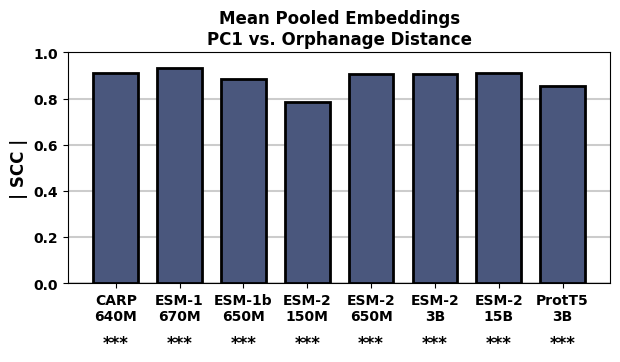

In [72]:

### for the main text 

fig, ax = plt.subplots(figsize = (7,3))

model_order = [
    
#     "carp_38M",
#     "carp_76M",
    "carp_640M",
#     "esm_1_43M",
#     "esm_1_85M",
#     "esm_1_UR50",
    "esm_1_UR50D",
    "esm_1b",
#     "ESM-2 (8M)",
#     "ESM-2 (35M)",
    "ESM-2 (150M)",
    "ESM-2 (650M)",
    "ESM-2 (3B)",
    "ESM-2 (15B)",
    "prott5_xl",
]


x = []
y = []

stars = []
labels = []

p_list = []

for i, m in enumerate(model_order):
    x1 = model_to_mean_pool_df[m]["PC1"].values
    x2 = model_to_mean_pool_df[m]["orphanage_distance"].values
    
    corr, p = scipy.stats.spearmanr(x1,x2)
    stars.append(p_val_to_stars(p))
    y.append(abs(corr))
    x.append(i)
    labels.append(m_to_display_c[m].replace(" ", "\n").replace("_", " ").replace("(D)", ""))
    p_list.append(p)
    
ax.set_xticks(x)
ax.set_xticklabels(labels, fontweight = "bold")
ax.bar(x,y,color = "#4a577d", edgecolor = "black", alpha = 1, width = 0.7, linewidth = 2, zorder = 100)
ax.set_yticks(ax.get_yticks())
ax.set_yticklabels(ax.get_yticklabels(), fontweight = "bold")
ax.set_ylabel("| SCC |", fontweight = "bold", fontsize = 12)

for y_val in ax.get_yticks():
    ax.axhline(y = y_val, color = "black", alpha = 0.2, zorder = 1)

ax.set_xlim(left = -0.75, right = len(labels) - 0.25)

for i, star_val in enumerate(stars):
    ax.text(i, -0.28, star_val, fontsize = 12, horizontalalignment = "center", fontweight = "bold")
    
ax.set_title("Mean Pooled Embeddings\nPC1 vs. Orphanage Distance", fontweight= "bold")


In [73]:
data_df = pd.DataFrame({
    "model" : list(map(lambda x : x.replace("\n", " "), labels)),
    "spearman correlation" : y,
    "spearman p-value" : p_list,
    "pool method" : "mean pooled"
})

data_df.to_csv(f"{llm_review_path}source_data_csvs/fig_6/data_6j.csv", index = False)




### CLS Pooling



In [74]:

model_to_cls_pool_df = {}


wanted_model_list = [

    "esm_1_43M",
    "esm_1_85M",
    "esm_1_UR50",
    "esm_1_UR50D",
    "esm_1b",
]

dfh = pd.read_csv(supp_table_path + "orphanage_pcs_homologs_seqeunces_all_models_all_pooling.csv")
#can be any model/embedding type 
selected_group = dfh.loc[(dfh["model"] == "ESM-2 (150M)") & (dfh["embedding_type"] == "mean_pooled")]
ident_to_homologs = dict(zip(selected_group["name"].values,  selected_group["log_2 UR50 homologs"].values))

wanted_pool_method = "cls_pooled"


for wanted_model in wanted_model_list:
    
    # making names consistent
    keeping_cols = []
    # can be any model / pool method
    dist_df_original = pd.read_csv(f"../../../Orphan25/random_UR50_protein_embedding_experiment/all_distance_results/esm_2_150M__CLS.csv",index_col = 0)
    for k in list(dist_df_original.columns):
        keeping_cols.append(k.replace("Orphan25_", "").replace("randseq_", ""))

    df = pd.read_csv(f"../../../revisions/scripts/orphanage/results/{wanted_model}_{wanted_pool_method}.csv", index_col = 0)
    df = df[keeping_cols]

    ident_to_mean_dist = {}

    for index, row in df.iterrows():
        m1 = np.mean(row.values)
        ident_to_mean_dist[index] = m1

    df["orphanage_distance"] = ident_to_mean_dist


    with open(f"../../../revisions/data/orphanage/orphanage_extractions/{wanted_model}/UR50_sample_sequences.pkl", "rb") as f1:
        data = pickle.load(f1)
    f1.close()


    X = []
    identifiers = []

    for k, v in data.items():
        X.append(v[wanted_pool_method])
        identifiers.append(k)


    X = np.asarray(X)

    pca = PCA(n_components=2)  # Specify the number of components
    pca.fit(X)
    embedding = pca.transform(X)


    PC_1 = embedding[:, 0]
    PC_2 = embedding[:, 1]

    PC_1_dict = dict(zip(identifiers, PC_1))
    PC_2_dict = dict(zip(identifiers, PC_2))

    df["PC1"] = PC_1_dict
    df["PC2"] = PC_2_dict
    df["log_2 UR50 homologs"] = ident_to_homologs

    print(wanted_model)

    model_to_cls_pool_df[wanted_model] = copy.deepcopy(df)
    
dfh = pd.read_csv(supp_table_path + "orphanage_pcs_homologs_seqeunces_all_models_all_pooling.csv")

for m, sub_df in dfh.groupby("model"):
    sub_df = sub_df.loc[sub_df["embedding_type"] == "CLS"]
    model_to_cls_pool_df[m] = copy.deepcopy(sub_df)
    
    

esm_1_43M
esm_1_85M
esm_1_UR50
esm_1_UR50D
esm_1b


Text(0.5, 1.0, 'CLS Pooled Embeddings\nPC1 vs. Orphanage Distance')

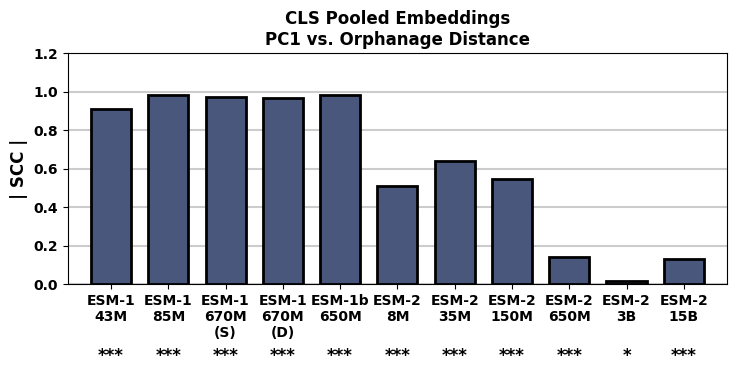

In [75]:

### for the main text 

fig, ax = plt.subplots(figsize = (8.5,3))

model_order = [

    "esm_1_43M",
    "esm_1_85M",
    "esm_1_UR50",
    "esm_1_UR50D",
    "esm_1b",
    "ESM-2 (8M)",
    "ESM-2 (35M)",
    "ESM-2 (150M)",
    "ESM-2 (650M)",
    "ESM-2 (3B)",
    "ESM-2 (15B)",
]


x = []
y = []

stars = []
labels = []

p_list = []

for i, m in enumerate(model_order):
    x1 = model_to_cls_pool_df[m]["PC1"].values
    x2 = model_to_cls_pool_df[m]["orphanage_distance"].values
    
    corr, p = scipy.stats.spearmanr(x1,x2)
    stars.append(p_val_to_stars(p))
    y.append(abs(corr))
    x.append(i)
    labels.append(m_to_display_c[m].replace(" ", "\n").replace("_", " "))
    p_list.append(p)
    
    
ax.set_xticks(x)
ax.set_xticklabels(labels, fontweight = "bold")
ax.bar(x,y,color = "#4a577d", edgecolor = "black", alpha = 1, width = 0.7, linewidth = 2, zorder = 100)
ax.set_yticks(ax.get_yticks())
ax.set_yticklabels(ax.get_yticklabels(), fontweight = "bold")
ax.set_ylabel("| SCC |", fontweight = "bold", fontsize = 12)

for y_val in ax.get_yticks():
    ax.axhline(y = y_val, color = "black", alpha = 0.2, zorder = 1)

ax.set_xlim(left = -0.75, right = len(labels) - 0.25)

for i, star_val in enumerate(stars):
    ax.text(i, -0.4, star_val, fontsize = 12, horizontalalignment = "center", fontweight = "bold")
    
ax.set_title("CLS Pooled Embeddings\nPC1 vs. Orphanage Distance", fontweight= "bold")


In [76]:
data_df = pd.DataFrame({
    "model" : list(map(lambda x : x.replace("\n", " "), labels)),
    "spearman correlation" : y,
    "spearman p-value" : p_list,
    "pool method" : "cls pooled"
})

correlation_tracker["cls_pooled_PC1_orphanage"] = data_df

data_df

,model,spearman correlation,spearman p-value,pool method
0,ESM-1 43M,0.907234,0.000000e+00,cls pooled
1,ESM-1 85M,0.980244,0.000000e+00,cls pooled
2,ESM-1 670M (S),0.971752,0.000000e+00,cls pooled
3,ESM-1 670M (D),0.964719,0.000000e+00,cls pooled
4,ESM-1b 650M,0.984013,0.000000e+00,cls pooled
5,ESM-2 8M,0.508867,0.000000e+00,cls pooled
6,ESM-2 35M,0.639604,0.000000e+00,cls pooled
7,ESM-2 150M,0.547847,0.000000e+00,cls pooled
8,ESM-2 650M,0.141551,4.824414e-112,cls pooled
9,ESM-2 3B,0.015792,1.252624e-02,cls pooled


Text(0.5, 1.0, 'CLS Pooled Embeddings\nPC2 vs. Orphanage Distance')

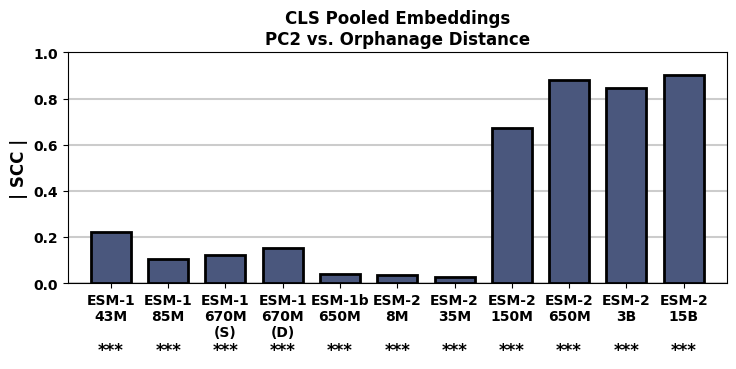

In [77]:

### for the main text 

fig, ax = plt.subplots(figsize = (8.5,3))

model_order = [

    "esm_1_43M",
    "esm_1_85M",
    "esm_1_UR50",
    "esm_1_UR50D",
    "esm_1b",
    "ESM-2 (8M)",
    "ESM-2 (35M)",
    "ESM-2 (150M)",
    "ESM-2 (650M)",
    "ESM-2 (3B)",
    "ESM-2 (15B)",
]


x = []
y = []

stars = []
labels = []
p_list = []

for i, m in enumerate(model_order):
    x1 = model_to_cls_pool_df[m]["PC2"].values
    x2 = model_to_cls_pool_df[m]["orphanage_distance"].values
    
    corr, p = scipy.stats.spearmanr(x1,x2)
    stars.append(p_val_to_stars(p))
    y.append(abs(corr))
    x.append(i)
    labels.append(m_to_display_c[m].replace(" ", "\n").replace("_", " "))
    p_list.append(p)
    
    
    
ax.set_xticks(x)
ax.set_xticklabels(labels, fontweight = "bold")
ax.bar(x,y,color = "#4a577d", edgecolor = "black", alpha = 1, width = 0.7, linewidth = 2, zorder = 100)
ax.set_yticks(ax.get_yticks())
ax.set_yticklabels(ax.get_yticklabels(), fontweight = "bold")
ax.set_ylabel("| SCC |", fontweight = "bold", fontsize = 12)

for y_val in ax.get_yticks():
    ax.axhline(y = y_val, color = "black", alpha = 0.2, zorder = 1)

ax.set_xlim(left = -0.75, right = len(labels) - 0.25)

for i, star_val in enumerate(stars):
    ax.text(i, -0.31, star_val, fontsize = 12, horizontalalignment = "center", fontweight = "bold")
    
ax.set_title("CLS Pooled Embeddings\nPC2 vs. Orphanage Distance", fontweight= "bold")


In [78]:
data_df = pd.DataFrame({
    "model" : list(map(lambda x : x.replace("\n", " "), labels)),
    "spearman correlation" : y,
    "spearman p-value" : p_list,
    "pool method" : "cls pooled"
})

correlation_tracker["cls_pooled_PC2_orphanage"] = data_df

data_df

,model,spearman correlation,spearman p-value,pool method
0,ESM-1 43M,0.222233,2.637159e-277,cls pooled
1,ESM-1 85M,0.107415,4.733759e-65,cls pooled
2,ESM-1 670M (S),0.123667,8.932810e-86,cls pooled
3,ESM-1 670M (D),0.153489,1.264078e-131,cls pooled
4,ESM-1b 650M,0.040290,1.857662e-10,cls pooled
5,ESM-2 8M,0.034468,5.001933e-08,cls pooled
6,ESM-2 35M,0.028631,5.964090e-06,cls pooled
7,ESM-2 150M,0.671503,0.000000e+00,cls pooled
8,ESM-2 650M,0.879420,0.000000e+00,cls pooled
9,ESM-2 3B,0.844994,0.000000e+00,cls pooled


Text(0.5, 1.0, 'CLS Pooled Embeddings\nPC1 vs. Homologs')

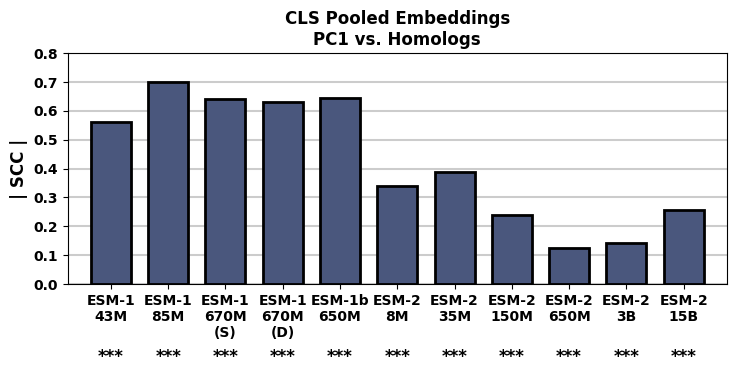

In [79]:

### for the main text 

fig, ax = plt.subplots(figsize = (8.5,3))

model_order = [

    "esm_1_43M",
    "esm_1_85M",
    "esm_1_UR50",
    "esm_1_UR50D",
    "esm_1b",
    "ESM-2 (8M)",
    "ESM-2 (35M)",
    "ESM-2 (150M)",
    "ESM-2 (650M)",
    "ESM-2 (3B)",
    "ESM-2 (15B)",
]


x = []
y = []

stars = []
labels = []

p_list = []

for i, m in enumerate(model_order):
    x1 = model_to_cls_pool_df[m]["PC1"].values
    x2 = model_to_cls_pool_df[m]["log_2 UR50 homologs"].values
    
    corr, p = scipy.stats.spearmanr(x1,x2)
    stars.append(p_val_to_stars(p))
    y.append(abs(corr))
    x.append(i)
    labels.append(m_to_display_c[m].replace(" ", "\n").replace("_", " "))
    p_list.append(p)
    
ax.set_xticks(x)
ax.set_xticklabels(labels, fontweight = "bold")
ax.bar(x,y,color = "#4a577d", edgecolor = "black", alpha = 1, width = 0.7, linewidth = 2, zorder = 100)
ax.set_yticks(ax.get_yticks())
ax.set_yticklabels(ax.get_yticklabels(), fontweight = "bold")
ax.set_ylabel("| SCC |", fontweight = "bold", fontsize = 12)

for y_val in ax.get_yticks():
    ax.axhline(y = y_val, color = "black", alpha = 0.2, zorder = 1)

ax.set_xlim(left = -0.75, right = len(labels) - 0.25)

for i, star_val in enumerate(stars):
    ax.text(i, -0.27, star_val, fontsize = 12, horizontalalignment = "center", fontweight = "bold")
    
ax.set_title("CLS Pooled Embeddings\nPC1 vs. Homologs", fontweight= "bold")


In [80]:
data_df = pd.DataFrame({
    "model" : list(map(lambda x : x.replace("\n", " "), labels)),
    "spearman correlation" : y,
    "spearman p-value" : p_list,
    "pool method" : "cls pooled"
})

correlation_tracker["cls_pooled_PC1_homologs"] = data_df

data_df

,model,spearman correlation,spearman p-value,pool method
0,ESM-1 43M,0.562310,0.000000e+00,cls pooled
1,ESM-1 85M,0.698358,0.000000e+00,cls pooled
2,ESM-1 670M (S),0.640705,0.000000e+00,cls pooled
3,ESM-1 670M (D),0.631062,0.000000e+00,cls pooled
4,ESM-1b 650M,0.643601,0.000000e+00,cls pooled
5,ESM-2 8M,0.338239,0.000000e+00,cls pooled
6,ESM-2 35M,0.389567,0.000000e+00,cls pooled
7,ESM-2 150M,0.238071,0.000000e+00,cls pooled
8,ESM-2 650M,0.124847,2.138475e-87,cls pooled
9,ESM-2 3B,0.141484,6.131613e-112,cls pooled


Text(0.5, 1.0, 'CLS Pooled Embeddings\nPC2 vs. Homologs')

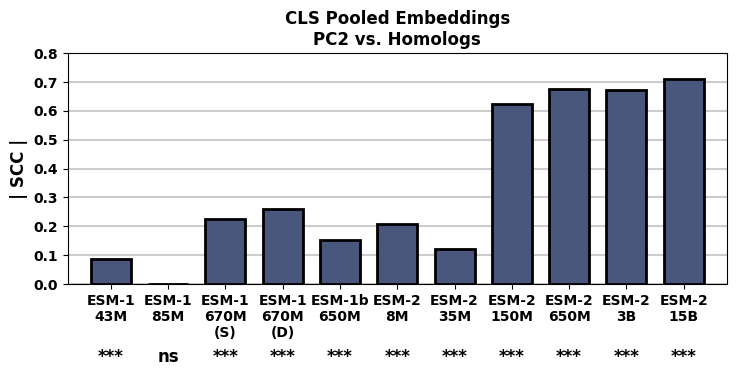

In [81]:


fig, ax = plt.subplots(figsize = (8.5,3))

model_order = [

    "esm_1_43M",
    "esm_1_85M",
    "esm_1_UR50",
    "esm_1_UR50D",
    "esm_1b",
    "ESM-2 (8M)",
    "ESM-2 (35M)",
    "ESM-2 (150M)",
    "ESM-2 (650M)",
    "ESM-2 (3B)",
    "ESM-2 (15B)",
]


x = []
y = []

stars = []
labels = []

p_list = []

for i, m in enumerate(model_order):
    x1 = model_to_cls_pool_df[m]["PC2"].values
    x2 = model_to_cls_pool_df[m]["log_2 UR50 homologs"].values
    
    corr, p = scipy.stats.spearmanr(x1,x2)
    stars.append(p_val_to_stars(p))
    y.append(abs(corr))
    x.append(i)
    labels.append(m_to_display_c[m].replace(" ", "\n").replace("_", " "))
    p_list.append(p)
    
ax.set_xticks(x)
ax.set_xticklabels(labels, fontweight = "bold")
ax.bar(x,y,color = "#4a577d", edgecolor = "black", alpha = 1, width = 0.7, linewidth = 2, zorder = 100)
ax.set_yticks(ax.get_yticks())
ax.set_yticklabels(ax.get_yticklabels(), fontweight = "bold")
ax.set_ylabel("| SCC |", fontweight = "bold", fontsize = 12)

for y_val in ax.get_yticks():
    ax.axhline(y = y_val, color = "black", alpha = 0.2, zorder = 1)

ax.set_xlim(left = -0.75, right = len(labels) - 0.25)

for i, star_val in enumerate(stars):
    ax.text(i, -0.27, star_val, fontsize = 12, horizontalalignment = "center", fontweight = "bold")
    
ax.set_title("CLS Pooled Embeddings\nPC2 vs. Homologs", fontweight= "bold")


In [82]:
data_df = pd.DataFrame({
    "model" : list(map(lambda x : x.replace("\n", " "), labels)),
    "spearman correlation" : y,
    "spearman p-value" : p_list,
    "pool method" : "cls pooled"
})

correlation_tracker["cls_pooled_PC2_homologs"] = data_df

data_df

,model,spearman correlation,spearman p-value,pool method
0,ESM-1 43M,0.086120,2.269354e-42,cls pooled
1,ESM-1 85M,0.001636,7.959101e-01,cls pooled
2,ESM-1 670M (S),0.224137,3.650064e-282,cls pooled
3,ESM-1 670M (D),0.258687,0.000000e+00,cls pooled
4,ESM-1b 650M,0.152112,2.786397e-129,cls pooled
5,ESM-2 8M,0.207594,1.834471e-241,cls pooled
6,ESM-2 35M,0.123047,6.251000e-85,cls pooled
7,ESM-2 150M,0.623115,0.000000e+00,cls pooled
8,ESM-2 650M,0.674726,0.000000e+00,cls pooled
9,ESM-2 3B,0.671941,0.000000e+00,cls pooled


Text(0.5, 1.0, 'CLS Pooled Embeddings\nOrphanage Distance vs. Homologs')

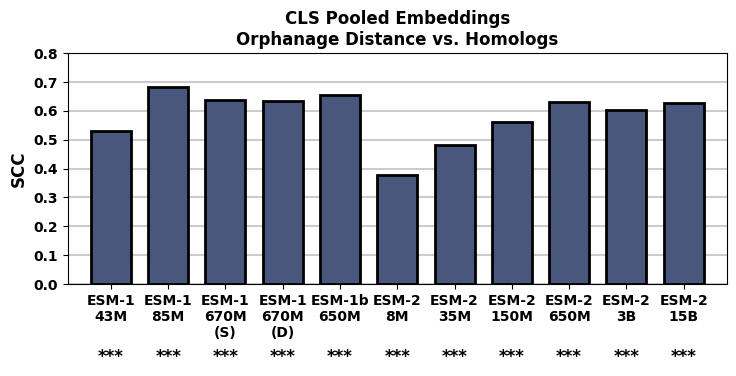

In [83]:

### for the main text 

fig, ax = plt.subplots(figsize = (8.5,3))

model_order = [

    "esm_1_43M",
    "esm_1_85M",
    "esm_1_UR50",
    "esm_1_UR50D",
    "esm_1b",
    "ESM-2 (8M)",
    "ESM-2 (35M)",
    "ESM-2 (150M)",
    "ESM-2 (650M)",
    "ESM-2 (3B)",
    "ESM-2 (15B)",
]


x = []
y = []

stars = []
labels = []

for i, m in enumerate(model_order):
    x1 = model_to_cls_pool_df[m]["orphanage_distance"].values
    x2 = model_to_cls_pool_df[m]["log_2 UR50 homologs"].values
    
    corr, p = scipy.stats.spearmanr(x1,x2)
    stars.append(p_val_to_stars(p))
    y.append(corr)
    x.append(i)
    labels.append(m_to_display_c[m].replace(" ", "\n").replace("_", " "))
    
ax.set_xticks(x)
ax.set_xticklabels(labels, fontweight = "bold")
ax.bar(x,y,color = "#4a577d", edgecolor = "black", alpha = 1, width = 0.7, linewidth = 2, zorder = 100)
ax.set_yticks(ax.get_yticks())
ax.set_yticklabels(ax.get_yticklabels(), fontweight = "bold")
ax.set_ylabel("SCC", fontweight = "bold", fontsize = 12)

for y_val in ax.get_yticks():
    ax.axhline(y = y_val, color = "black", alpha = 0.2, zorder = 1)

ax.set_xlim(left = -0.75, right = len(labels) - 0.25)

for i, star_val in enumerate(stars):
    ax.text(i, -0.27, star_val, fontsize = 12, horizontalalignment = "center", fontweight = "bold")
    
ax.set_title("CLS Pooled Embeddings\nOrphanage Distance vs. Homologs", fontweight= "bold")


In [84]:
data_df = pd.DataFrame({
    "model" : list(map(lambda x : x.replace("\n", " "), labels)),
    "spearman correlation" : y,
    "spearman p-value" : p_list,
    "pool method" : "cls pooled"
})

correlation_tracker["cls_pooled_orphanage_homologs"] = data_df

data_df

,model,spearman correlation,spearman p-value,pool method
0,ESM-1 43M,0.530379,2.269354e-42,cls pooled
1,ESM-1 85M,0.682132,7.959101e-01,cls pooled
2,ESM-1 670M (S),0.638652,3.650064e-282,cls pooled
3,ESM-1 670M (D),0.634197,0.000000e+00,cls pooled
4,ESM-1b 650M,0.654293,2.786397e-129,cls pooled
5,ESM-2 8M,0.376595,1.834471e-241,cls pooled
6,ESM-2 35M,0.482056,6.251000e-85,cls pooled
7,ESM-2 150M,0.559744,0.000000e+00,cls pooled
8,ESM-2 650M,0.628925,0.000000e+00,cls pooled
9,ESM-2 3B,0.603029,0.000000e+00,cls pooled


In [85]:
## making tables 

model_to_display_d = {
       
    "carp_38M" : "CARP (38M)",
    "carp_76M":"CARP (76M)",
    "carp_640M":"CARP (640M)",
    "esm_1_43M":"ESM-1 (43M)",
    "esm_1_85M":"ESM-1 (85M)",
    "esm_1_UR50":"ESM-1 (670M) UR50S",
    "esm_1_UR50D":"ESM-1 (670M) UR50D",
    "esm_1b":"ESM-1b (650M)",
    "prott5_xl" : "ProtT5 (3B)",
}

mean_pooled_pieces = []

df_spine = copy.deepcopy(model_to_mean_pool_df["ESM-2 (8M)"])
df_spine = df_spine.set_index("name").drop(columns = ["Unnamed: 0", "model", "PC1", "PC2", "orphanage_distance"])


for model, model_df in model_to_mean_pool_df.items():
    dfo = copy.deepcopy(df_spine)

    if "ESM-2" in model:
        model_df = model_df.set_index("name")
        dfo["PC1"] = model_df["PC1"].to_dict()
        dfo["PC2"] = model_df["PC2"].to_dict()
        dfo["orphanage_distance"] = model_df["orphanage_distance"].to_dict()
        dfo["model"] = model
        dfo["embedding_type"] = "mean_pooled"
        dfo["identifier"] = copy.deepcopy(dfo.index.values)
        mean_pooled_pieces.append(dfo)
        
    else:
        
        dfo["PC1"] = model_df["PC1"].to_dict()
        dfo["PC2"] = model_df["PC2"].to_dict()
        dfo["orphanage_distance"] = model_df["orphanage_distance"].to_dict()
        dfo["model"] = model_to_display_d[model]
        dfo["embedding_type"] = "mean_pooled"
        dfo["identifier"] = copy.deepcopy(dfo.index.values)    
        mean_pooled_pieces.append(dfo)
    

df_mean_pooled = pd.concat(mean_pooled_pieces)



cls_pooled_pieces = []

for model, model_df in model_to_cls_pool_df.items():
    dfo = copy.deepcopy(df_spine)

    if "ESM-2" in model:
        model_df = model_df.set_index("name")
        dfo["PC1"] = model_df["PC1"].to_dict()
        dfo["PC2"] = model_df["PC2"].to_dict()
        dfo["orphanage_distance"] = model_df["orphanage_distance"].to_dict()
        dfo["model"] = model
        dfo["embedding_type"] = "cls_pooled"
        dfo["identifier"] = copy.deepcopy(dfo.index.values)
        cls_pooled_pieces.append(dfo)
        
    else:
        
        dfo["PC1"] = model_df["PC1"].to_dict()
        dfo["PC2"] = model_df["PC2"].to_dict()
        dfo["orphanage_distance"] = model_df["orphanage_distance"].to_dict()
        dfo["model"] = model_to_display_d[model]
        dfo["embedding_type"] = "cls_pooled"
        dfo["identifier"] = copy.deepcopy(dfo.index.values)    
        cls_pooled_pieces.append(dfo)
   

df_cls_pooled = pd.concat(cls_pooled_pieces)

print(len(df_cls_pooled), len(df_mean_pooled))
joint_df = pd.concat([df_mean_pooled, df_cls_pooled])
joint_df.to_csv(supp_table_path + "revisions/all_pool_methods_all_models_PCS_and_orphanage_info.csv", index = False)


275000 375000


In [86]:

out_df_mean = correlation_tracker["mean_pooled_orphanage_homologs"] 
out_df_cls = correlation_tracker["cls_pooled_orphanage_homologs"] 

data_df_E9a = pd.concat([out_df_mean, out_df_cls])
data_df_E9a.to_csv(data_output_path + "fig_E9/data_E9a.csv", index = False)

out_df_mean = correlation_tracker["mean_pooled_PC1_orphanage"] 
out_df_cls = correlation_tracker["cls_pooled_PC1_orphanage"] 

data_df_E9b = pd.concat([out_df_mean, out_df_cls])
data_df_E9b.to_csv(data_output_path + "fig_E9/data_E9b.csv", index = False)


out_df_mean = correlation_tracker["mean_pooled_PC2_orphanage"] 
out_df_cls = correlation_tracker["cls_pooled_PC2_orphanage"] 

data_df_E9c = pd.concat([out_df_mean, out_df_cls])
data_df_E9c.to_csv(data_output_path + "fig_E9/data_E9c.csv", index = False)


out_df_mean = correlation_tracker["mean_pooled_PC1_homologs"] 
out_df_cls = correlation_tracker["cls_pooled_PC1_homologs"] 

data_df_E9d = pd.concat([out_df_mean, out_df_cls])
data_df_E9d.to_csv(data_output_path + "fig_E9/data_E9d.csv", index = False)

out_df_mean = correlation_tracker["mean_pooled_PC2_homologs"] 
out_df_cls = correlation_tracker["cls_pooled_PC2_homologs"] 

data_df_E9e = pd.concat([out_df_mean, out_df_cls])
data_df_E9e.to_csv(data_output_path + "fig_E9/data_E9e.csv", index = False)

In [88]:
pd.read_csv(supp_table_path + "orphan_25_human_pair_distances.csv")

,Unnamed: 0,category,protein1,protein2,similarity method,distance,model
0,0,Orphan25,7AL0_A,7AD7_C,Mean Pool,0.7531801,ESM-2 (8M)
1,1,Orphan25,7AL0_A,7COY_bI,Mean Pool,0.79590005,ESM-2 (8M)
2,2,Orphan25,7AL0_A,7N50_A,Mean Pool,0.82216763,ESM-2 (8M)
3,3,Orphan25,7AL0_A,6XYH_A,Mean Pool,0.8184851,ESM-2 (8M)
4,4,Orphan25,7AL0_A,7JJV_B,Mean Pool,0.6863304,ESM-2 (8M)
...,...,...,...,...,...,...,...
10795,10795,Human Selections,P02795,P26678,Column Wise Dists,0.24408|0.12674|0.13565|0.10231|0.0914|0.0948|...,ESM-2 (15B)
10796,10796,Human Selections,P02795,P56381,Column Wise Dists,0.33056|0.23679|0.19148|0.16778|0.22627|0.1856...,ESM-2 (15B)
10797,10797,Human Selections,P47944,P26678,Column Wise Dists,0.29224|0.20393|0.20037|0.15504|0.15943|0.1429...,ESM-2 (15B)
10798,10798,Human Selections,P47944,P56381,Column Wise Dists,0.33569|0.24927|0.19059|0.19456|0.15266|0.1742...,ESM-2 (15B)


In [89]:
old_variance_df = pd.read_csv(supp_table_path + "model_joined_protein_embedding_dimension_variance.csv")


supp_table_path

old_variance_df

data_path =  "../../../revisions/data/orphanage/orphanage_extractions/"

seq_df = pd.read_csv(supp_table_path + "embedding_space_used_seqeunces.csv")
id_to_seq = dict(zip(seq_df["entry"].values, seq_df["sequence"].values, ))


model_to_variance_tracker = {}



for wanted_model in model_to_display_d.keys():
    with open(data_path + wanted_model  + "/selected_full_seqs_all_groups.pkl", "rb") as f1:
        data = pickle.load(f1)
    f1.close()
    
    human_selections = data["human_selections"]
    
    
    human_selection_list = []
    
    for k, emb_ in human_selections.items():
        seq = id_to_seq[k]
        
        human_selection_list.append(emb_)
       
    
    human_embeddings_joined = np.concatenate(human_selection_list, axis = 0)
    
    
    orhpan25_selections = data["orphan_25"]
    
    
    orhpan25_selection_list = []
    
    for k, emb_ in orhpan25_selections.items():
        seq = id_to_seq[k]
        
        orhpan25_selection_list.append(emb_)
       
    
    orphan25_joined = np.concatenate(orhpan25_selection_list, axis = 0)
        
        
    variance_tracker = []
    
    for i in range(np.shape(orphan25_joined)[1]):

        x_human = human_embeddings_joined[:, i]
        x_orphan = orphan25_joined[:, i]
        
        variance_tracker.append([i, np.var(x_orphan), np.var(x_human),])
        
    model_to_variance_tracker[wanted_model] = variance_tracker
    

In [90]:
m_list = []
bar_size = []

for m in model_to_display_d.keys():
    df_var = pd.DataFrame(model_to_variance_tracker[m], columns = ["pos", "orphan25", "human"])
    df_var["human_greater"] = df_var["human"] >  df_var["orphan25"]
    
    proportion_higher = np.sum(df_var["human_greater"] ) / len(df_var)
    m_list.append(m)
    
    bar_size.append([proportion_higher, 1-proportion_higher])
    

old_variance_df = pd.read_csv(supp_table_path + "model_joined_protein_embedding_dimension_variance.csv")

old_variance_df_low =  old_variance_df.loc[old_variance_df["group"] == "Orphan25"]
old_variance_df_high =  old_variance_df.loc[old_variance_df["group"] == "Human Selections"]


for model, sub_df_high in old_variance_df_high.groupby("model"):
    sub_df_low = old_variance_df_low.loc[old_variance_df_low["model"] == model]

    pos_to_variance_low = dict(zip(sub_df_low["dimension"].values, sub_df_low["joined_embeddings_dimensional_varaince"].values))
    higher_tracker = 0
    total_tracker = len(sub_df_low)
    
    for index, row in sub_df_high.iterrows():
        dim = row["dimension"]
        val_high = row["joined_embeddings_dimensional_varaince"]   
        val_low = pos_to_variance_low[dim] 
        
        if val_high > val_low:
            higher_tracker += 1
            
    n_greater = higher_tracker / total_tracker
    bar_size.append([n_greater, 1 - n_greater])
    m_list.append(model)


[Text(0, 0, 'CARP\n38M'),
 Text(1, 0, 'CARP\n76M'),
 Text(2, 0, 'CARP\n640M'),
 Text(3, 0, 'ESM-1\n43M'),
 Text(4, 0, 'ESM-1\n85M'),
 Text(5, 0, 'ESM-1\n670M\n(S)'),
 Text(6, 0, 'ESM-1\n670M\n(D)'),
 Text(7, 0, 'ESM-1b\n650M'),
 Text(8, 0, 'ProtT5\n3B'),
 Text(9, 0, 'ESM-2\n(150M)'),
 Text(10, 0, 'ESM-2\n(15B)'),
 Text(11, 0, 'ESM-2\n(35M)'),
 Text(12, 0, 'ESM-2\n(3B)'),
 Text(13, 0, 'ESM-2\n(650M)'),
 Text(14, 0, 'ESM-2\n(8M)')]

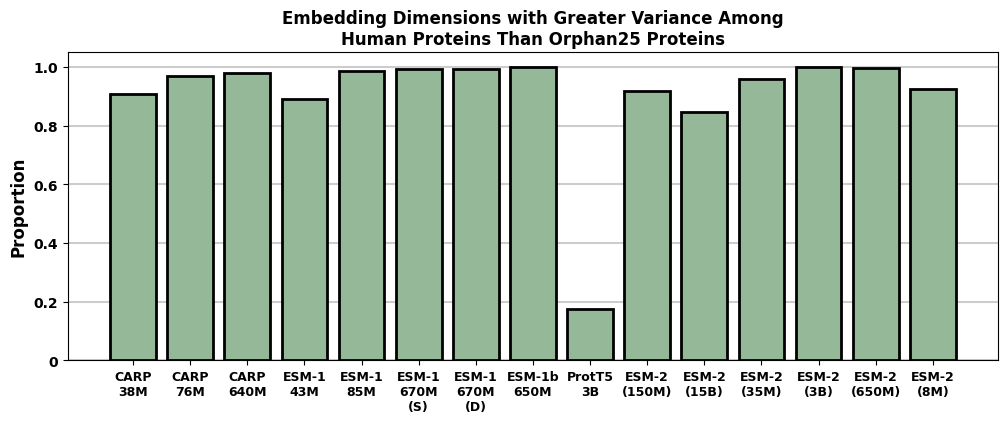

In [91]:
x = np.array(bar_size)

fig, ax = plt.subplots(figsize=(12,4))

ind = np.arange(len(x))
bottom = np.zeros(len(x))


below_color = "#8aa9e3"
above_color = "#95b899"

colors = ["#8aa9e3", "95b899"]


ax.bar(
    ind,
    x[:, 0],
    bottom=bottom,
    label=f"Group {i+1}",
    color=above_color,
    zorder = 100,
    linewidth = 2,
    edgecolor = "black"
)


ax.set_ylim(0, 1)
ax.set_title("Embedding Dimensions with Greater Variance Among\nHuman Proteins Than Orphan25 Proteins", fontweight = "bold")

ax.set_ylabel("Proportion", fontweight = "bold", fontsize = 12)
ax.set_yticks([0, 0.2,0.4,0.6,0.8,1.0] )
ax.set_yticklabels([0, 0.2,0.4,0.6,0.8,1.0], fontweight = "bold", fontsize = 10 )
ax.set_ylim(top = 1.05)

x_ticklabels = list(map(lambda x : m_to_display_c[x].replace(" ", "\n") if "ESM" not in x else x.replace(" ", "\n"),  m_list))

for y_val in ax.get_yticks():
    ax.axhline(y = y_val, zorder = 1, color = "black", alpha = 0.2)
    
ax.set_xticks(ind)
ax.set_xticklabels(x_ticklabels, fontweight = "bold", fontsize = 9 )



In [92]:
data_out_df = pd.DataFrame({
    "model" : list(map(lambda x : x.replace("\n", " "), x_ticklabels)),
    "bar_height" : x[:, 0]
})

data_out_df.to_csv(data_output_path + "fig_S8/data_S8d.csv", index = False)

In [93]:
homstrad_path = home_path + "singh/nlp_review/remote_homology/"

df = pd.read_csv(homstrad_path + "all_romote_homologs_seqeunces.csv")



homolog_results = pd.read_csv(
    homstrad_path + "./high_quality_homolog_counts/SCOPe_proteins_UR50_hits_pct_identity_0.0_gap_pct_0.75_aln_frac_0.75.csv",
    index_col = 0
)


model_to_variance_tracker = {}


id_to_homologs = dict(zip(homolog_results["exp"].values, homolog_results["success"].values))
id_to_length = dict(zip(df["id"].values, df["protein_length"].values))
df = pd.read_csv(homstrad_path + "all_romote_homologs_seqeunces.csv")
df["homologs"] = df["id"].apply(lambda x : id_to_homologs[x])


bottom_set = df.loc[df["homologs"] > 0].sort_values(by = "homologs").head(25)
top_set = df.loc[df["homologs"] > 0].sort_values(by = "homologs").tail(25)


for wanted_model in model_to_display_d.keys():
    print(wanted_model)
    with open(data_path + wanted_model  + "/all_FULL_SEQS_romote_homologs_seqeunces.pkl", "rb") as f1:
        data = pickle.load(f1)
    f1.close()
    
    is_bottom = True
    
    top_list = []
    bottom_list = []
    
    for k, emb in data.items():
        
        homs = id_to_homologs[k]
        
        if homs >= 300: # these have lots of homologs
            is_bottom = False 
            
        if is_bottom:
            bottom_list.append(emb)
        else:
            top_list.append(emb)
            
            
    bottom_joined = np.concatenate(bottom_list, axis = 0)
    top_joined = np.concatenate(top_list, axis = 0)
    
    

    variance_tracker = []
    
    for i in range(np.shape(bottom_joined)[1]):

        x_bottom = bottom_joined[:, i]
        x_top = top_joined[:, i]
        
        variance_tracker.append([i, np.var(x_bottom), np.var(x_top),])
        
    model_to_variance_tracker[wanted_model] = variance_tracker
        

carp_38M
carp_76M
carp_640M
esm_1_43M
esm_1_85M
esm_1_UR50
esm_1_UR50D
esm_1b
prott5_xl


In [94]:

m_list = []
bar_size = []

for m in model_to_display_d.keys():
    df_var = pd.DataFrame(model_to_variance_tracker[m], columns = ["pos", "bottom", "top"])
    df_var["top_greater"] = df_var["top"] >  df_var["bottom"]
    
    n_greater = np.sum(df_var["top_greater"] ) / len(df_var)
    
    print(m, np.sum(df_var["top_greater"] ) / len(df_var))
    
    bar_size.append([n_greater, 1 - n_greater])
    m_list.append(m)
    
    
old_variance_df = pd.read_csv(supp_table_path + "model_joined_protein_embedding_dimension_variance.csv")

old_variance_df_low =  old_variance_df.loc[old_variance_df["group"] == "SCOPe 25 Proteins with fewest homologs"]
old_variance_df_high =  old_variance_df.loc[old_variance_df["group"] == "SCOPe 25 Proteins with most homologs"]


for model, sub_df_high in old_variance_df_high.groupby("model"):
    sub_df_low = old_variance_df_low.loc[old_variance_df_low["model"] == model]

    pos_to_variance_low = dict(zip(sub_df_low["dimension"].values, sub_df_low["joined_embeddings_dimensional_varaince"].values))
    higher_tracker = 0
    total_tracker = len(sub_df_low)
    
    for index, row in sub_df_high.iterrows():
        dim = row["dimension"]
        val_high = row["joined_embeddings_dimensional_varaince"]   
        val_low = pos_to_variance_low[dim] 
        
        if val_high > val_low:
            higher_tracker += 1
            
    n_greater = higher_tracker / total_tracker
    bar_size.append([n_greater, 1 - n_greater])
    m_list.append(model)
        
m_list        

carp_38M 1.0
carp_76M 0.9970703125
carp_640M 0.98671875
esm_1_43M 1.0
esm_1_85M 1.0
esm_1_UR50 0.996875
esm_1_UR50D 0.99609375
esm_1b 0.996875
prott5_xl 0.8349609375


['carp_38M',
 'carp_76M',
 'carp_640M',
 'esm_1_43M',
 'esm_1_85M',
 'esm_1_UR50',
 'esm_1_UR50D',
 'esm_1b',
 'prott5_xl',
 'ESM-2 (150M)',
 'ESM-2 (15B)',
 'ESM-2 (35M)',
 'ESM-2 (3B)',
 'ESM-2 (650M)',
 'ESM-2 (8M)']

[Text(0, 0, 'CARP\n38M'),
 Text(1, 0, 'CARP\n76M'),
 Text(2, 0, 'CARP\n640M'),
 Text(3, 0, 'ESM-1\n43M'),
 Text(4, 0, 'ESM-1\n85M'),
 Text(5, 0, 'ESM-1\n670M\n(S)'),
 Text(6, 0, 'ESM-1\n670M\n(D)'),
 Text(7, 0, 'ESM-1b\n650M'),
 Text(8, 0, 'ProtT5\n3B'),
 Text(9, 0, 'ESM-2\n(150M)'),
 Text(10, 0, 'ESM-2\n(15B)'),
 Text(11, 0, 'ESM-2\n(35M)'),
 Text(12, 0, 'ESM-2\n(3B)'),
 Text(13, 0, 'ESM-2\n(650M)'),
 Text(14, 0, 'ESM-2\n(8M)')]

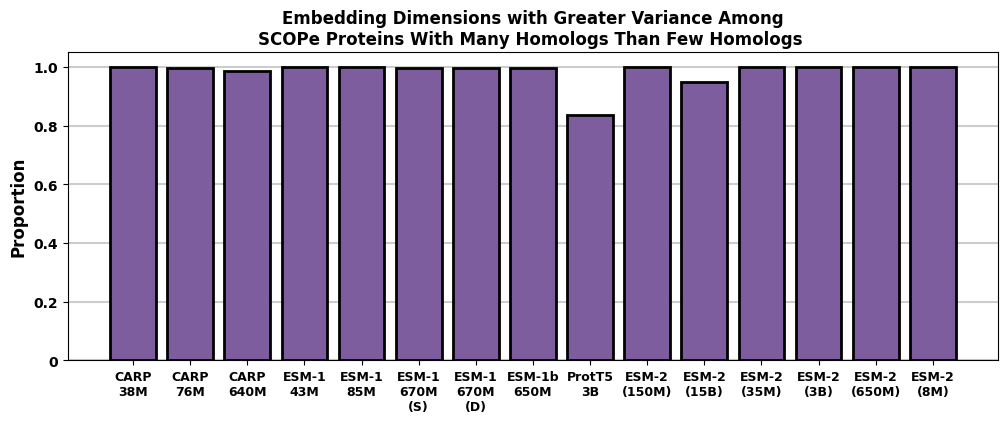

In [95]:
x = np.array(bar_size)

fig, ax = plt.subplots(figsize=(12,4))

ind = np.arange(len(x))
bottom = np.zeros(len(x))


above_color = "#7e5d9e"
below_color = "lightcoral"
colors = ["#7e5d9e", "lightcoral"]


ax.bar(
    ind,
    x[:, 0],
    bottom=bottom,
    label=f"Group {i+1}",
    color=above_color,
    zorder = 100,
    linewidth = 2,
    edgecolor = "black"
)


ax.set_ylim(0, 1)
ax.set_title("Embedding Dimensions with Greater Variance Among\nSCOPe Proteins With Many Homologs Than Few Homologs ", fontweight = "bold")

ax.set_ylabel("Proportion", fontweight = "bold", fontsize = 12)
ax.set_yticks([0, 0.2,0.4,0.6,0.8,1.0] )
ax.set_yticklabels([0, 0.2,0.4,0.6,0.8,1.0], fontweight = "bold", fontsize = 10 )
ax.set_ylim(top = 1.05)

x_ticklabels = list(map(lambda x : m_to_display_c[x].replace(" ", "\n") if "ESM" not in x else x.replace(" ", "\n"),  m_list))

for y_val in ax.get_yticks():
    ax.axhline(y = y_val, zorder = 1, color = "black", alpha = 0.2)
    
ax.set_xticks(ind)
ax.set_xticklabels(x_ticklabels, fontweight = "bold", fontsize = 9 )

In [96]:
data_out_df = pd.DataFrame({
    "model" : list(map(lambda x : x.replace("\n", " "), x_ticklabels)),
    "bar_height" : x[:, 0]
})

data_out_df.to_csv(data_output_path + "fig_E8/data_E8d.csv", index = False)
data_out_df

,model,bar_height
0,CARP 38M,1.000000
1,CARP 76M,0.997070
2,CARP 640M,0.986719
3,ESM-1 43M,1.000000
4,ESM-1 85M,1.000000
5,ESM-1 670M (S),0.996875
6,ESM-1 670M (D),0.996094
7,ESM-1b 650M,0.996875
8,ProtT5 3B,0.834961
9,ESM-2 (150M),0.998437
